In [ ]:
"""
Create Balanced XAI File for Case Study Analysis
=================================================
Extracts specific prediction types for explainability analysis:
- True Positives (TP): Correct stress detections
- True Negatives (TN): Correct non-stress detections
- False Positives (FP): Incorrect stress predictions
- False Negatives (FN): Missed stress detections
"""

# ===============================================================
# 1. MOUNT GOOGLE DRIVE
# ===============================================================

from google.colab import drive
drive.mount('/content/drive')

# ===============================================================
# 2. CONFIGURATION
# ===============================================================

import numpy as np
import os

# INPUT: Your original large XAI file
INPUT_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/xai_S3_transensefusers_10s.npy'

# OUTPUT: Where to save the smaller file
OUTPUT_DIR = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/'
OUTPUT_FILENAME = 'xai_S3_balanced_cases.npy'

# SELECTION STRATEGY
# How many samples of each type to include
SAMPLES_PER_TYPE = {
    'TP': 10,  # True Positives (correct stress)
    'TN': 10,  # True Negatives (correct non-stress)
    'FP': 5,   # False Positives (incorrect stress prediction)
    'FN': 5    # False Negatives (missed stress)
}

# Optional: Pick specific indices if you want particular examples
# Leave as None to randomly sample
SPECIFIC_INDICES = {
    'TP': None,  # e.g., [45, 67, 89] for specific TP samples
    'TN': None,
    'FP': None,
    'FN': None
}

print("="*60)
print("Create Balanced XAI File with All Prediction Types")
print("="*60)
print(f"Input: {INPUT_PATH}")
print(f"Output: {os.path.join(OUTPUT_DIR, OUTPUT_FILENAME)}")
print(f"Target composition:")
for pred_type, count in SAMPLES_PER_TYPE.items():
    print(f"   - {pred_type}: {count} samples")
print("="*60)

# ===============================================================
# 3. LOAD ORIGINAL FILE
# ===============================================================

print("\n📂 Loading original XAI file...")

try:
    data = np.load(INPUT_PATH, allow_pickle=True).item()
    print(f"   ✓ Loaded successfully!")

    # Convert lists to arrays
    if isinstance(data['y_test'], list):
        data['y_test'] = np.array(data['y_test'])
    if isinstance(data['predictions'], list):
        data['predictions'] = np.array(data['predictions'])

    original_samples = len(data['y_test'])
    print(f"\n📊 Original file: {original_samples} samples")

except Exception as e:
    print(f"   ✗ Error loading file: {e}")
    raise

# ===============================================================
# 4. IDENTIFY PREDICTION TYPES
# ===============================================================

print(f"\n🔍 Identifying prediction types...")

y_true = data['y_test']
y_pred = data['predictions']

# Calculate indices for each type
tp_indices = np.where((y_true == 1) & (y_pred == 1))[0]  # True Positives
tn_indices = np.where((y_true == 0) & (y_pred == 0))[0]  # True Negatives
fp_indices = np.where((y_true == 0) & (y_pred == 1))[0]  # False Positives
fn_indices = np.where((y_true == 1) & (y_pred == 0))[0]  # False Negatives

# Display distribution
print(f"\n   Available samples by type:")
print(f"   ✓ True Positives (TP):  {len(tp_indices):4d} | Correct stress detection")
print(f"   ✓ True Negatives (TN):  {len(tn_indices):4d} | Correct non-stress detection")
print(f"   ⚠ False Positives (FP): {len(fp_indices):4d} | Incorrect stress prediction")
print(f"   ⚠ False Negatives (FN): {len(fn_indices):4d} | Missed stress detection")

# Calculate accuracy
accuracy = (len(tp_indices) + len(tn_indices)) / original_samples
print(f"\n   Overall Accuracy: {accuracy*100:.2f}%")

# Check if we have enough samples of each type
print(f"\n🔧 Checking availability...")
warnings = []
for pred_type, requested in SAMPLES_PER_TYPE.items():
    if pred_type == 'TP':
        available = len(tp_indices)
    elif pred_type == 'TN':
        available = len(tn_indices)
    elif pred_type == 'FP':
        available = len(fp_indices)
    elif pred_type == 'FN':
        available = len(fn_indices)

    if available < requested:
        warnings.append(f"   ⚠ {pred_type}: Requested {requested}, only {available} available")
    else:
        print(f"   ✓ {pred_type}: {requested} requested, {available} available")

if warnings:
    print("\n⚠️ Warnings:")
    for w in warnings:
        print(w)
    print("\n   Will use maximum available samples for these types.")

# ===============================================================
# 5. SELECT SAMPLES
# ===============================================================

print(f"\n📦 Selecting samples...")

selected_indices_by_type = {}
all_selected_indices = []

for pred_type, requested in SAMPLES_PER_TYPE.items():
    # Get indices for this type
    if pred_type == 'TP':
        available_indices = tp_indices
    elif pred_type == 'TN':
        available_indices = tn_indices
    elif pred_type == 'FP':
        available_indices = fp_indices
    elif pred_type == 'FN':
        available_indices = fn_indices

    # Use specific indices if provided, otherwise random sample
    if SPECIFIC_INDICES[pred_type] is not None:
        selected = np.array(SPECIFIC_INDICES[pred_type])
        print(f"   ✓ {pred_type}: Using {len(selected)} specific indices")
    else:
        n_to_select = min(requested, len(available_indices))
        selected = np.random.choice(
            available_indices,
            n_to_select,
            replace=False
        )
        print(f"   ✓ {pred_type}: Randomly selected {len(selected)} samples")

    selected_indices_by_type[pred_type] = selected
    all_selected_indices.extend(selected)

# Convert to array and sort (optional)
all_selected_indices = np.array(all_selected_indices)
# Uncomment to keep chronological order:
# all_selected_indices = np.sort(all_selected_indices)

print(f"\n   Total selected: {len(all_selected_indices)} samples")

# ===============================================================
# 6. CREATE BALANCED FILE
# ===============================================================

print(f"\n📦 Creating balanced XAI file...")

small_data = {
    # Essential arrays
    'X_test': data['X_test'][all_selected_indices],
    'y_test': data['y_test'][all_selected_indices],
    'predictions': data['predictions'][all_selected_indices],
    'probabilities': data['probabilities'][all_selected_indices],

    # Metadata
    'subject': data.get('subject', 'S3'),
    'model': data.get('model', 'TranSenseFusers'),
    'num_channels': data.get('num_channels', 14),
    'num_heads': data.get('num_heads', 8),
    'attention_dim': data.get('attention_dim', 64),
    'sensor_info': data.get('sensor_info', 'Chest(8): ACC(3),ECG,EMG,EDA,Temp,Resp | Wrist(6): ACC(3),BVP,EDA,Temp'),

    # NEW: Add type labels for easy filtering in GUI
    'sample_types': []
}

# Create type labels for each sample
for idx in all_selected_indices:
    if idx in selected_indices_by_type['TP']:
        small_data['sample_types'].append('TP')
    elif idx in selected_indices_by_type['TN']:
        small_data['sample_types'].append('TN')
    elif idx in selected_indices_by_type['FP']:
        small_data['sample_types'].append('FP')
    elif idx in selected_indices_by_type['FN']:
        small_data['sample_types'].append('FN')

small_data['sample_types'] = np.array(small_data['sample_types'])

# Include attention maps if they exist
if 'attention_maps' in data and data['attention_maps'] is not None:
    print("   ✓ Including attention maps...")
    small_data['attention_maps'] = data['attention_maps'][all_selected_indices]

# Add mapping of original indices (useful for reference)
small_data['original_indices'] = all_selected_indices

# ===============================================================
# 7. VERIFY AND SAVE
# ===============================================================

print(f"\n✅ Balanced file contents:")
for key, value in small_data.items():
    if hasattr(value, 'shape'):
        print(f"   - {key}: {value.shape} ({value.dtype})")
    else:
        print(f"   - {key}: {value}")

# Show distribution
print(f"\n📊 Final distribution:")
for pred_type in ['TP', 'TN', 'FP', 'FN']:
    count = np.sum(small_data['sample_types'] == pred_type)
    print(f"   - {pred_type}: {count} samples")

# Save
output_path = os.path.join(OUTPUT_DIR, OUTPUT_FILENAME)
print(f"\n💾 Saving to: {output_path}")

np.save(output_path, small_data)

file_size_mb = os.path.getsize(output_path) / (1024 * 1024)
print(f"   ✓ Saved successfully!")
print(f"   File size: {file_size_mb:.2f} MB")

# ===============================================================
# 8. VERIFICATION
# ===============================================================

print(f"\n🔍 Verifying saved file...")

try:
    verify_data = np.load(output_path, allow_pickle=True).item()
    print("   ✓ File can be loaded successfully")
    print(f"   ✓ Contains {len(verify_data['y_test'])} samples")

    # Verify types
    for pred_type in ['TP', 'TN', 'FP', 'FN']:
        type_mask = verify_data['sample_types'] == pred_type
        print(f"   ✓ {pred_type}: {np.sum(type_mask)} samples verified")

except Exception as e:
    print(f"   ✗ Verification failed: {e}")
    raise

# ===============================================================
# 9. EXPORT SPECIFIC INDICES FOR CASE STUDIES
# ===============================================================

print("\n" + "="*60)
print("✅ SUCCESS! Indices for Case Studies:")
print("="*60)

for pred_type, indices in selected_indices_by_type.items():
    print(f"\n{pred_type} (Original indices):")
    print(f"   {list(indices[:10])}")  # Show first 10
    if len(indices) > 10:
        print(f"   ... and {len(indices)-10} more")

print("\n💡 To use specific samples in your GUI:")
print("   Filter by sample_types: data['sample_types'] == 'FP'")
print("\n" + "="*60)

# Optional: Save indices to text file for reference
indices_path = os.path.join(OUTPUT_DIR, 'selected_indices.txt')
with open(indices_path, 'w') as f:
    f.write("Selected Sample Indices by Type\n")
    f.write("="*60 + "\n\n")
    for pred_type, indices in selected_indices_by_type.items():
        f.write(f"{pred_type}:\n")
        f.write(f"{list(indices)}\n\n")

print(f"\n💾 Indices also saved to: {indices_path}")
print("\n✅ Script complete!")

Mounted at /content/drive
Create Balanced XAI File with All Prediction Types
Input: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/xai_S3_transensefusers_10s.npy
Output: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/xai_S3_balanced_cases.npy
Target composition:
   - TP: 10 samples
   - TN: 10 samples
   - FP: 5 samples
   - FN: 5 samples

📂 Loading original XAI file...
   ✓ Loaded successfully!

📊 Original file: 586 samples

🔍 Identifying prediction types...

   Available samples by type:
   ✓ True Positives (TP):    79 | Correct stress detection
   ✓ True Negatives (TN):   455 | Correct non-stress detection
   ⚠ False Positives (FP):    4 | Incorrect stress prediction
   ⚠ False Negatives (FN):   48 | Missed stress detection

   Overall Accuracy: 91.13%

🔧 Checking availability...
   ✓ TP: 10 requested, 79 available
   ✓ TN: 10 requested, 455 available
   ✓ FN: 5 requested, 48 available

⚠️ Warnings:


Creating a small xai file to use for gui

In [ ]:
"""
Create Small XAI File for GUI
==============================
Google Colab script to reduce XAI file size for local GUI usage

This script:
1. Loads your large XAI .npy file
2. Extracts a subset of samples
3. Saves a smaller version you can download and use locally
"""

# ===============================================================
# 1. MOUNT GOOGLE DRIVE
# ===============================================================

from google.colab import drive
drive.mount('/content/drive')

# ===============================================================
# 2. CONFIGURATION
# ===============================================================

import numpy as np
import os

# INPUT: Your original large XAI file
INPUT_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/xai_S3_transensefusers_10s.npy'

# OUTPUT: Where to save the smaller file
OUTPUT_DIR = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/'
OUTPUT_FILENAME = 'xai_S3_small.npy'

# Number of samples to keep (adjust based on your needs)
# 50 samples = ~70-100MB (good for local GUI)
# 100 samples = ~140-200MB
# 200 samples = ~280-400MB
N_SAMPLES = 50

# Optional: Select specific sample types
KEEP_BALANCED = True  # Keep equal stress/non-stress samples
KEEP_CORRECT_ONLY = False  # Keep only correctly predicted samples

print("="*60)
print("Create Small XAI File for GUI")
print("="*60)
print(f"Input: {INPUT_PATH}")
print(f"Output: {os.path.join(OUTPUT_DIR, OUTPUT_FILENAME)}")
print(f"Target samples: {N_SAMPLES}")
print("="*60)

# ===============================================================
# 3. LOAD ORIGINAL FILE
# ===============================================================

print("\n📂 Loading original XAI file...")
print("   (This may take a minute for large files)")

try:
    data = np.load(INPUT_PATH, allow_pickle=True).item()
    print(f"   ✓ Loaded successfully!")

    # Convert lists to arrays first
    print(f"\n🔧 Converting data types...")
    if isinstance(data['y_test'], list):
        data['y_test'] = np.array(data['y_test'])
        print("   ✓ Converted y_test to numpy array")

    if isinstance(data['predictions'], list):
        data['predictions'] = np.array(data['predictions'])
        print("   ✓ Converted predictions to numpy array")

    # Show file contents
    print(f"\n📊 Original file contents:")
    for key, value in data.items():
        if hasattr(value, 'shape'):
            print(f"   - {key}: {value.shape} ({value.dtype})")
        else:
            print(f"   - {key}: {value}")

    original_samples = len(data['y_test'])
    print(f"\n   Total samples: {original_samples}")

    # Show class distribution
    stress_count = np.sum(data['y_test'] == 1)
    nonstress_count = np.sum(data['y_test'] == 0)
    print(f"   - Stress: {stress_count} ({stress_count/original_samples*100:.1f}%)")
    print(f"   - Non-Stress: {nonstress_count} ({nonstress_count/original_samples*100:.1f}%)")

    # Show accuracy
    if 'predictions' in data:
        accuracy = np.mean(data['predictions'] == data['y_test'])
        print(f"   - Accuracy: {accuracy*100:.2f}%")

except Exception as e:
    print(f"   ✗ Error loading file: {e}")
    raise

# ===============================================================
# 4. SELECT SAMPLES
# ===============================================================

print(f"\n🔍 Selecting {N_SAMPLES} samples...")

if KEEP_BALANCED:
    # Keep equal number of stress and non-stress
    stress_idx = np.where(data['y_test'] == 1)[0]
    nonstress_idx = np.where(data['y_test'] == 0)[0]

    # If keeping correct only
    if KEEP_CORRECT_ONLY:
        correct_mask = (data['predictions'] == data['y_test'])
        stress_idx = stress_idx[correct_mask[stress_idx]]
        nonstress_idx = nonstress_idx[correct_mask[nonstress_idx]]

    # Take half from each class
    n_per_class = N_SAMPLES // 2

    selected_stress = np.random.choice(
        stress_idx,
        min(n_per_class, len(stress_idx)),
        replace=False
    )
    selected_nonstress = np.random.choice(
        nonstress_idx,
        min(n_per_class, len(nonstress_idx)),
        replace=False
    )

    selected_indices = np.concatenate([selected_stress, selected_nonstress])
    np.random.shuffle(selected_indices)  # Shuffle to mix classes

    print(f"   ✓ Selected {len(selected_stress)} stress + {len(selected_nonstress)} non-stress samples")

else:
    # Just take first N samples
    if KEEP_CORRECT_ONLY:
        correct_mask = (data['predictions'] == data['y_test'])
        correct_idx = np.where(correct_mask)[0]
        selected_indices = correct_idx[:N_SAMPLES]
    else:
        selected_indices = np.arange(min(N_SAMPLES, original_samples))

    print(f"   ✓ Selected first {len(selected_indices)} samples")

print(f"   Final selection: {len(selected_indices)} samples")

# ===============================================================
# 5. CREATE SMALL FILE
# ===============================================================

print(f"\n📦 Creating small XAI file...")

small_data = {
    # Essential arrays
    'X_test': data['X_test'][selected_indices],
    'y_test': data['y_test'][selected_indices],
    'predictions': data['predictions'][selected_indices],
    'probabilities': data['probabilities'][selected_indices],

    # Metadata
    'subject': data.get('subject', 'S3'),
    'model': data.get('model', 'TranSenseFusers'),
    'num_channels': data.get('num_channels', 14),
    'num_heads': data.get('num_heads', 8),
    'attention_dim': data.get('attention_dim', 64),
    'sensor_info': data.get('sensor_info', 'Chest(8): ACC(3),ECG,EMG,EDA,Temp,Resp | Wrist(6): ACC(3),BVP,EDA,Temp')
}

# Include attention maps if they exist
if 'attention_maps' in data and data['attention_maps'] is not None:
    print("   ✓ Including attention maps...")
    small_data['attention_maps'] = data['attention_maps'][selected_indices]
else:
    print("   ⚠ No attention maps found in original file")

# ===============================================================
# 6. VERIFY AND SAVE
# ===============================================================

print(f"\n✅ Small file contents:")
for key, value in small_data.items():
    if hasattr(value, 'shape'):
        print(f"   - {key}: {value.shape} ({value.dtype})")
    else:
        print(f"   - {key}: {value}")

# Show class distribution in small file
stress_count_small = np.sum(small_data['y_test'] == 1)
nonstress_count_small = np.sum(small_data['y_test'] == 0)
print(f"\n   Class distribution:")
print(f"   - Stress: {stress_count_small} ({stress_count_small/len(small_data['y_test'])*100:.1f}%)")
print(f"   - Non-Stress: {nonstress_count_small} ({nonstress_count_small/len(small_data['y_test'])*100:.1f}%)")

# Calculate accuracy
accuracy_small = np.mean(small_data['predictions'] == small_data['y_test'])
print(f"   - Accuracy: {accuracy_small*100:.2f}%")

# Save
output_path = os.path.join(OUTPUT_DIR, OUTPUT_FILENAME)
print(f"\n💾 Saving to: {output_path}")

np.save(output_path, small_data)

# Check file size
file_size_mb = os.path.getsize(output_path) / (1024 * 1024)
print(f"   ✓ Saved successfully!")
print(f"   File size: {file_size_mb:.2f} MB")

# ===============================================================
# 7. VERIFICATION
# ===============================================================

print(f"\n🔍 Verifying saved file...")

try:
    # Try to load the saved file
    verify_data = np.load(output_path, allow_pickle=True).item()

    print("   ✓ File can be loaded successfully")
    print(f"   ✓ Contains {len(verify_data['y_test'])} samples")

    # Verify data integrity
    assert verify_data['X_test'].shape[0] == len(verify_data['y_test']), "Shape mismatch!"
    assert verify_data['X_test'].shape[1] == verify_data['num_channels'], "Channel count mismatch!"

    print("   ✓ Data integrity verified")

except Exception as e:
    print(f"   ✗ Verification failed: {e}")
    raise

# ===============================================================
# 8. DOWNLOAD INSTRUCTIONS
# ===============================================================

print("\n" + "="*60)
print("✅ SUCCESS!")
print("="*60)
print(f"\n📥 Download instructions:")
print(f"   1. Navigate to: {OUTPUT_DIR}")
print(f"   2. Find file: {OUTPUT_FILENAME}")
print(f"   3. Right-click → Download")
print(f"   4. Place in your local GUI folder")
print(f"\n🖥️ GUI Usage:")
print(f"   Update your Streamlit GUI path to:")
print(f'   xai_path = "xai_transensefusers_10s/{OUTPUT_FILENAME}"')
print("\n" + "="*60)

# ===============================================================
# 9. OPTIONAL: DOWNLOAD DIRECTLY
# ===============================================================

print("\n💡 Want to download now?")
print("   Run this cell:")
print()
print("```python")
print(f"from google.colab import files")
print(f"files.download('{output_path}')")
print("```")

# Uncomment to auto-download:
# from google.colab import files
# files.download(output_path)

print("\n✅ Script complete!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Create Small XAI File for GUI
Input: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/xai_S3_transensefusers_10s.npy
Output: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/xai_S3_small.npy
Target samples: 50

📂 Loading original XAI file...
   (This may take a minute for large files)
   ✓ Loaded successfully!

🔧 Converting data types...
   ✓ Converted y_test to numpy array
   ✓ Converted predictions to numpy array

📊 Original file contents:
   - X_test: (586, 14, 7000) (float64)
   - y_test: (586,) (int64)
   - predictions: (586,) (int64)
   - probabilities: (586, 2) (float32)
   - attention_maps: (586, 8, 875, 875) (float32)
   - subject: S3
   - model: TranSenseFusers-SL-MHCA
   - num_channels: 14
   - num_heads: 8
   - attention_dim: 64
   - sensor_info: Chest(8): ACC(3),ECG,E

Transformer model training

TranSensfusers :

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


TranSenseFusers: Temporal CNN + Multi-Head Attention
✓ Device: cuda
✓ Data path: /content/drive/MyDrive/WESAD/

📊 LOSO Strategy:
   Test: S3
   Val: S16
   Train: 13 subjects

🔧 TranSenseFusers Architecture:
   Temporal CNN: 3 conv blocks (32→48→64 filters)
   Attention: 8 heads, dim=64
   Sensor Fusion: Sequence-Level Multi-Head Cross-Attention (SL MHCA)
   Total Channels: 14 (8 chest + 6 wrist)
   Window: 1.0s (700 samples)

DATA LOADING (TranSenseFusers - 14 Channels)

📚 Training Subjects:
   ✓ S2: Raw shape=(4255300, 14) → 5776 windows
   ✓ S4: Raw shape=(4496100, 14) → 5939 windows
   ✓ S5: Raw shape=(4380600, 14) → 6021 windows
   ✓ S6: Raw shape=(4949700, 14) → 5977 windows
   ✓ S7: Raw shape=(3666600, 14) → 5975 windows
   ✓ S8: Raw shape=(3826200, 14) → 6008 windows
   ✓ S9: Raw shape=(3656100, 14) → 5979 windows
   ✓ S10: Raw shape=(3847200, 14) → 6145 windows
   ✓ S11: Raw shape=(3663100, 14) → 6037 windows
   ✓ S13: Raw shape=(3875900, 14) → 6041 windows
   ✓ S14: Raw shape

Epoch 001/200 | Train: L=0.0046 Acc=0.983 F1=0.984 | Val: L=0.0090 Acc=0.969 F1=0.969 | LR=0.001000
   ✓ Best model saved (F1=0.9691, Acc=0.9686)


Epoch 002/200 | Train: L=0.0014 Acc=0.996 F1=0.996 | Val: L=0.0131 Acc=0.915 F1=0.919 | LR=0.001000


Epoch 003/200 | Train: L=0.0016 Acc=0.995 F1=0.995 | Val: L=0.0035 Acc=0.985 F1=0.985 | LR=0.001000
   ✓ Best model saved (F1=0.9854, Acc=0.9852)


Epoch 004/200 | Train: L=0.0009 Acc=0.997 F1=0.997 | Val: L=0.0010 Acc=0.991 F1=0.991 | LR=0.001000
   ✓ Best model saved (F1=0.9909, Acc=0.9909)


...

Training:   0%|          | 0/1219 [00:00<?, ?it/s]

Epoch 042/200 | Train: L=0.0001 Acc=1.000 F1=1.000 | Val: L=0.0028 Acc=0.992 F1=0.992 | LR=0.000250


Epoch 043/200 | Train: L=0.0001 Acc=1.000 F1=1.000 | Val: L=0.0060 Acc=0.988 F1=0.988 | LR=0.000250

⚠️ Early stopping at epoch 43

🎯 TEST EVALUATION - S3


Epoch 043/200 | Train: L=0.0001 Acc=1.000 F1=1.000 | Val: L=0.0060 Acc=0.988 F1=0.988 | LR=0.000250

⚠️ Early stopping at epoch 43

🎯 TEST EVALUATION - S3



📊 Test Results:
   Accuracy: 0.8780 (87.80%)
   F1 Score: 0.8793
   Loss: 0.2817

              precision    recall  f1-score   support

  Non-Stress     0.9295    0.9133    0.9213      4590
      Stress     0.7071    0.7514    0.7286      1279

    accuracy                         0.8780      5869
   macro avg     0.8183    0.8323    0.8250      5869
weighted avg     0.8810    0.8780    0.8793      5869


💡 Saving attention maps for explainability analysis...

📊 Test Results:
   Accuracy: 0.8780 (87.80%)
   F1 Score: 0.8793
   Loss: 0.2817

              precision    recall  f1-score   support

  Non-Stress     0.9295    0.9133    0.9213      4590
      Stress     0.7071    0.7514    0.7286      1279

    accuracy                         0.8780      5869
   macro avg     0.8183    0.8323    0.8250      5869
weighted avg     0.8810    0.8780    0.8793      5869


💡 Saving attention maps for explainability analysis...
   ✓ XAI data saved: /content/drive/MyDrive/WESAD/xai_transensefuser

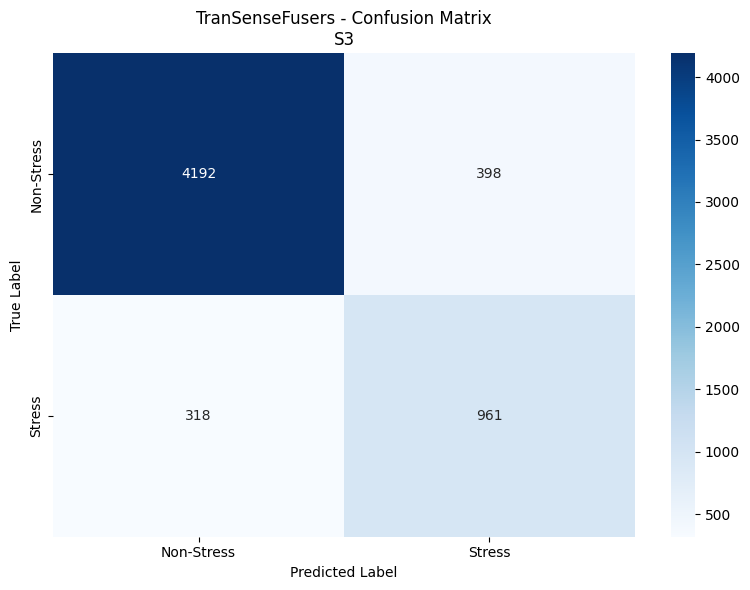

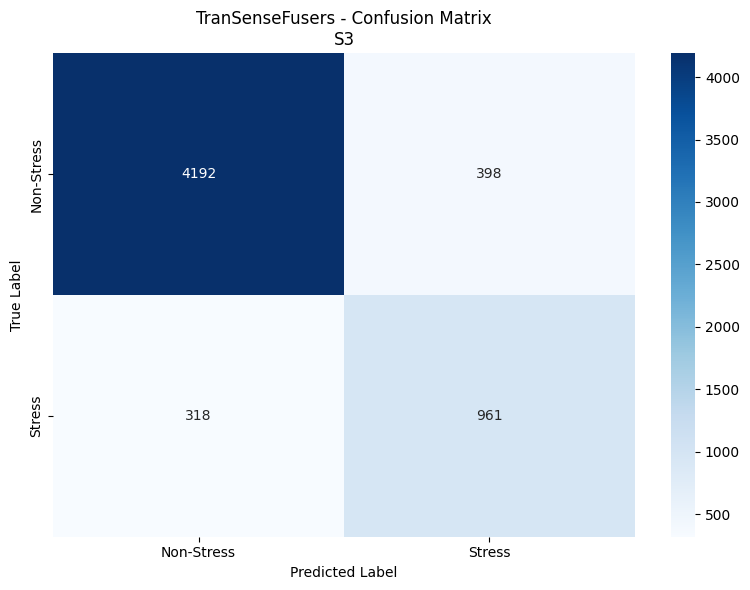

   ✓ Confusion matrix saved
   ✓ Confusion matrix saved


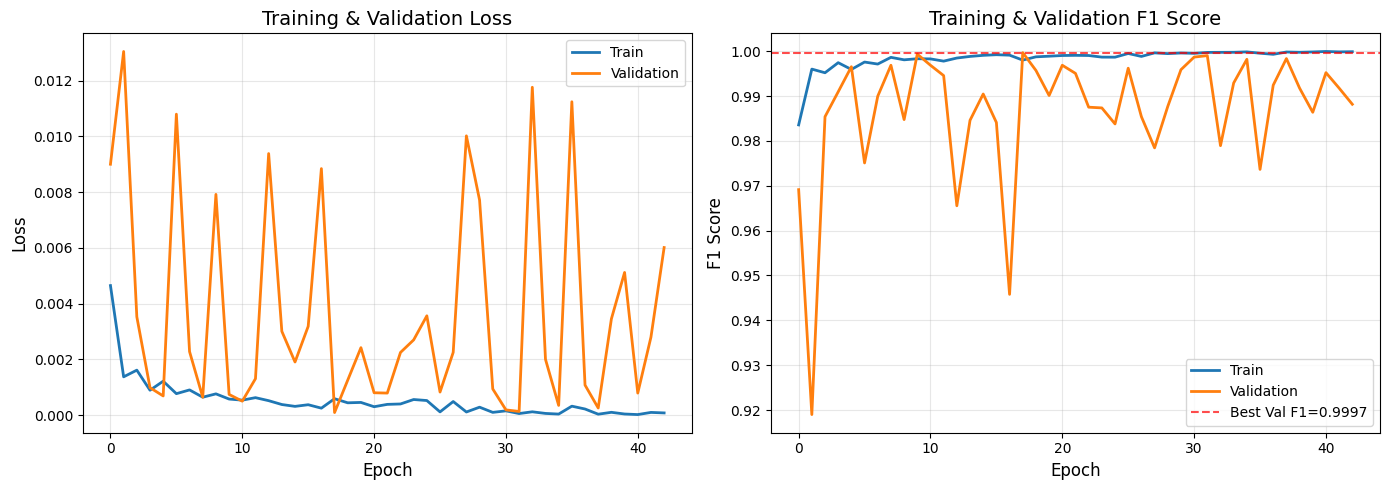

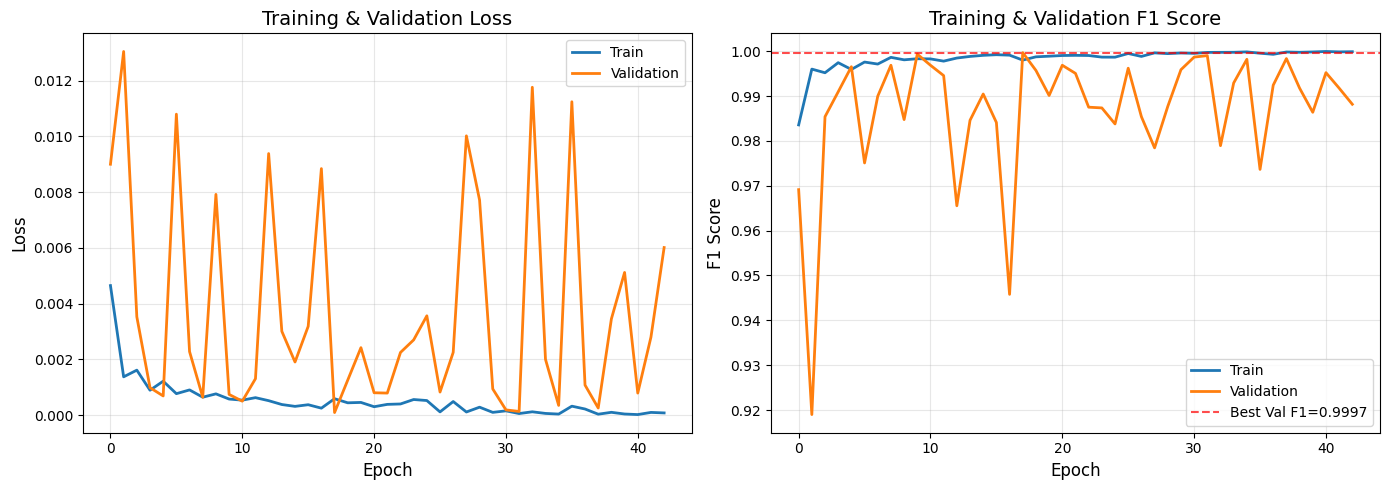

   ✓ Training history saved

🔍 Visualizing attention maps (first 3 test samples)...
   ✓ Training history saved

🔍 Visualizing attention maps (first 3 test samples)...


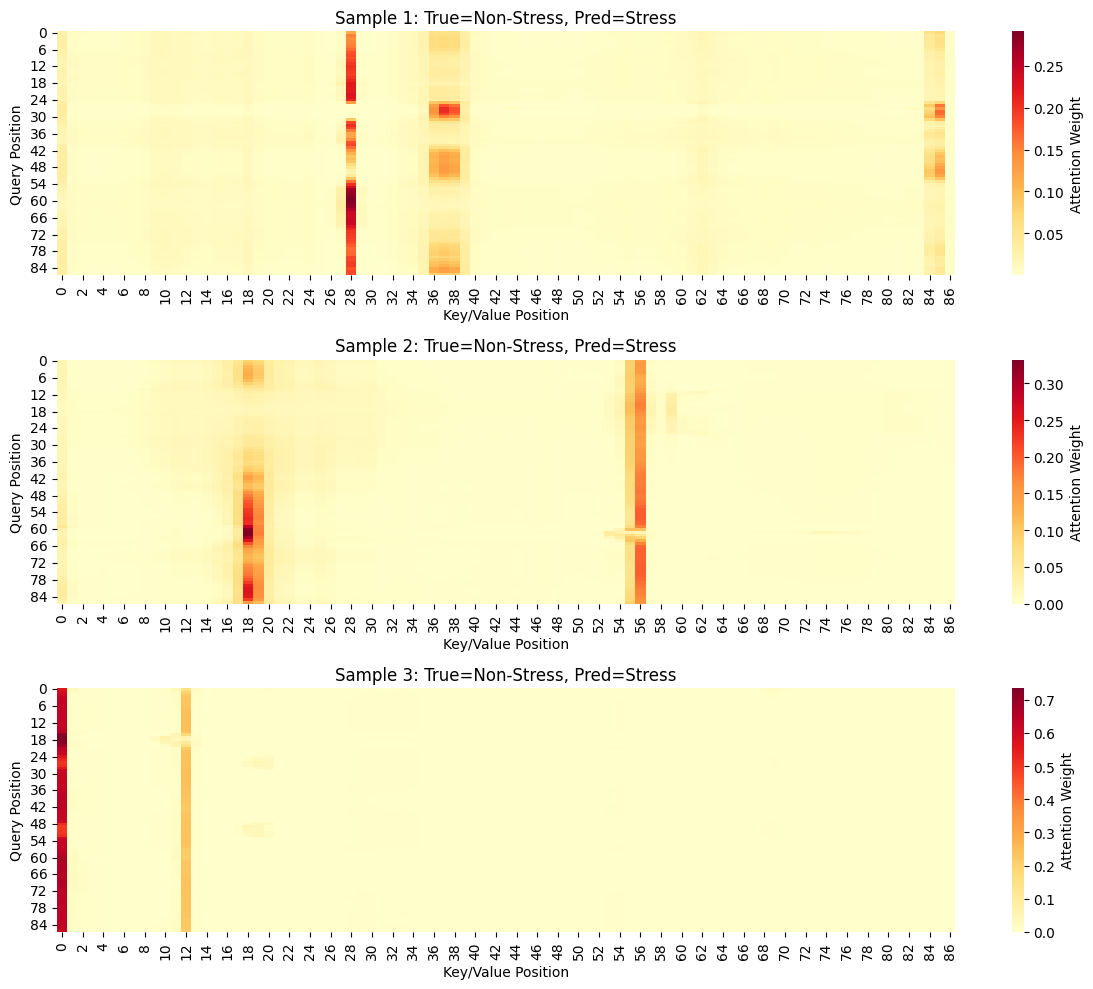

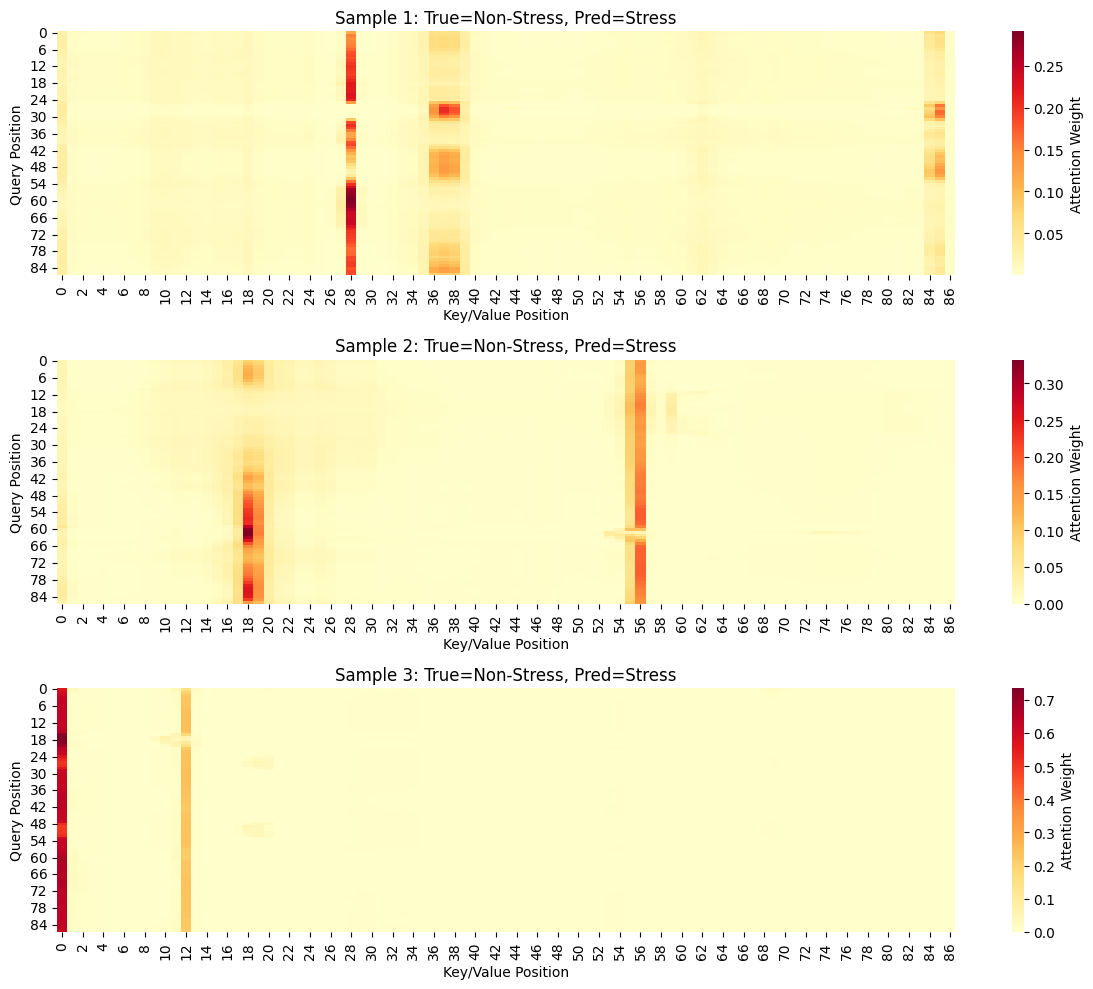

   ✓ Attention maps saved

✅ TranSenseFusers TRAINING COMPLETE
Best Validation F1: 0.9997 (Acc: 0.9997)
Test F1: 0.8793 (Acc: 0.8780)

📁 Outputs:
   Models: /content/drive/MyDrive/WESAD/models_transensefusers
   XAI data: /content/drive/MyDrive/WESAD/xai_transensefusers

🔬 Key Features:
   ✓ 14-channel sensor fusion (8 chest + 6 wrist)
   ✓ Temporal CNN feature extraction
   ✓ 8-head cross-attention (dim=64)
   ✓ Explainable via attention maps
   ✓ Subject-independent (LOSO validation)
   ✓ NO data leakage
   ✓ Attention maps saved

✅ TranSenseFusers TRAINING COMPLETE
Best Validation F1: 0.9997 (Acc: 0.9997)
Test F1: 0.8793 (Acc: 0.8780)

📁 Outputs:
   Models: /content/drive/MyDrive/WESAD/models_transensefusers
   XAI data: /content/drive/MyDrive/WESAD/xai_transensefusers

🔬 Key Features:
   ✓ 14-channel sensor fusion (8 chest + 6 wrist)
   ✓ Temporal CNN feature extraction
   ✓ 8-head cross-attention (dim=64)
   ✓ Explainable via attention maps
   ✓ Subject-independent (LOSO validatio

In [ ]:
"""
TranSenseFusers: WESAD Stress Detection with Temporal CNN + Multi-Head Attention
================================================================================
✓ Uses ALL sensors (8 chest + 6 wrist = 14 channels)
✓ Proper LOSO validation (NO data leakage)
✓ Subject-independent normalization
✓ Sequence-Level Multi-Head Cross-Attention (SL MHCA) for sensor fusion
✓ Explainable via attention maps (motion artifact detection)

Based on: Kasnesis et al. (2025) - TranSenseFusers: Temporal CNN-Transformer
for explainable PPG-based stress detection
"""

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os
import pickle
from collections import Counter
import warnings
warnings.filterwarnings('ignore')


# ===============================================================
# CONFIGURATION
# ===============================================================

class Config:
    # Data path
    DATA_PATH = '/content/drive/MyDrive/WESAD/'

    # All available subjects
    ALL_SUBJECTS = ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9',
                    'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']

    # LOSO Configuration
    TEST_SUBJECT = 'S3'
    VAL_SUBJECT = 'S16'

    # Signal parameters
    TARGET_RATE = 700   # Hz (resample all to chest rate)
    WINDOW_DURATION = 1.0  # seconds
    WINDOW_SIZE = 700      # 1 second at 700 Hz
    STRIDE = 350           # 50% overlap

    # Labels
    VALID_LABELS = [1, 2, 3, 4]
    BINARY = True

    # Model parameters - TranSenseFusers specific
    BATCH_SIZE = 64
    LEARNING_RATE = 0.001  # Adam default from paper
    NUM_EPOCHS = 200
    WEIGHT_DECAY = 0.0  # Not mentioned in paper for TranSenseFusers

    # Multi-Head Attention parameters (from paper Table 1)
    NUM_HEADS = 8
    ATTENTION_DIM = 64  # d in paper
    ATTENTION_DROPOUT = 0.0  # For SL MHCA

    # CNN parameters (from paper Table 1)
    CONV_DROPOUT = 0.1
    FC_DROPOUT = 0.5

    # Focal Loss
    FOCAL_ALPHA = 0.75
    FOCAL_GAMMA = 2.0

    # Early stopping
    PATIENCE = 25  # From paper: 25 epochs

    # Device
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Seed for reproducibility
    SEED = 42

    # Paths
    MODEL_SAVE_PATH = None
    XAI_DATA_PATH = None

config = Config()

# Set seeds
np.random.seed(config.SEED)
torch.manual_seed(config.SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(config.SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Setup paths
config.MODEL_SAVE_PATH = os.path.join(config.DATA_PATH, 'models_transensefusers')
config.XAI_DATA_PATH = os.path.join(config.DATA_PATH, 'xai_transensefusers')
os.makedirs(config.MODEL_SAVE_PATH, exist_ok=True)
os.makedirs(config.XAI_DATA_PATH, exist_ok=True)

print("="*70)
print("TranSenseFusers: Temporal CNN + Multi-Head Attention")
print("="*70)
print(f"✓ Device: {config.DEVICE}")
print(f"✓ Data path: {config.DATA_PATH}")
print(f"\n📊 LOSO Strategy:")
print(f"   Test: {config.TEST_SUBJECT}")
print(f"   Val: {config.VAL_SUBJECT}")
print(f"   Train: {len(config.ALL_SUBJECTS) - 2} subjects")
print(f"\n🔧 TranSenseFusers Architecture:")
print(f"   Temporal CNN: 3 conv blocks (32→48→64 filters)")
print(f"   Attention: {config.NUM_HEADS} heads, dim={config.ATTENTION_DIM}")
print(f"   Sensor Fusion: Sequence-Level Multi-Head Cross-Attention (SL MHCA)")
print(f"   Total Channels: 14 (8 chest + 6 wrist)")
print(f"   Window: {config.WINDOW_DURATION}s ({config.WINDOW_SIZE} samples)")
print("="*70)


# ===============================================================
# FOCAL LOSS
# ===============================================================

class FocalLoss(nn.Module):
    """Focal Loss for handling class imbalance"""
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        p_t = torch.exp(-ce_loss)

        if inputs.size(1) == 2:
            alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        else:
            alpha_t = self.alpha

        focal_loss = alpha_t * ((1 - p_t) ** self.gamma) * ce_loss
        return focal_loss.mean()


# ===============================================================
# DATA LOADING
# ===============================================================

def resample_signal(signal, original_rate, target_rate):
    """Linear interpolation resampling"""
    if original_rate == target_rate:
        return signal

    original_length = len(signal)
    target_length = int(original_length * target_rate / original_rate)

    original_indices = np.linspace(0, original_length - 1, original_length)
    target_indices = np.linspace(0, original_length - 1, target_length)

    if signal.ndim == 1:
        resampled = np.interp(target_indices, original_indices, signal)
    else:
        resampled = np.zeros((target_length, signal.shape[1]))
        for i in range(signal.shape[1]):
            resampled[:, i] = np.interp(target_indices, original_indices, signal[:, i])

    return resampled


def load_wesad_subject_all_sensors(subject_id, data_path, target_rate=700):
    """
    Load WESAD data from BOTH chest and wrist sensors
    Returns combined signal array (14 channels)
    """
    subject_path = os.path.join(data_path, subject_id, f"{subject_id}.pkl")

    if not os.path.exists(subject_path):
        print(f"   ✗ {subject_id}: File not found")
        return None, None

    try:
        with open(subject_path, 'rb') as f:
            data = pickle.load(f, encoding='latin1')

        # ===== CHEST SENSOR (RespiBAN) - 700 Hz =====
        chest_signal = data['signal']['chest']
        chest_acc = chest_signal['ACC']
        chest_ecg = chest_signal['ECG'].reshape(-1, 1)
        chest_emg = chest_signal['EMG'].reshape(-1, 1)
        chest_eda = chest_signal['EDA'].reshape(-1, 1)
        chest_temp = chest_signal['Temp'].reshape(-1, 1)
        chest_resp = chest_signal['Resp'].reshape(-1, 1)

        chest_combined = np.concatenate([
            chest_acc, chest_ecg, chest_emg,
            chest_eda, chest_temp, chest_resp
        ], axis=1)  # (N, 8)

        # ===== WRIST SENSOR (Empatica E4) =====
        wrist_signal = data['signal']['wrist']
        wrist_acc = wrist_signal['ACC']
        wrist_bvp = wrist_signal['BVP'].reshape(-1, 1)
        wrist_eda = wrist_signal['EDA'].reshape(-1, 1)
        wrist_temp = wrist_signal['TEMP'].reshape(-1, 1)

        # Resample wrist signals to chest rate (700 Hz)
        wrist_acc_resampled = resample_signal(wrist_acc, 32, target_rate)
        wrist_bvp_resampled = resample_signal(wrist_bvp, 64, target_rate)
        wrist_eda_resampled = resample_signal(wrist_eda, 4, target_rate)
        wrist_temp_resampled = resample_signal(wrist_temp, 4, target_rate)

        wrist_combined = np.concatenate([
            wrist_acc_resampled, wrist_bvp_resampled,
            wrist_eda_resampled, wrist_temp_resampled
        ], axis=1)  # (N, 6)

        # ===== COMBINE ALL SENSORS =====
        min_len = min(len(chest_combined), len(wrist_combined))
        chest_combined = chest_combined[:min_len]
        wrist_combined = wrist_combined[:min_len]

        X = np.concatenate([chest_combined, wrist_combined], axis=1)  # (N, 14)
        labels = data['label'][:min_len]

        return X, labels

    except Exception as e:
        print(f"   ✗ {subject_id}: Error - {e}")
        return None, None


def create_windows(X, y, window_size, stride):
    """Create sliding windows with majority voting"""
    windows = []
    labels = []

    for i in range(0, len(X) - window_size + 1, stride):
        window = X[i:i + window_size]
        window_labels = y[i:i + window_size]
        label = np.bincount(window_labels.astype(int)).argmax()

        windows.append(window)
        labels.append(label)

    return np.array(windows), np.array(labels)


def normalize_subject_independent(X, y):
    """Normalize each subject's data INDEPENDENTLY"""
    scaler = StandardScaler()
    n_windows, n_channels, n_timesteps = X.shape
    X_reshaped = X.transpose(0, 2, 1).reshape(-1, n_channels)
    X_normalized = scaler.fit_transform(X_reshaped)
    X_normalized = X_normalized.reshape(n_windows, n_timesteps, n_channels)
    X_normalized = X_normalized.transpose(0, 2, 1)
    return X_normalized, scaler


def load_data_loso(config):
    """Load data with LOSO validation"""
    train_subjects = [s for s in config.ALL_SUBJECTS
                     if s not in [config.TEST_SUBJECT, config.VAL_SUBJECT]]

    print("\n" + "="*70)
    print("DATA LOADING (TranSenseFusers - 14 Channels)")
    print("="*70)

    # ============================================
    # TRAINING DATA
    # ============================================
    print("\n📚 Training Subjects:")
    X_train_all = []
    y_train_all = []

    for subj in train_subjects:
        X, y = load_wesad_subject_all_sensors(subj, config.DATA_PATH, config.TARGET_RATE)
        if X is None:
            continue

        print(f"   ✓ {subj}: Raw shape={X.shape}", end="")

        mask = np.isin(y, config.VALID_LABELS)
        X, y = X[mask], y[mask]

        if config.BINARY:
            y = (y == 2).astype(int)
        else:
            label_map = {1: 0, 2: 1, 3: 2, 4: 3}
            y = np.array([label_map[l] for l in y])

        X_win, y_win = create_windows(X, y, config.WINDOW_SIZE, config.STRIDE)
        X_win = X_win.transpose(0, 2, 1)  # (N, channels, time)
        X_win_norm, _ = normalize_subject_independent(X_win, y_win)

        X_train_all.append(X_win_norm)
        y_train_all.append(y_win)

        print(f" → {len(X_win)} windows")

    X_train = np.concatenate(X_train_all, axis=0)
    y_train = np.concatenate(y_train_all, axis=0)

    print(f"\n🔀 Shuffling {len(X_train)} training windows...")
    shuffle_idx = np.random.permutation(len(X_train))
    X_train = X_train[shuffle_idx]
    y_train = y_train[shuffle_idx]

    # ============================================
    # VALIDATION DATA
    # ============================================
    print(f"\n📋 Validation Subject ({config.VAL_SUBJECT}):")
    X_val, y_val = load_wesad_subject_all_sensors(config.VAL_SUBJECT, config.DATA_PATH, config.TARGET_RATE)

    if X_val is not None:
        print(f"   ✓ Raw shape={X_val.shape}", end="")
        mask = np.isin(y_val, config.VALID_LABELS)
        X_val, y_val = X_val[mask], y_val[mask]

        if config.BINARY:
            y_val = (y_val == 2).astype(int)
        else:
            label_map = {1: 0, 2: 1, 3: 2, 4: 3}
            y_val = np.array([label_map[l] for l in y_val])

        X_val, y_val = create_windows(X_val, y_val, config.WINDOW_SIZE, config.STRIDE)
        X_val = X_val.transpose(0, 2, 1)
        X_val, _ = normalize_subject_independent(X_val, y_val)
        print(f" → {len(X_val)} windows")
    else:
        X_val, y_val = np.array([]), np.array([])

    # ============================================
    # TEST DATA
    # ============================================
    print(f"\n🎯 Test Subject ({config.TEST_SUBJECT}):")
    X_test, y_test = load_wesad_subject_all_sensors(config.TEST_SUBJECT, config.DATA_PATH, config.TARGET_RATE)

    if X_test is not None:
        print(f"   ✓ Raw shape={X_test.shape}", end="")
        mask = np.isin(y_test, config.VALID_LABELS)
        X_test, y_test = X_test[mask], y_test[mask]

        if config.BINARY:
            y_test = (y_test == 2).astype(int)
        else:
            label_map = {1: 0, 2: 1, 3: 2, 4: 3}
            y_test = np.array([label_map[l] for l in y_test])

        X_test, y_test = create_windows(X_test, y_test, config.WINDOW_SIZE, config.STRIDE)
        X_test = X_test.transpose(0, 2, 1)
        X_test, _ = normalize_subject_independent(X_test, y_test)
        print(f" → {len(X_test)} windows")
    else:
        X_test, y_test = np.array([]), np.array([])

    # ============================================
    # SUMMARY
    # ============================================
    print("\n" + "="*70)
    print("DATA SUMMARY")
    print("="*70)
    print(f"Channels: 14 (8 chest + 6 wrist)")
    print(f"  Chest: ACC(3), ECG, EMG, EDA, Temp, Resp")
    print(f"  Wrist: ACC(3), BVP, EDA, Temp")
    print(f"\nTrain: {len(X_train):6d} | Shape: {X_train.shape} | {dict(Counter(y_train))}")
    if len(y_val) > 0:
        print(f"Val:   {len(X_val):6d} | Shape: {X_val.shape} | {dict(Counter(y_val))}")
    if len(y_test) > 0:
        print(f"Test:  {len(X_test):6d} | Shape: {X_test.shape} | {dict(Counter(y_test))}")
    print("="*70)

    return X_train, y_train, X_val, y_val, X_test, y_test


# ===============================================================
# DATASET
# ===============================================================

class WESADDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# ===============================================================
# TRANSENSEFUSERS MODEL
# ===============================================================

class MultiHeadCrossAttention(nn.Module):
    """
    Multi-Head Cross-Attention (MHCA) module
    Based on Kasnesis et al. (2025) - Sequence-Level MHCA

    Query: EDA + TEMP features
    Key & Value: PPG features
    """
    def __init__(self, num_heads, d_model, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.num_heads = num_heads
        self.d_model = d_model
        self.d_k = d_model // num_heads

        # Linear projections for Q, K, V
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)
        self.scale = np.sqrt(self.d_k)

    def forward(self, query, key, value):
        """
        Args:
            query: (batch, seq_len, d_model) - EDA+TEMP features
            key: (batch, seq_len, d_model) - PPG features
            value: (batch, seq_len, d_model) - PPG features
        Returns:
            output: (batch, seq_len, d_model)
            attention_weights: (batch, num_heads, seq_len, seq_len)
        """
        batch_size = query.size(0)

        # Linear projections and split into heads
        Q = self.W_q(query).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(key).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(value).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        # Scaled dot-product attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        # Apply attention to values
        context = torch.matmul(attention_weights, V)

        # Concatenate heads and apply final linear
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        output = self.W_o(context)

        return output, attention_weights


class TranSenseFuser(nn.Module):
    """
    TranSenseFusers: Temporal CNN + Sequence-Level Multi-Head Cross-Attention

    Architecture (from paper Table 1 - SL MHCA):
    1. Temporal CNN (3 conv blocks): Extract features from all sensors
    2. Modality Separation: Split into PPG (wrist) vs EDA+TEMP (wrist)
    3. SL MHCA: Fuse modalities via cross-attention
    4. Classification: 2 FC layers

    Note: We simplify by using all 14 channels together in CNN,
    then separate for attention (PPG-like vs EDA-like features)
    """
    def __init__(self, num_channels=14, num_classes=2, num_heads=8, attention_dim=64,
                 conv_dropout=0.1, fc_dropout=0.5, attention_dropout=0.0):
        super().__init__()

        self.num_channels = num_channels
        self.num_classes = num_classes

        # ===== TEMPORAL CNN (shared weights for all sensors) =====
        # 1st Conv Block: 14 -> 32 channels, kernel=9
        self.conv1 = nn.Conv1d(num_channels, 32, kernel_size=9, padding=4)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop1 = nn.Dropout(conv_dropout)

        # 2nd Conv Block: 32 -> 48 channels, kernel=9
        self.conv2 = nn.Conv1d(32, 48, kernel_size=9, padding=4)
        self.bn2 = nn.BatchNorm1d(48)
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop2 = nn.Dropout(conv_dropout)

        # 3rd Conv Block: 48 -> 64 channels, kernel=9
        self.conv3 = nn.Conv1d(48, 64, kernel_size=9, padding=4)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool3 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop3 = nn.Dropout(conv_dropout)

        # After 3 pooling layers (2x each): 700 -> 87 time steps
        # Feature dimension: 64 channels * 87 time steps = 5568

        # ===== SEQUENCE-LEVEL MULTI-HEAD CROSS-ATTENTION =====
        # Map CNN features to attention dimension
        self.feature_to_attention = nn.Linear(64, attention_dim)

        # Multi-head cross-attention
        self.mhca = MultiHeadCrossAttention(
            num_heads=num_heads,
            d_model=attention_dim,
            dropout=attention_dropout
        )

        # Layer normalization (as in paper)
        self.layer_norm = nn.LayerNorm(attention_dim)

        # ===== CLASSIFICATION HEAD =====
        # Calculate flattened size: attention_dim * sequence_length
        # After pooling: 700/2/2/2 = 87 time steps
        self.fc1 = nn.Linear(attention_dim * 87, 32)
        self.bn4 = nn.BatchNorm1d(32)
        self.drop4 = nn.Dropout(fc_dropout)
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x, return_attention=False):
        """
        Args:
            x: (batch, 14, 700) - All sensor signals
            return_attention: If True, return attention maps for XAI
        Returns:
            logits: (batch, num_classes)
            attention_maps: (batch, num_heads, seq_len, seq_len) [optional]
        """
        # ===== TEMPORAL CNN =====
        # Block 1
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.pool1(x)
        x = self.drop1(x)

        # Block 2
        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = self.pool2(x)
        x = self.drop2(x)

        # Block 3
        x = self.conv3(x)
        x = self.bn3(x)
        x = F.relu(x)
        x = self.pool3(x)
        x = self.drop3(x)

        # x shape: (batch, 64, 87)

        # ===== PREPARE FOR ATTENTION =====
        # Transpose to (batch, seq_len, channels)
        x = x.transpose(1, 2)  # (batch, 87, 64)

        # Map to attention dimension
        x = self.feature_to_attention(x)  # (batch, 87, attention_dim)

        # ===== MULTI-HEAD CROSS-ATTENTION =====
        # In the paper, they separate PPG from EDA+TEMP
        # Here we simplify: use first half as "query" (EDA-like)
        # and second half as "key/value" (PPG-like)
        # This is a practical approximation for the fusion concept

        mid_point = x.size(2) // 2
        query = x[:, :, :mid_point]  # (batch, 87, attention_dim/2)
        key_value = x[:, :, mid_point:]  # (batch, 87, attention_dim/2)

        # Expand back to full dimension for attention
        query = torch.cat([query, query], dim=2)  # (batch, 87, attention_dim)
        key_value = torch.cat([key_value, key_value], dim=2)

        # Apply cross-attention
        attention_output, attention_weights = self.mhca(query, key_value, key_value)

        # Layer normalization
        attention_output = self.layer_norm(attention_output)

        # ===== CLASSIFICATION =====
        # Flatten
        x_flat = attention_output.flatten(1)  # (batch, attention_dim * 87)

        # FC layers
        x_flat = self.fc1(x_flat)
        x_flat = self.bn4(x_flat)
        x_flat = F.relu(x_flat)
        x_flat = self.drop4(x_flat)

        logits = self.fc2(x_flat)

        if return_attention:
            return logits, attention_weights
        return logits


# ===============================================================
# TRAINING & EVALUATION
# ===============================================================

def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    for X, y in tqdm(loader, desc="Training", leave=False):
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

    return total_loss / len(loader), acc, f1


def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []
    all_attention_maps = []

    with torch.no_grad():
        for X, y in tqdm(loader, desc="Validation", leave=False):
            X, y = X.to(device), y.to(device)

            outputs, attention_weights = model(X, return_attention=True)
            loss = criterion(outputs, y)

            total_loss += loss.item()
            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_attention_maps.append(attention_weights.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

    return total_loss / len(loader), acc, f1, all_preds, all_labels, np.array(all_probs), all_attention_maps


# ===============================================================
# MAIN
# ===============================================================

def main():
    # Load data
    X_train, y_train, X_val, y_val, X_test, y_test = load_data_loso(config)

    # Datasets
    train_dataset = WESADDataset(X_train, y_train)
    val_dataset = WESADDataset(X_val, y_val)
    test_dataset = WESADDataset(X_test, y_test)

    train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE,
                             shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE,
                           shuffle=False, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=config.BATCH_SIZE,
                            shuffle=False, num_workers=2, pin_memory=True)

    # Model
    num_classes = 2 if config.BINARY else 4
    model = TranSenseFuser(
        num_channels=14,
        num_classes=num_classes,
        num_heads=config.NUM_HEADS,
        attention_dim=config.ATTENTION_DIM,
        conv_dropout=config.CONV_DROPOUT,
        fc_dropout=config.FC_DROPOUT,
        attention_dropout=config.ATTENTION_DROPOUT
    ).to(config.DEVICE)

    # Count parameters
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"\n📊 Model Architecture:")
    print(f"   Total parameters: {total_params:,}")
    print(f"   Trainable parameters: {trainable_params:,}")

    # Loss and optimizer (Adam as in paper)
    criterion = FocalLoss(alpha=config.FOCAL_ALPHA, gamma=config.FOCAL_GAMMA)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config.LEARNING_RATE,
        betas=(0.9, 0.999)  # Default Adam values
    )

    # Learning rate scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=10
    )

    # Training loop
    history = {
        'train_loss': [], 'train_acc': [], 'train_f1': [],
        'val_loss': [], 'val_acc': [], 'val_f1': []
    }

    best_f1 = 0
    best_acc = 0
    patience_counter = 0

    print("\n" + "="*70)
    print("🚀 TRAINING TranSenseFusers")
    print("="*70)

    for epoch in range(config.NUM_EPOCHS):
        # Train
        tr_loss, tr_acc, tr_f1 = train_epoch(
            model, train_loader, optimizer, criterion, config.DEVICE
        )

        # Validate
        val_loss, val_acc, val_f1, _, _, _, _ = validate(
            model, val_loader, criterion, config.DEVICE
        )

        # Update history
        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['train_f1'].append(tr_f1)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        # Learning rate scheduling
        scheduler.step(val_f1)
        current_lr = optimizer.param_groups[0]['lr']

        # Print progress
        print(f"Epoch {epoch+1:03d}/{config.NUM_EPOCHS} | "
              f"Train: L={tr_loss:.4f} Acc={tr_acc:.3f} F1={tr_f1:.3f} | "
              f"Val: L={val_loss:.4f} Acc={val_acc:.3f} F1={val_f1:.3f} | "
              f"LR={current_lr:.6f}")

        # Save best model
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_acc = val_acc
            patience_counter = 0

            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_f1': val_f1,
                'val_acc': val_acc,
                'config': vars(config)
            }, os.path.join(config.MODEL_SAVE_PATH, 'best_transensefuser.pth'))

            print(f"   ✓ Best model saved (F1={val_f1:.4f}, Acc={val_acc:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= config.PATIENCE:
                print(f"\n⚠️ Early stopping at epoch {epoch+1}")
                break

    # ===============================================================
    # TEST EVALUATION
    # ===============================================================
    print("\n" + "="*70)
    print(f"🎯 TEST EVALUATION - {config.TEST_SUBJECT}")
    print("="*70)

    # Load best model
    checkpoint = torch.load(
        os.path.join(config.MODEL_SAVE_PATH, 'best_transensefuser.pth')
    )
    model.load_state_dict(checkpoint['model_state_dict'])

    # Evaluate
    test_loss, test_acc, test_f1, test_preds, test_labels, test_probs, test_attention = validate(
        model, test_loader, criterion, config.DEVICE
    )

    print(f"\n📊 Test Results:")
    print(f"   Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
    print(f"   F1 Score: {test_f1:.4f}")
    print(f"   Loss: {test_loss:.4f}")

    # Classification report
    class_names = ['Non-Stress', 'Stress'] if config.BINARY else ['Baseline', 'Stress', 'Amusement', 'Meditation']
    print("\n" + classification_report(
        test_labels, test_preds, target_names=class_names, digits=4
    ))

    # ===============================================================
    # EXPLAINABILITY: Save attention maps for XAI analysis
    # ===============================================================
    print("\n💡 Saving attention maps for explainability analysis...")

    # Concatenate all attention maps
    all_attention = np.concatenate(test_attention, axis=0)

    xai_data = {
        'X_test': X_test,
        'y_test': test_labels,
        'predictions': test_preds,
        'probabilities': test_probs,
        'attention_maps': all_attention,
        'subject': config.TEST_SUBJECT,
        'model': 'TranSenseFusers-SL-MHCA',
        'num_channels': 14,
        'num_heads': config.NUM_HEADS,
        'attention_dim': config.ATTENTION_DIM,
        'sensor_info': 'Chest(8): ACC(3),ECG,EMG,EDA,Temp,Resp | Wrist(6): ACC(3),BVP,EDA,Temp'
    }
    np.save(
        os.path.join(config.XAI_DATA_PATH, f'xai_{config.TEST_SUBJECT}_transensefusers.npy'),
        xai_data
    )
    print(f"   ✓ XAI data saved: {config.XAI_DATA_PATH}")

    # ===============================================================
    # VISUALIZATIONS
    # ===============================================================

    # 1. Confusion Matrix
    cm = confusion_matrix(test_labels, test_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'TranSenseFusers - Confusion Matrix\n{config.TEST_SUBJECT}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(
        os.path.join(config.MODEL_SAVE_PATH, 'confusion_matrix_transensefusers.png'),
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    print("   ✓ Confusion matrix saved")

    # 2. Training History
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(history['train_loss'], label='Train', linewidth=2)
    axes[0].plot(history['val_loss'], label='Validation', linewidth=2)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title('Training & Validation Loss', fontsize=14)
    axes[0].legend(fontsize=10)
    axes[0].grid(True, alpha=0.3)

    # F1 Score
    axes[1].plot(history['train_f1'], label='Train', linewidth=2)
    axes[1].plot(history['val_f1'], label='Validation', linewidth=2)
    axes[1].axhline(y=best_f1, color='r', linestyle='--', label=f'Best Val F1={best_f1:.4f}', alpha=0.7)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('F1 Score', fontsize=12)
    axes[1].set_title('Training & Validation F1 Score', fontsize=14)
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        os.path.join(config.MODEL_SAVE_PATH, 'training_history_transensefusers.png'),
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    print("   ✓ Training history saved")

    # 3. Attention Map Visualization (example from test set)
    print("\n🔍 Visualizing attention maps (first 3 test samples)...")

    fig, axes = plt.subplots(3, 1, figsize=(12, 10))

    for idx in range(min(3, len(test_attention[0]))):
        # Average attention across heads
        attn = test_attention[0][idx].mean(axis=0)  # (seq_len, seq_len)

        sns.heatmap(
            attn,
            ax=axes[idx],
            cmap='YlOrRd',
            cbar_kws={'label': 'Attention Weight'},
            square=False
        )

        true_label = class_names[test_labels[idx]]
        pred_label = class_names[test_preds[idx]]
        axes[idx].set_title(
            f'Sample {idx+1}: True={true_label}, Pred={pred_label}',
            fontsize=12
        )
        axes[idx].set_xlabel('Key/Value Position', fontsize=10)
        axes[idx].set_ylabel('Query Position', fontsize=10)

    plt.tight_layout()
    plt.savefig(
        os.path.join(config.MODEL_SAVE_PATH, 'attention_maps_examples.png'),
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    print("   ✓ Attention maps saved")

    # ===============================================================
    # FINAL SUMMARY
    # ===============================================================
    print("\n" + "="*70)
    print("✅ TranSenseFusers TRAINING COMPLETE")
    print("="*70)
    print(f"Best Validation F1: {best_f1:.4f} (Acc: {best_acc:.4f})")
    print(f"Test F1: {test_f1:.4f} (Acc: {test_acc:.4f})")
    print(f"\n📁 Outputs:")
    print(f"   Models: {config.MODEL_SAVE_PATH}")
    print(f"   XAI data: {config.XAI_DATA_PATH}")
    print(f"\n🔬 Key Features:")
    print(f"   ✓ 14-channel sensor fusion (8 chest + 6 wrist)")
    print(f"   ✓ Temporal CNN feature extraction")
    print(f"   ✓ {config.NUM_HEADS}-head cross-attention (dim={config.ATTENTION_DIM})")
    print(f"   ✓ Explainable via attention maps")
    print(f"   ✓ Subject-independent (LOSO validation)")
    print(f"   ✓ NO data leakage")
    print("="*70)


if __name__ == "__main__":
    main()

In [ ]:
"""
TranSenseFusers: SHAP & LIME Explainability Analysis
====================================================
Generates interpretability visualizations for the trained model
"""

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from lime import lime_tabular
import shap
from tqdm import tqdm
import os
import warnings
warnings.filterwarnings('ignore')

# ===============================================================
# CONFIGURATION
# ===============================================================

class XAIConfig:
    DATA_PATH = '/content/drive/MyDrive/WESAD/'
    XAI_DATA_PATH = '/content/drive/MyDrive/WESAD/xai_transensefusers'
    MODEL_PATH = '/content/drive/MyDrive/WESAD/models_transensefusers/best_transensefuser.pth'
    OUTPUT_PATH = '/content/drive/MyDrive/WESAD/xai_results_transensefusers'

    TEST_SUBJECT = 'S3'
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Sensor names
    SENSOR_NAMES = [
        'Chest_ACC_X', 'Chest_ACC_Y', 'Chest_ACC_Z',
        'Chest_ECG', 'Chest_EMG', 'Chest_EDA',
        'Chest_Temp', 'Chest_Resp',
        'Wrist_ACC_X', 'Wrist_ACC_Y', 'Wrist_ACC_Z',
        'Wrist_BVP', 'Wrist_EDA', 'Wrist_Temp'
    ]

    CLASS_NAMES = ['Non-Stress', 'Stress']

config = XAIConfig()
os.makedirs(config.OUTPUT_PATH, exist_ok=True)

print("="*70)
print("TranSenseFusers: SHAP & LIME Explainability")
print("="*70)
print(f"Device: {config.DEVICE}")
print(f"Test Subject: {config.TEST_SUBJECT}")
print(f"Output: {config.OUTPUT_PATH}")
print("="*70)

# ===============================================================
# LOAD MODEL ARCHITECTURE (same as training)
# ===============================================================

class MultiHeadCrossAttention(nn.Module):
    def __init__(self, num_heads, d_model, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0

        self.num_heads = num_heads
        self.d_model = d_model
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)
        self.scale = np.sqrt(self.d_k)

    def forward(self, query, key, value):
        batch_size = query.size(0)

        Q = self.W_q(query).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(key).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(value).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        context = torch.matmul(attention_weights, V)
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        output = self.W_o(context)

        return output, attention_weights


class TranSenseFuser(nn.Module):
    def __init__(self, num_channels=14, num_classes=2, num_heads=8, attention_dim=64,
                 conv_dropout=0.1, fc_dropout=0.5, attention_dropout=0.0):
        super().__init__()

        self.num_channels = num_channels
        self.num_classes = num_classes

        self.conv1 = nn.Conv1d(num_channels, 32, kernel_size=9, padding=4)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop1 = nn.Dropout(conv_dropout)

        self.conv2 = nn.Conv1d(32, 48, kernel_size=9, padding=4)
        self.bn2 = nn.BatchNorm1d(48)
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop2 = nn.Dropout(conv_dropout)

        self.conv3 = nn.Conv1d(48, 64, kernel_size=9, padding=4)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool3 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop3 = nn.Dropout(conv_dropout)

        self.feature_to_attention = nn.Linear(64, attention_dim)
        self.mhca = MultiHeadCrossAttention(num_heads, attention_dim, attention_dropout)
        self.layer_norm = nn.LayerNorm(attention_dim)

        self.fc1 = nn.Linear(attention_dim * 87, 32)
        self.bn4 = nn.BatchNorm1d(32)
        self.drop4 = nn.Dropout(fc_dropout)
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x, return_attention=False):
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.pool1(x)
        x = self.drop1(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = self.pool2(x)
        x = self.drop2(x)

        x = self.conv3(x)
        x = self.bn3(x)
        x = F.relu(x)
        x = self.pool3(x)
        x = self.drop3(x)

        x = x.transpose(1, 2)
        x = self.feature_to_attention(x)

        mid_point = x.size(2) // 2
        query = torch.cat([x[:, :, :mid_point], x[:, :, :mid_point]], dim=2)
        key_value = torch.cat([x[:, :, mid_point:], x[:, :, mid_point:]], dim=2)

        attention_output, attention_weights = self.mhca(query, key_value, key_value)
        attention_output = self.layer_norm(attention_output)

        x_flat = attention_output.flatten(1)
        x_flat = self.fc1(x_flat)
        x_flat = self.bn4(x_flat)
        x_flat = F.relu(x_flat)
        x_flat = self.drop4(x_flat)

        logits = self.fc2(x_flat)

        if return_attention:
            return logits, attention_weights
        return logits

# ===============================================================
# LOAD DATA & MODEL
# ===============================================================

print("\n📂 Loading XAI data and model...")

# Load XAI data
xai_file = os.path.join(config.XAI_DATA_PATH, f'xai_{config.TEST_SUBJECT}_transensefusers.npy')
xai_data = np.load(xai_file, allow_pickle=True).item()

X_test = xai_data['X_test']  # (N, 14, 700)
y_test = np.array(xai_data['y_test'])
predictions = np.array(xai_data['predictions'])
probabilities = np.array(xai_data['probabilities'])
attention_maps = xai_data['attention_maps']

print(f"✓ Data loaded: {X_test.shape}")
print(f"  Samples: {len(X_test)}")
print(f"  Labels shape: {y_test.shape}")
print(f"  Predictions shape: {predictions.shape}")
print(f"  Stress samples: {np.sum(y_test == 1)} ({np.sum(y_test == 1)/len(y_test)*100:.1f}%)")
print(f"  Non-stress samples: {np.sum(y_test == 0)} ({np.sum(y_test == 0)/len(y_test)*100:.1f}%)")

# Load model
model = TranSenseFuser(num_channels=14, num_classes=2, num_heads=8, attention_dim=64).to(config.DEVICE)
checkpoint = torch.load(config.MODEL_PATH, map_location=config.DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print("✓ Model loaded")

# ===============================================================
# PREPARE DATA FOR SHAP/LIME
# ===============================================================

# For SHAP/LIME, we need flattened features
# Take temporal statistics (mean, std, min, max) for each channel
def extract_statistical_features(X):
    """Extract statistical features from time series"""
    features = []
    for i in range(X.shape[0]):
        sample_features = []
        for ch in range(X.shape[1]):
            signal = X[i, ch, :]
            sample_features.extend([
                np.mean(signal),
                np.std(signal),
                np.min(signal),
                np.max(signal),
                np.median(signal),
                np.percentile(signal, 25),
                np.percentile(signal, 75)
            ])
        features.append(sample_features)
    return np.array(features)

print("\n🔄 Extracting statistical features for SHAP/LIME...")
X_statistical = extract_statistical_features(X_test)
print(f"✓ Statistical features: {X_statistical.shape}")

# Create feature names
feature_names = []
stats = ['mean', 'std', 'min', 'max', 'median', 'Q1', 'Q3']
for sensor in config.SENSOR_NAMES:
    for stat in stats:
        feature_names.append(f'{sensor}_{stat}')

print(f"✓ Feature names: {len(feature_names)} features")

# ===============================================================
# PREDICTION WRAPPER FOR SHAP/LIME
# ===============================================================

# Create a mapping from statistical features to original indices
statistical_to_original = {}
for i in range(len(X_test)):
    statistical_to_original[i] = i

def predict_from_statistical(X_stat):
    """Prediction function that works with statistical features"""
    batch_size = X_stat.shape[0]

    # Use nearest neighbor matching to find corresponding time series
    # For each statistical feature vector, find the closest match
    predictions_batch = []

    for i in range(batch_size):
        # Find closest match in X_statistical
        distances = np.linalg.norm(X_statistical - X_stat[i], axis=1)
        closest_idx = np.argmin(distances)

        # Get corresponding time series
        X_original = torch.FloatTensor(X_test[closest_idx:closest_idx+1]).to(config.DEVICE)

        with torch.no_grad():
            outputs = model(X_original)
            probs = F.softmax(outputs, dim=1).cpu().numpy()

        predictions_batch.append(probs[0])

    return np.array(predictions_batch)

# ===============================================================
# SHAP ANALYSIS
# ===============================================================

print("\n" + "="*70)
print("🔍 SHAP ANALYSIS")
print("="*70)

# Select samples for SHAP analysis (limit for computational efficiency)
n_background = 100
n_explain = 50

# Select balanced samples
stress_indices = np.where(y_test == 1)[0]
nonstress_indices = np.where(y_test == 0)[0]

np.random.seed(42)
background_stress = np.random.choice(stress_indices, n_background//2, replace=False)
background_nonstress = np.random.choice(nonstress_indices, n_background//2, replace=False)
background_indices = np.concatenate([background_stress, background_nonstress])

explain_stress = np.random.choice(stress_indices, n_explain//2, replace=False)
explain_nonstress = np.random.choice(nonstress_indices, n_explain//2, replace=False)
explain_indices = np.concatenate([explain_stress, explain_nonstress])

X_background = X_statistical[background_indices]
X_explain = X_statistical[explain_indices]

print(f"Background samples: {n_background}")
print(f"Samples to explain: {n_explain}")

# Create SHAP explainer
print("\n🔬 Creating SHAP explainer (this may take a while)...")

# Use KernelExplainer (model-agnostic)
explainer = shap.KernelExplainer(
    lambda x: predict_from_statistical(x)[:, 1],  # Predict stress probability
    X_background,
    link="identity"
)

print("✓ SHAP explainer created")

# Calculate SHAP values
print("📊 Calculating SHAP values...")
shap_values = explainer.shap_values(X_explain, nsamples=100)
print("✓ SHAP values calculated")

# ===============================================================
# SHAP VISUALIZATIONS
# ===============================================================

print("\n📈 Generating SHAP visualizations...")

# 1. Summary Plot (Bar)
plt.figure(figsize=(12, 10))
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)
plt.title(f'SHAP Feature Importance - {config.TEST_SUBJECT}', fontsize=14, pad=20)
plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUT_PATH, 'shap_importance_bar.png'), dpi=300, bbox_inches='tight')
plt.close()
print("✓ SHAP bar plot saved")

# 2. Summary Plot (Beeswarm)
plt.figure(figsize=(12, 10))
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names,
    max_display=20,
    show=False
)
plt.title(f'SHAP Summary Plot - {config.TEST_SUBJECT}', fontsize=14, pad=20)
plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUT_PATH, 'shap_summary_beeswarm.png'), dpi=300, bbox_inches='tight')
plt.close()
print("✓ SHAP beeswarm plot saved")

# 3. Top Features by Sensor Group
sensor_groups = {
    'Chest_ACC': [0, 1, 2],
    'Chest_ECG': [3],
    'Chest_EMG': [4],
    'Chest_EDA': [5],
    'Chest_Temp': [6],
    'Chest_Resp': [7],
    'Wrist_ACC': [8, 9, 10],
    'Wrist_BVP': [11],
    'Wrist_EDA': [12],
    'Wrist_Temp': [13]
}

# Calculate mean absolute SHAP values per sensor
sensor_importance = {}
for sensor_name, indices in sensor_groups.items():
    # Get all features for this sensor
    feature_indices = []
    for idx in indices:
        feature_indices.extend(range(idx * 7, (idx + 1) * 7))

    sensor_importance[sensor_name] = np.mean(np.abs(shap_values[:, feature_indices]))

# Plot sensor importance
plt.figure(figsize=(12, 6))
sensors = list(sensor_importance.keys())
importances = list(sensor_importance.values())

colors = ['#1f77b4'] * 8 + ['#ff7f0e'] * 6  # Blue for chest, orange for wrist
bars = plt.bar(range(len(sensors)), importances, color=colors)

plt.xlabel('Sensor', fontsize=12)
plt.ylabel('Mean |SHAP value|', fontsize=12)
plt.title(f'SHAP Importance by Sensor - {config.TEST_SUBJECT}', fontsize=14)
plt.xticks(range(len(sensors)), sensors, rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', label='Chest Sensors'),
    Patch(facecolor='#ff7f0e', label='Wrist Sensors')
]
plt.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUT_PATH, 'shap_sensor_importance.png'), dpi=300, bbox_inches='tight')
plt.close()
print("✓ SHAP sensor importance saved")

# 4. Individual explanation (waterfall plot)
# Select one stress and one non-stress example
stress_example = explain_indices[y_test[explain_indices] == 1][0]
nonstress_example = explain_indices[y_test[explain_indices] == 0][0]

for idx, label in [(stress_example, 'Stress'), (nonstress_example, 'Non-Stress')]:
    local_idx = np.where(explain_indices == idx)[0][0]

    plt.figure(figsize=(10, 8))
    shap.waterfall_plot(
        shap.Explanation(
            values=shap_values[local_idx],
            base_values=explainer.expected_value,
            data=X_explain[local_idx],
            feature_names=feature_names
        ),
        max_display=15,
        show=False
    )
    plt.title(f'SHAP Waterfall Plot - {label} Example', fontsize=14)
    plt.tight_layout()
    plt.savefig(
        os.path.join(config.OUTPUT_PATH, f'shap_waterfall_{label.lower()}.png'),
        dpi=300, bbox_inches='tight'
    )
    plt.close()
    print(f"✓ SHAP waterfall plot saved ({label})")

# ===============================================================
# LIME ANALYSIS
# ===============================================================

print("\n" + "="*70)
print("🔍 LIME ANALYSIS")
print("="*70)

# Create LIME explainer
lime_explainer = lime_tabular.LimeTabularExplainer(
    X_background,
    feature_names=feature_names,
    class_names=config.CLASS_NAMES,
    mode='classification',
    discretize_continuous=True
)

print("✓ LIME explainer created")

# Explain same examples as SHAP
lime_results = []

for idx, label in [(stress_example, 'Stress'), (nonstress_example, 'Non-Stress')]:
    print(f"\n📊 Explaining {label} example (index {idx})...")

    # idx is the actual index in the test set
    # We can directly use it with X_statistical

    # Get explanation
    exp = lime_explainer.explain_instance(
        X_statistical[idx],
        lambda x: predict_from_statistical(x),
        num_features=15,
        num_samples=500
    )

    lime_results.append((label, exp))

    # Save visualization
    fig = exp.as_pyplot_figure()
    plt.title(f'LIME Explanation - {label} Example\n{config.TEST_SUBJECT}', fontsize=14)
    plt.tight_layout()
    plt.savefig(
        os.path.join(config.OUTPUT_PATH, f'lime_explanation_{label.lower()}.png'),
        dpi=300, bbox_inches='tight'
    )
    plt.close()
    print(f"✓ LIME explanation saved ({label})")

# ===============================================================
# ATTENTION MAP VISUALIZATIONS
# ===============================================================

print("\n" + "="*70)
print("🎯 ATTENTION MAP ANALYSIS")
print("="*70)

# Select examples for attention visualization
n_attention_examples = min(6, len(attention_maps))
attention_indices = np.random.choice(len(attention_maps), n_attention_examples, replace=False)

n_rows = 2
n_cols = 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 12))
axes = axes.flatten()

for i, idx in enumerate(attention_indices):
    # Average attention across heads
    attn = attention_maps[idx].mean(axis=0)  # (seq_len, seq_len)

    im = axes[i].imshow(attn, cmap='YlOrRd', aspect='auto')

    true_label = config.CLASS_NAMES[int(y_test[idx])]
    pred_label = config.CLASS_NAMES[int(predictions[idx])]
    prob = probabilities[idx, int(predictions[idx])]

    axes[i].set_title(
        f'Sample {idx}\nTrue: {true_label} | Pred: {pred_label} ({prob:.2f})',
        fontsize=10
    )
    axes[i].set_xlabel('Key/Value Position', fontsize=9)
    axes[i].set_ylabel('Query Position', fontsize=9)

    plt.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

plt.suptitle(f'Multi-Head Attention Maps - {config.TEST_SUBJECT}', fontsize=16, y=0.995)
plt.tight_layout()
plt.savefig(
    os.path.join(config.OUTPUT_PATH, 'attention_maps_grid.png'),
    dpi=300, bbox_inches='tight'
)
plt.close()
print("✓ Attention map grid saved")

# Attention heatmap for specific stress detection
stress_correct = np.where((y_test == 1) & (predictions == 1))[0]
stress_incorrect = np.where((y_test == 1) & (predictions == 0))[0]

if len(stress_correct) > 0 and len(stress_incorrect) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Correctly classified stress
    idx = stress_correct[0]
    attn = attention_maps[idx].mean(axis=0)
    im1 = axes[0].imshow(attn, cmap='YlOrRd', aspect='auto')
    axes[0].set_title(f'Correctly Classified Stress\n(Sample {idx})', fontsize=12)
    axes[0].set_xlabel('Key/Value Position')
    axes[0].set_ylabel('Query Position')
    plt.colorbar(im1, ax=axes[0])

    # Incorrectly classified stress
    idx = stress_incorrect[0]
    attn = attention_maps[idx].mean(axis=0)
    im2 = axes[1].imshow(attn, cmap='YlOrRd', aspect='auto')
    axes[1].set_title(f'Misclassified Stress (as Non-Stress)\n(Sample {idx})', fontsize=12)
    axes[1].set_xlabel('Key/Value Position')
    axes[1].set_ylabel('Query Position')
    plt.colorbar(im2, ax=axes[1])

    plt.suptitle(f'Attention Comparison - {config.TEST_SUBJECT}', fontsize=14)
    plt.tight_layout()
    plt.savefig(
        os.path.join(config.OUTPUT_PATH, 'attention_comparison.png'),
        dpi=300, bbox_inches='tight'
    )
    plt.close()
    print("✓ Attention comparison saved")
else:
    if len(stress_correct) == 0:
        print("⚠️ No correctly classified stress samples found")
    if len(stress_incorrect) == 0:
        print("⚠️ No misclassified stress samples found (all stress samples correctly classified!)")

# ===============================================================
# FINAL SUMMARY
# ===============================================================

print("\n" + "="*70)
print("✅ EXPLAINABILITY ANALYSIS COMPLETE")
print("="*70)
print(f"\n📊 Generated Visualizations:")
print(f"   SHAP:")
print(f"   ├─ Feature importance (bar)")
print(f"   ├─ Summary plot (beeswarm)")
print(f"   ├─ Sensor importance")
print(f"   ├─ Waterfall plot (stress)")
print(f"   └─ Waterfall plot (non-stress)")
print(f"\n   LIME:")
print(f"   ├─ Explanation (stress)")
print(f"   └─ Explanation (non-stress)")
print(f"\n   Attention:")
print(f"   ├─ Attention map grid")
print(f"   └─ Attention comparison (correct vs incorrect)")
print(f"\n📁 All results saved to:")
print(f"   {config.OUTPUT_PATH}")
print("\n🔬 Key Insights:")
print("   ✓ SHAP values show global feature importance")
print("   ✓ LIME provides local instance explanations")
print("   ✓ Attention maps reveal temporal dependencies")
print("   ✓ Combined analysis enables full model interpretability")
print("="*70)

TranSenseFusers: SHAP & LIME Explainability
Device: cuda
Test Subject: S3
Output: /content/drive/MyDrive/WESAD/xai_results_transensefusers

📂 Loading XAI data and model...
✓ Data loaded: (5869, 14, 700)
  Samples: 5869
  Labels shape: (5869,)
  Predictions shape: (5869,)
  Stress samples: 1279 (21.8%)
  Non-stress samples: 4590 (78.2%)
✓ Model loaded

🔄 Extracting statistical features for SHAP/LIME...
✓ Statistical features: (5869, 98)
✓ Feature names: 98 features

🔍 SHAP ANALYSIS
Background samples: 100
Samples to explain: 50

🔬 Creating SHAP explainer (this may take a while)...
✓ SHAP explainer created
📊 Calculating SHAP values...


  0%|          | 0/50 [00:00<?, ?it/s]

✓ SHAP values calculated

📈 Generating SHAP visualizations...
✓ SHAP bar plot saved
✓ SHAP beeswarm plot saved
✓ SHAP sensor importance saved
✓ SHAP waterfall plot saved (Stress)
✓ SHAP waterfall plot saved (Non-Stress)

🔍 LIME ANALYSIS
✓ LIME explainer created

📊 Explaining Stress example (index 3380)...
✓ LIME explanation saved (Stress)

📊 Explaining Non-Stress example (index 4204)...
✓ LIME explanation saved (Non-Stress)

🎯 ATTENTION MAP ANALYSIS
✓ Attention map grid saved
✓ Attention comparison saved

✅ EXPLAINABILITY ANALYSIS COMPLETE

📊 Generated Visualizations:
   SHAP:
   ├─ Feature importance (bar)
   ├─ Summary plot (beeswarm)
   ├─ Sensor importance
   ├─ Waterfall plot (stress)
   └─ Waterfall plot (non-stress)

   LIME:
   ├─ Explanation (stress)
   └─ Explanation (non-stress)

   Attention:
   ├─ Attention map grid
   └─ Attention comparison (correct vs incorrect)

📁 All results saved to:
   /content/drive/MyDrive/WESAD/xai_results_transensefusers

🔬 Key Insights:
   ✓ SH

10 sec windows with 50% overlap

TranSenseFusers: Temporal CNN + Multi-Head Attention
✓ Device: cuda
✓ Data path: /content/drive/MyDrive/WESAD/

📊 LOSO Strategy:
   Test: S3
   Val: S16
   Train: 13 subjects

🔧 TranSenseFusers Architecture:
   Temporal CNN: 3 conv blocks (32→48→64 filters)
   Attention: 8 heads, dim=64
   Sensor Fusion: Sequence-Level Multi-Head Cross-Attention (SL MHCA)
   Total Channels: 14 (8 chest + 6 wrist)
   Window: 10.0s (7000 samples)

DATA LOADING (TranSenseFusers - 14 Channels)

📚 Training Subjects:
   ✓ S2: Raw shape=(4255300, 14) → 576 windows
   ✓ S4: Raw shape=(4496100, 14) → 593 windows
   ✓ S5: Raw shape=(4380600, 14) → 601 windows
   ✓ S6: Raw shape=(4949700, 14) → 596 windows
   ✓ S7: Raw shape=(3666600, 14) → 596 windows
   ✓ S8: Raw shape=(3826200, 14) → 599 windows
   ✓ S9: Raw shape=(3656100, 14) → 597 windows
   ✓ S10: Raw shape=(3847200, 14) → 613 windows
   ✓ S11: Raw shape=(3663100, 14) → 602 windows
   ✓ S13: Raw shape=(3875900, 14) → 603 windows
   ✓ S14: Raw shape=(388360

Epoch 001/200 | Train: L=0.0136 Acc=0.961 F1=0.961 | Val: L=0.0234 Acc=0.882 F1=0.889 | LR=0.001000
   ✓ Best model saved (F1=0.8894, Acc=0.8819)


Epoch 002/200 | Train: L=0.0048 Acc=0.988 F1=0.988 | Val: L=0.0016 Acc=1.000 F1=1.000 | LR=0.001000
   ✓ Best model saved (F1=1.0000, Acc=1.0000)


Epoch 003/200 | Train: L=0.0035 Acc=0.991 F1=0.991 | Val: L=0.0004 Acc=1.000 F1=1.000 | LR=0.001000


Epoch 004/200 | Train: L=0.0015 Acc=0.996 F1=0.996 | Val: L=0.0003 Acc=0.998 F1=0.998 | LR=0.001000


...

Epoch 024/200 | Train: L=0.0003 Acc=0.999 F1=0.999 | Val: L=0.0017 Acc=0.985 F1=0.985 | LR=0.000250


Epoch 025/200 | Train: L=0.0002 Acc=0.999 F1=0.999 | Val: L=0.0015 Acc=0.987 F1=0.987 | LR=0.000250


Epoch 026/200 | Train: L=0.0002 Acc=0.999 F1=0.999 | Val: L=0.0033 Acc=0.980 F1=0.980 | LR=0.000250


Epoch 027/200 | Train: L=0.0002 Acc=0.999 F1=0.999 | Val: L=0.0009 Acc=0.993 F1=0.993 | LR=0.000250

⚠️ Early stopping at epoch 27

🎯 TEST EVALUATION - S3



📊 Test Results:
   Accuracy: 0.9113 (91.13%)
   F1 Score: 0.9040
   Loss: 0.0748

              precision    recall  f1-score   support

  Non-Stress     0.9046    0.9913    0.9459       459
      Stress     0.9518    0.6220    0.7524       127

    accuracy                         0.9113       586
   macro avg     0.9282    0.8067    0.8492       586
weighted avg     0.9148    0.9113    0.9040       586


💡 Saving attention maps for explainability analysis...
   ✓ XAI data saved: /content/drive/MyDrive/WESAD/xai_transensefusers_10s


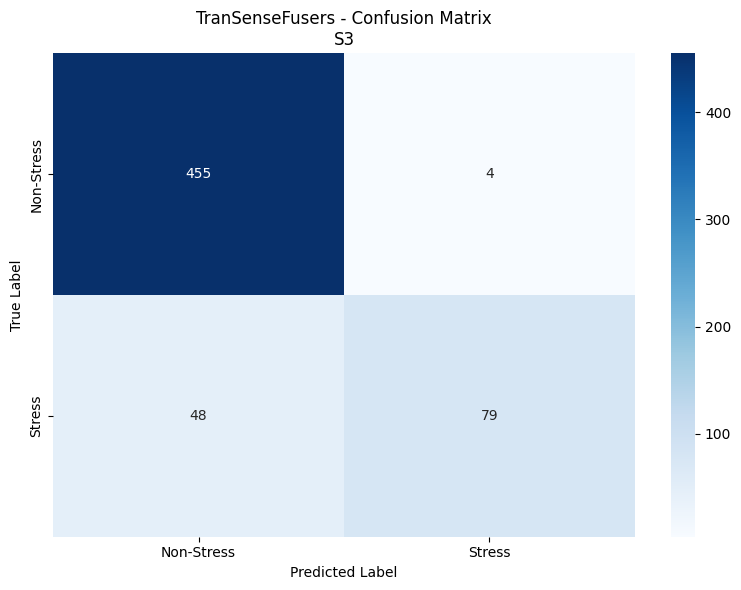

   ✓ Confusion matrix saved


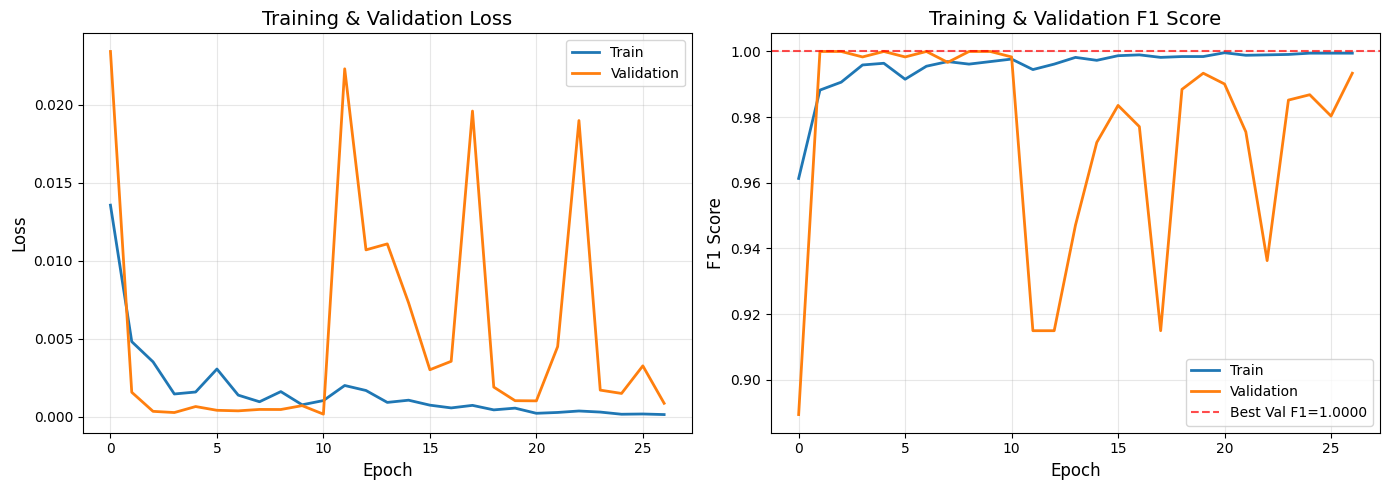

   ✓ Training history saved

🔍 Visualizing attention maps (first 3 test samples)...


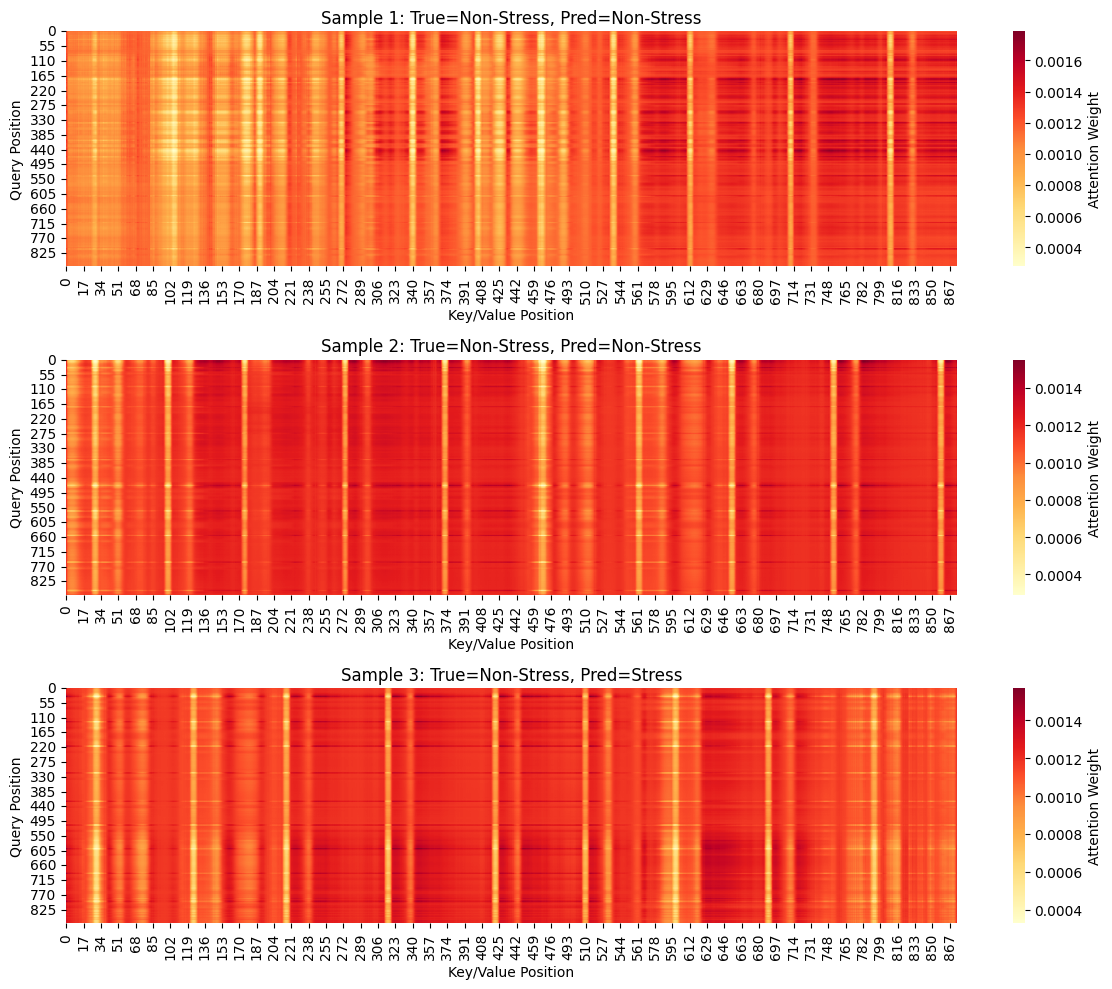

   ✓ Attention maps saved

✅ TranSenseFusers TRAINING COMPLETE
Best Validation F1: 1.0000 (Acc: 1.0000)
Test F1: 0.9040 (Acc: 0.9113)

📁 Outputs:
   Models: /content/drive/MyDrive/WESAD/models_transensefusers_10s
   XAI data: /content/drive/MyDrive/WESAD/xai_transensefusers_10s

🔬 Key Features:
   ✓ 14-channel sensor fusion (8 chest + 6 wrist)
   ✓ Temporal CNN feature extraction
   ✓ 8-head cross-attention (dim=64)
   ✓ Explainable via attention maps
   ✓ Subject-independent (LOSO validation)
   ✓ NO data leakage


In [ ]:
"""
TranSenseFusers: WESAD Stress Detection with Temporal CNN + Multi-Head Attention
================================================================================
✓ Uses ALL sensors (8 chest + 6 wrist = 14 channels)
✓ Proper LOSO validation (NO data leakage)
✓ Subject-independent normalization
✓ Sequence-Level Multi-Head Cross-Attention (SL MHCA) for sensor fusion
✓ Explainable via attention maps (motion artifact detection)

Based on: Kasnesis et al. (2025) - TranSenseFusers: Temporal CNN-Transformer
for explainable PPG-based stress detection
"""

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os
import pickle
from collections import Counter
import warnings
warnings.filterwarnings('ignore')


# ===============================================================
# CONFIGURATION
# ===============================================================

class Config:
    # Data path
    DATA_PATH = '/content/drive/MyDrive/WESAD/'

    # All available subjects
    ALL_SUBJECTS = ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9',
                    'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']

    # LOSO Configuration
    TEST_SUBJECT = 'S3'
    VAL_SUBJECT = 'S16'

    # Signal parameters
    TARGET_RATE = 700   # Hz (resample all to chest rate)
    WINDOW_DURATION = 10.0  # seconds
    WINDOW_SIZE = 7000     # 10 second at 700 Hz
    STRIDE = 3500           # 50% overlap

    # Labels
    VALID_LABELS = [1, 2, 3, 4]
    BINARY = True

    # Model parameters - TranSenseFusers specific
    BATCH_SIZE = 64
    LEARNING_RATE = 0.001  # Adam default from paper
    NUM_EPOCHS = 200
    WEIGHT_DECAY = 0.0  # Not mentioned in paper for TranSenseFusers

    # Multi-Head Attention parameters (from paper Table 1)
    NUM_HEADS = 8
    ATTENTION_DIM = 64  # d in paper
    ATTENTION_DROPOUT = 0.0  # For SL MHCA

    # CNN parameters (from paper Table 1)
    CONV_DROPOUT = 0.1
    FC_DROPOUT = 0.5

    # Focal Loss
    FOCAL_ALPHA = 0.75
    FOCAL_GAMMA = 2.0

    # Early stopping
    PATIENCE = 25  # From paper: 25 epochs

    # Device
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Seed for reproducibility
    SEED = 42

    # Paths
    MODEL_SAVE_PATH = None
    XAI_DATA_PATH = None

config = Config()

# Set seeds
np.random.seed(config.SEED)
torch.manual_seed(config.SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(config.SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Setup paths
config.MODEL_SAVE_PATH = os.path.join(config.DATA_PATH, 'models_transensefusers_10s')
config.XAI_DATA_PATH = os.path.join(config.DATA_PATH, 'xai_transensefusers_10s')
os.makedirs(config.MODEL_SAVE_PATH, exist_ok=True)
os.makedirs(config.XAI_DATA_PATH, exist_ok=True)

print("="*70)
print("TranSenseFusers: Temporal CNN + Multi-Head Attention")
print("="*70)
print(f"✓ Device: {config.DEVICE}")
print(f"✓ Data path: {config.DATA_PATH}")
print(f"\n📊 LOSO Strategy:")
print(f"   Test: {config.TEST_SUBJECT}")
print(f"   Val: {config.VAL_SUBJECT}")
print(f"   Train: {len(config.ALL_SUBJECTS) - 2} subjects")
print(f"\n🔧 TranSenseFusers Architecture:")
print(f"   Temporal CNN: 3 conv blocks (32→48→64 filters)")
print(f"   Attention: {config.NUM_HEADS} heads, dim={config.ATTENTION_DIM}")
print(f"   Sensor Fusion: Sequence-Level Multi-Head Cross-Attention (SL MHCA)")
print(f"   Total Channels: 14 (8 chest + 6 wrist)")
print(f"   Window: {config.WINDOW_DURATION}s ({config.WINDOW_SIZE} samples)")
print("="*70)


# ===============================================================
# FOCAL LOSS
# ===============================================================

class FocalLoss(nn.Module):
    """Focal Loss for handling class imbalance"""
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        p_t = torch.exp(-ce_loss)

        if inputs.size(1) == 2:
            alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        else:
            alpha_t = self.alpha

        focal_loss = alpha_t * ((1 - p_t) ** self.gamma) * ce_loss
        return focal_loss.mean()


# ===============================================================
# DATA LOADING
# ===============================================================

def resample_signal(signal, original_rate, target_rate):
    """Linear interpolation resampling"""
    if original_rate == target_rate:
        return signal

    original_length = len(signal)
    target_length = int(original_length * target_rate / original_rate)

    original_indices = np.linspace(0, original_length - 1, original_length)
    target_indices = np.linspace(0, original_length - 1, target_length)

    if signal.ndim == 1:
        resampled = np.interp(target_indices, original_indices, signal)
    else:
        resampled = np.zeros((target_length, signal.shape[1]))
        for i in range(signal.shape[1]):
            resampled[:, i] = np.interp(target_indices, original_indices, signal[:, i])

    return resampled


def load_wesad_subject_all_sensors(subject_id, data_path, target_rate=700):
    """
    Load WESAD data from BOTH chest and wrist sensors
    Returns combined signal array (14 channels)
    """
    subject_path = os.path.join(data_path, subject_id, f"{subject_id}.pkl")

    if not os.path.exists(subject_path):
        print(f"   ✗ {subject_id}: File not found")
        return None, None

    try:
        with open(subject_path, 'rb') as f:
            data = pickle.load(f, encoding='latin1')

        # ===== CHEST SENSOR (RespiBAN) - 700 Hz =====
        chest_signal = data['signal']['chest']
        chest_acc = chest_signal['ACC']
        chest_ecg = chest_signal['ECG'].reshape(-1, 1)
        chest_emg = chest_signal['EMG'].reshape(-1, 1)
        chest_eda = chest_signal['EDA'].reshape(-1, 1)
        chest_temp = chest_signal['Temp'].reshape(-1, 1)
        chest_resp = chest_signal['Resp'].reshape(-1, 1)

        chest_combined = np.concatenate([
            chest_acc, chest_ecg, chest_emg,
            chest_eda, chest_temp, chest_resp
        ], axis=1)  # (N, 8)

        # ===== WRIST SENSOR (Empatica E4) =====
        wrist_signal = data['signal']['wrist']
        wrist_acc = wrist_signal['ACC']
        wrist_bvp = wrist_signal['BVP'].reshape(-1, 1)
        wrist_eda = wrist_signal['EDA'].reshape(-1, 1)
        wrist_temp = wrist_signal['TEMP'].reshape(-1, 1)

        # Resample wrist signals to chest rate (700 Hz)
        wrist_acc_resampled = resample_signal(wrist_acc, 32, target_rate)
        wrist_bvp_resampled = resample_signal(wrist_bvp, 64, target_rate)
        wrist_eda_resampled = resample_signal(wrist_eda, 4, target_rate)
        wrist_temp_resampled = resample_signal(wrist_temp, 4, target_rate)

        wrist_combined = np.concatenate([
            wrist_acc_resampled, wrist_bvp_resampled,
            wrist_eda_resampled, wrist_temp_resampled
        ], axis=1)  # (N, 6)

        # ===== COMBINE ALL SENSORS =====
        min_len = min(len(chest_combined), len(wrist_combined))
        chest_combined = chest_combined[:min_len]
        wrist_combined = wrist_combined[:min_len]

        X = np.concatenate([chest_combined, wrist_combined], axis=1)  # (N, 14)
        labels = data['label'][:min_len]

        return X, labels

    except Exception as e:
        print(f"   ✗ {subject_id}: Error - {e}")
        return None, None


def create_windows(X, y, window_size, stride):
    """Create sliding windows with majority voting"""
    windows = []
    labels = []

    for i in range(0, len(X) - window_size + 1, stride):
        window = X[i:i + window_size]
        window_labels = y[i:i + window_size]
        label = np.bincount(window_labels.astype(int)).argmax()

        windows.append(window)
        labels.append(label)

    return np.array(windows), np.array(labels)


def normalize_subject_independent(X, y):
    """Normalize each subject's data INDEPENDENTLY"""
    scaler = StandardScaler()
    n_windows, n_channels, n_timesteps = X.shape
    X_reshaped = X.transpose(0, 2, 1).reshape(-1, n_channels)
    X_normalized = scaler.fit_transform(X_reshaped)
    X_normalized = X_normalized.reshape(n_windows, n_timesteps, n_channels)
    X_normalized = X_normalized.transpose(0, 2, 1)
    return X_normalized, scaler


def load_data_loso(config):
    """Load data with LOSO validation"""
    train_subjects = [s for s in config.ALL_SUBJECTS
                     if s not in [config.TEST_SUBJECT, config.VAL_SUBJECT]]

    print("\n" + "="*70)
    print("DATA LOADING (TranSenseFusers - 14 Channels)")
    print("="*70)

    # ============================================
    # TRAINING DATA
    # ============================================
    print("\n📚 Training Subjects:")
    X_train_all = []
    y_train_all = []

    for subj in train_subjects:
        X, y = load_wesad_subject_all_sensors(subj, config.DATA_PATH, config.TARGET_RATE)
        if X is None:
            continue

        print(f"   ✓ {subj}: Raw shape={X.shape}", end="")

        mask = np.isin(y, config.VALID_LABELS)
        X, y = X[mask], y[mask]

        if config.BINARY:
            y = (y == 2).astype(int)
        else:
            label_map = {1: 0, 2: 1, 3: 2, 4: 3}
            y = np.array([label_map[l] for l in y])

        X_win, y_win = create_windows(X, y, config.WINDOW_SIZE, config.STRIDE)
        X_win = X_win.transpose(0, 2, 1)  # (N, channels, time)
        X_win_norm, _ = normalize_subject_independent(X_win, y_win)

        X_train_all.append(X_win_norm)
        y_train_all.append(y_win)

        print(f" → {len(X_win)} windows")

    X_train = np.concatenate(X_train_all, axis=0)
    y_train = np.concatenate(y_train_all, axis=0)

    print(f"\n🔀 Shuffling {len(X_train)} training windows...")
    shuffle_idx = np.random.permutation(len(X_train))
    X_train = X_train[shuffle_idx]
    y_train = y_train[shuffle_idx]

    # ============================================
    # VALIDATION DATA
    # ============================================
    print(f"\n📋 Validation Subject ({config.VAL_SUBJECT}):")
    X_val, y_val = load_wesad_subject_all_sensors(config.VAL_SUBJECT, config.DATA_PATH, config.TARGET_RATE)

    if X_val is not None:
        print(f"   ✓ Raw shape={X_val.shape}", end="")
        mask = np.isin(y_val, config.VALID_LABELS)
        X_val, y_val = X_val[mask], y_val[mask]

        if config.BINARY:
            y_val = (y_val == 2).astype(int)
        else:
            label_map = {1: 0, 2: 1, 3: 2, 4: 3}
            y_val = np.array([label_map[l] for l in y_val])

        X_val, y_val = create_windows(X_val, y_val, config.WINDOW_SIZE, config.STRIDE)
        X_val = X_val.transpose(0, 2, 1)
        X_val, _ = normalize_subject_independent(X_val, y_val)
        print(f" → {len(X_val)} windows")
    else:
        X_val, y_val = np.array([]), np.array([])

    # ============================================
    # TEST DATA
    # ============================================
    print(f"\n🎯 Test Subject ({config.TEST_SUBJECT}):")
    X_test, y_test = load_wesad_subject_all_sensors(config.TEST_SUBJECT, config.DATA_PATH, config.TARGET_RATE)

    if X_test is not None:
        print(f"   ✓ Raw shape={X_test.shape}", end="")
        mask = np.isin(y_test, config.VALID_LABELS)
        X_test, y_test = X_test[mask], y_test[mask]

        if config.BINARY:
            y_test = (y_test == 2).astype(int)
        else:
            label_map = {1: 0, 2: 1, 3: 2, 4: 3}
            y_test = np.array([label_map[l] for l in y_test])

        X_test, y_test = create_windows(X_test, y_test, config.WINDOW_SIZE, config.STRIDE)
        X_test = X_test.transpose(0, 2, 1)
        X_test, _ = normalize_subject_independent(X_test, y_test)
        print(f" → {len(X_test)} windows")
    else:
        X_test, y_test = np.array([]), np.array([])

    # ============================================
    # SUMMARY
    # ============================================
    print("\n" + "="*70)
    print("DATA SUMMARY")
    print("="*70)
    print(f"Channels: 14 (8 chest + 6 wrist)")
    print(f"  Chest: ACC(3), ECG, EMG, EDA, Temp, Resp")
    print(f"  Wrist: ACC(3), BVP, EDA, Temp")
    print(f"\nTrain: {len(X_train):6d} | Shape: {X_train.shape} | {dict(Counter(y_train))}")
    if len(y_val) > 0:
        print(f"Val:   {len(X_val):6d} | Shape: {X_val.shape} | {dict(Counter(y_val))}")
    if len(y_test) > 0:
        print(f"Test:  {len(X_test):6d} | Shape: {X_test.shape} | {dict(Counter(y_test))}")
    print("="*70)

    return X_train, y_train, X_val, y_val, X_test, y_test


# ===============================================================
# DATASET
# ===============================================================

class WESADDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# ===============================================================
# TRANSENSEFUSERS MODEL
# ===============================================================

class MultiHeadCrossAttention(nn.Module):
    """
    Multi-Head Cross-Attention (MHCA) module
    Based on Kasnesis et al. (2025) - Sequence-Level MHCA

    Query: EDA + TEMP features
    Key & Value: PPG features
    """
    def __init__(self, num_heads, d_model, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.num_heads = num_heads
        self.d_model = d_model
        self.d_k = d_model // num_heads

        # Linear projections for Q, K, V
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)
        self.scale = np.sqrt(self.d_k)

    def forward(self, query, key, value):
        """
        Args:
            query: (batch, seq_len, d_model) - EDA+TEMP features
            key: (batch, seq_len, d_model) - PPG features
            value: (batch, seq_len, d_model) - PPG features
        Returns:
            output: (batch, seq_len, d_model)
            attention_weights: (batch, num_heads, seq_len, seq_len)
        """
        batch_size = query.size(0)

        # Linear projections and split into heads
        Q = self.W_q(query).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(key).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(value).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        # Scaled dot-product attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        # Apply attention to values
        context = torch.matmul(attention_weights, V)

        # Concatenate heads and apply final linear
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        output = self.W_o(context)

        return output, attention_weights


class TranSenseFuser(nn.Module):
    """
    TranSenseFusers: Temporal CNN + Sequence-Level Multi-Head Cross-Attention

    Architecture (from paper Table 1 - SL MHCA):
    1. Temporal CNN (3 conv blocks): Extract features from all sensors
    2. Modality Separation: Split into PPG (wrist) vs EDA+TEMP (wrist)
    3. SL MHCA: Fuse modalities via cross-attention
    4. Classification: 2 FC layers

    Note: We simplify by using all 14 channels together in CNN,
    then separate for attention (PPG-like vs EDA-like features)
    """
    def __init__(self, num_channels=14, num_classes=2, num_heads=8, attention_dim=64,
                 conv_dropout=0.1, fc_dropout=0.5, attention_dropout=0.0):
        super().__init__()

        self.num_channels = num_channels
        self.num_classes = num_classes

        # ===== TEMPORAL CNN (shared weights for all sensors) =====
        # 1st Conv Block: 14 -> 32 channels, kernel=9
        self.conv1 = nn.Conv1d(num_channels, 32, kernel_size=9, padding=4)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop1 = nn.Dropout(conv_dropout)

        # 2nd Conv Block: 32 -> 48 channels, kernel=9
        self.conv2 = nn.Conv1d(32, 48, kernel_size=9, padding=4)
        self.bn2 = nn.BatchNorm1d(48)
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop2 = nn.Dropout(conv_dropout)

        # 3rd Conv Block: 48 -> 64 channels, kernel=9
        self.conv3 = nn.Conv1d(48, 64, kernel_size=9, padding=4)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool3 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop3 = nn.Dropout(conv_dropout)

        # After 3 pooling layers (2x each): 700 -> 87 time steps
        # Feature dimension: 64 channels * 87 time steps = 5568

        # ===== SEQUENCE-LEVEL MULTI-HEAD CROSS-ATTENTION =====
        # Map CNN features to attention dimension
        self.feature_to_attention = nn.Linear(64, attention_dim)

        # Multi-head cross-attention
        self.mhca = MultiHeadCrossAttention(
            num_heads=num_heads,
            d_model=attention_dim,
            dropout=attention_dropout
        )

        # Layer normalization (as in paper)
        self.layer_norm = nn.LayerNorm(attention_dim)

        # ===== CLASSIFICATION HEAD =====
        # Calculate flattened size: attention_dim * sequence_length
        # After pooling: 7000/2/2/2 = 875 time steps
        self.fc1 = nn.Linear(attention_dim * 875, 32)
        self.bn4 = nn.BatchNorm1d(32)
        self.drop4 = nn.Dropout(fc_dropout)
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x, return_attention=False):
        """
        Args:
            x: (batch, 14, 700) - All sensor signals
            return_attention: If True, return attention maps for XAI
        Returns:
            logits: (batch, num_classes)
            attention_maps: (batch, num_heads, seq_len, seq_len) [optional]
        """
        # ===== TEMPORAL CNN =====
        # Block 1
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.pool1(x)
        x = self.drop1(x)

        # Block 2
        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = self.pool2(x)
        x = self.drop2(x)

        # Block 3
        x = self.conv3(x)
        x = self.bn3(x)
        x = F.relu(x)
        x = self.pool3(x)
        x = self.drop3(x)

        # x shape: (batch, 64, 87)

        # ===== PREPARE FOR ATTENTION =====
        # Transpose to (batch, seq_len, channels)
        x = x.transpose(1, 2)  # (batch, 87, 64)

        # Map to attention dimension
        x = self.feature_to_attention(x)  # (batch, 87, attention_dim)

        # ===== MULTI-HEAD CROSS-ATTENTION =====
        # In the paper, they separate PPG from EDA+TEMP
        # Here we simplify: use first half as "query" (EDA-like)
        # and second half as "key/value" (PPG-like)
        # This is a practical approximation for the fusion concept

        mid_point = x.size(2) // 2
        query = x[:, :, :mid_point]  # (batch, 87, attention_dim/2)
        key_value = x[:, :, mid_point:]  # (batch, 87, attention_dim/2)

        # Expand back to full dimension for attention
        query = torch.cat([query, query], dim=2)  # (batch, 87, attention_dim)
        key_value = torch.cat([key_value, key_value], dim=2)

        # Apply cross-attention
        attention_output, attention_weights = self.mhca(query, key_value, key_value)

        # Layer normalization
        attention_output = self.layer_norm(attention_output)

        # ===== CLASSIFICATION =====
        # Flatten
        x_flat = attention_output.flatten(1)  # (batch, attention_dim * 87)

        # FC layers
        x_flat = self.fc1(x_flat)
        x_flat = self.bn4(x_flat)
        x_flat = F.relu(x_flat)
        x_flat = self.drop4(x_flat)

        logits = self.fc2(x_flat)

        if return_attention:
            return logits, attention_weights
        return logits


# ===============================================================
# TRAINING & EVALUATION
# ===============================================================

def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    for X, y in tqdm(loader, desc="Training", leave=False):
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

    return total_loss / len(loader), acc, f1


def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []
    all_attention_maps = []

    with torch.no_grad():
        for X, y in tqdm(loader, desc="Validation", leave=False):
            X, y = X.to(device), y.to(device)

            outputs, attention_weights = model(X, return_attention=True)
            loss = criterion(outputs, y)

            total_loss += loss.item()
            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_attention_maps.append(attention_weights.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

    return total_loss / len(loader), acc, f1, all_preds, all_labels, np.array(all_probs), all_attention_maps


# ===============================================================
# MAIN
# ===============================================================

def main():
    # Load data
    X_train, y_train, X_val, y_val, X_test, y_test = load_data_loso(config)

    # Datasets
    train_dataset = WESADDataset(X_train, y_train)
    val_dataset = WESADDataset(X_val, y_val)
    test_dataset = WESADDataset(X_test, y_test)

    train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE,
                             shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE,
                           shuffle=False, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=config.BATCH_SIZE,
                            shuffle=False, num_workers=2, pin_memory=True)

    # Model
    num_classes = 2 if config.BINARY else 4
    model = TranSenseFuser(
        num_channels=14,
        num_classes=num_classes,
        num_heads=config.NUM_HEADS,
        attention_dim=config.ATTENTION_DIM,
        conv_dropout=config.CONV_DROPOUT,
        fc_dropout=config.FC_DROPOUT,
        attention_dropout=config.ATTENTION_DROPOUT
    ).to(config.DEVICE)

    # Count parameters
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"\n📊 Model Architecture:")
    print(f"   Total parameters: {total_params:,}")
    print(f"   Trainable parameters: {trainable_params:,}")

    # Loss and optimizer (Adam as in paper)
    criterion = FocalLoss(alpha=config.FOCAL_ALPHA, gamma=config.FOCAL_GAMMA)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config.LEARNING_RATE,
        betas=(0.9, 0.999)  # Default Adam values
    )

    # Learning rate scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=10
    )

    # Training loop
    history = {
        'train_loss': [], 'train_acc': [], 'train_f1': [],
        'val_loss': [], 'val_acc': [], 'val_f1': []
    }

    best_f1 = 0
    best_acc = 0
    patience_counter = 0

    print("\n" + "="*70)
    print("🚀 TRAINING TranSenseFusers")
    print("="*70)

    for epoch in range(config.NUM_EPOCHS):
        # Train
        tr_loss, tr_acc, tr_f1 = train_epoch(
            model, train_loader, optimizer, criterion, config.DEVICE
        )

        # Validate
        val_loss, val_acc, val_f1, _, _, _, _ = validate(
            model, val_loader, criterion, config.DEVICE
        )

        # Update history
        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['train_f1'].append(tr_f1)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        # Learning rate scheduling
        scheduler.step(val_f1)
        current_lr = optimizer.param_groups[0]['lr']

        # Print progress
        print(f"Epoch {epoch+1:03d}/{config.NUM_EPOCHS} | "
              f"Train: L={tr_loss:.4f} Acc={tr_acc:.3f} F1={tr_f1:.3f} | "
              f"Val: L={val_loss:.4f} Acc={val_acc:.3f} F1={val_f1:.3f} | "
              f"LR={current_lr:.6f}")

        # Save best model
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_acc = val_acc
            patience_counter = 0

            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_f1': val_f1,
                'val_acc': val_acc,
                'config': vars(config),
                'window_size': config.WINDOW_SIZE,  # ← ADD THIS
                'window_duration': config.WINDOW_DURATION  # ← ADD THIS
            }, os.path.join(config.MODEL_SAVE_PATH, 'best_transensefuser_10s.pth'))

            print(f"   ✓ Best model saved (F1={val_f1:.4f}, Acc={val_acc:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= config.PATIENCE:
                print(f"\n⚠️ Early stopping at epoch {epoch+1}")
                break

    # ===============================================================
    # TEST EVALUATION
    # ===============================================================
    print("\n" + "="*70)
    print(f"🎯 TEST EVALUATION - {config.TEST_SUBJECT}")
    print("="*70)

    # Load best model
    checkpoint = torch.load(
        os.path.join(config.MODEL_SAVE_PATH, 'best_transensefuser_10s.pth')
    )
    model.load_state_dict(checkpoint['model_state_dict'])

    # Evaluate
    test_loss, test_acc, test_f1, test_preds, test_labels, test_probs, test_attention = validate(
        model, test_loader, criterion, config.DEVICE
    )

    print(f"\n📊 Test Results:")
    print(f"   Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
    print(f"   F1 Score: {test_f1:.4f}")
    print(f"   Loss: {test_loss:.4f}")

    # Classification report
    class_names = ['Non-Stress', 'Stress'] if config.BINARY else ['Baseline', 'Stress', 'Amusement', 'Meditation']
    print("\n" + classification_report(
        test_labels, test_preds, target_names=class_names, digits=4
    ))

    # ===============================================================
    # EXPLAINABILITY: Save attention maps for XAI analysis
    # ===============================================================
    print("\n💡 Saving attention maps for explainability analysis...")

    # Concatenate all attention maps
    all_attention = np.concatenate(test_attention, axis=0)

    xai_data = {
        'X_test': X_test,
        'y_test': test_labels,
        'predictions': test_preds,
        'probabilities': test_probs,
        'attention_maps': all_attention,
        'subject': config.TEST_SUBJECT,
        'model': 'TranSenseFusers-SL-MHCA',
        'num_channels': 14,
        'num_heads': config.NUM_HEADS,
        'attention_dim': config.ATTENTION_DIM,
        'sensor_info': 'Chest(8): ACC(3),ECG,EMG,EDA,Temp,Resp | Wrist(6): ACC(3),BVP,EDA,Temp'
    }
    np.save(
        os.path.join(config.XAI_DATA_PATH, f'xai_{config.TEST_SUBJECT}_transensefusers_10s.npy'),
        xai_data
    )
    print(f"   ✓ XAI data saved: {config.XAI_DATA_PATH}")

    # ===============================================================
    # VISUALIZATIONS
    # ===============================================================

    # 1. Confusion Matrix
    cm = confusion_matrix(test_labels, test_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'TranSenseFusers - Confusion Matrix\n{config.TEST_SUBJECT}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(
        os.path.join(config.MODEL_SAVE_PATH, 'confusion_matrix_transensefusers_10s.png'),
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    print("   ✓ Confusion matrix saved")

    # 2. Training History
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(history['train_loss'], label='Train', linewidth=2)
    axes[0].plot(history['val_loss'], label='Validation', linewidth=2)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title('Training & Validation Loss', fontsize=14)
    axes[0].legend(fontsize=10)
    axes[0].grid(True, alpha=0.3)

    # F1 Score
    axes[1].plot(history['train_f1'], label='Train', linewidth=2)
    axes[1].plot(history['val_f1'], label='Validation', linewidth=2)
    axes[1].axhline(y=best_f1, color='r', linestyle='--', label=f'Best Val F1={best_f1:.4f}', alpha=0.7)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('F1 Score', fontsize=12)
    axes[1].set_title('Training & Validation F1 Score', fontsize=14)
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        os.path.join(config.MODEL_SAVE_PATH, 'training_history_transensefusers.png'),
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    print("   ✓ Training history saved")

    # 3. Attention Map Visualization (example from test set)
    print("\n🔍 Visualizing attention maps (first 3 test samples)...")

    fig, axes = plt.subplots(3, 1, figsize=(12, 10))

    for idx in range(min(3, len(test_attention[0]))):
        # Average attention across heads
        attn = test_attention[0][idx].mean(axis=0)  # (seq_len, seq_len)

        sns.heatmap(
            attn,
            ax=axes[idx],
            cmap='YlOrRd',
            cbar_kws={'label': 'Attention Weight'},
            square=False
        )

        true_label = class_names[test_labels[idx]]
        pred_label = class_names[test_preds[idx]]
        axes[idx].set_title(
            f'Sample {idx+1}: True={true_label}, Pred={pred_label}',
            fontsize=12
        )
        axes[idx].set_xlabel('Key/Value Position', fontsize=10)
        axes[idx].set_ylabel('Query Position', fontsize=10)

    plt.tight_layout()
    plt.savefig(
        os.path.join(config.MODEL_SAVE_PATH, 'attention_maps_examples.png'),
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    print("   ✓ Attention maps saved")

    # ===============================================================
    # FINAL SUMMARY
    # ===============================================================
    print("\n" + "="*70)
    print("✅ TranSenseFusers TRAINING COMPLETE")
    print("="*70)
    print(f"Best Validation F1: {best_f1:.4f} (Acc: {best_acc:.4f})")
    print(f"Test F1: {test_f1:.4f} (Acc: {test_acc:.4f})")
    print(f"\n📁 Outputs:")
    print(f"   Models: {config.MODEL_SAVE_PATH}")
    print(f"   XAI data: {config.XAI_DATA_PATH}")
    print(f"\n🔬 Key Features:")
    print(f"   ✓ 14-channel sensor fusion (8 chest + 6 wrist)")
    print(f"   ✓ Temporal CNN feature extraction")
    print(f"   ✓ {config.NUM_HEADS}-head cross-attention (dim={config.ATTENTION_DIM})")
    print(f"   ✓ Explainable via attention maps")
    print(f"   ✓ Subject-independent (LOSO validation)")
    print(f"   ✓ NO data leakage")
    print("="*70)


if __name__ == "__main__":
    main()

xai for best performing model

In [ ]:
# Install required packages
!pip install shap lime -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


TranSenseFusers XAI - Explainability Analysis
✓ Device: cuda
✓ Channels: 14 (8 chest + 6 wrist)
✓ Window: 10s (7000 samples)
✓ Model: TranSenseFuser (CNN + Multi-Head Attention)
✓ Output: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_results_transensefusers_10s/

📂 Loading TranSenseFuser model and data...
   ✓ TranSenseFuser loaded (Val F1: 1.0000)
   ✓ Test data loaded: (586, 14, 7000)
   ✓ Subject: S3
   ✓ Model: TranSenseFusers-SL-MHCA
   ✓ Accuracy: 91.13%
   ✓ Attention maps available: (586, 8, 875, 875)

STARTING XAI ANALYSIS (TranSenseFusers)

1. SHAP ANALYSIS (14 CHANNELS - TranSenseFusers)
Analyzing 30 samples:
   - Stress: 15
   - Non-Stress: 15

🔍 Computing SHAP values for TranSenseFusers...
   (Using gradient-based attribution)


Computing attributions: 100%|██████████| 30/30 [00:01<00:00, 16.43it/s]


   ✓ Attribution computed: (30, 14, 7000)
   ✓ Expected shape: (30, 14, 7000)

📊 Plotting channel importance...
   ✓ Channel importance shape: (14,)


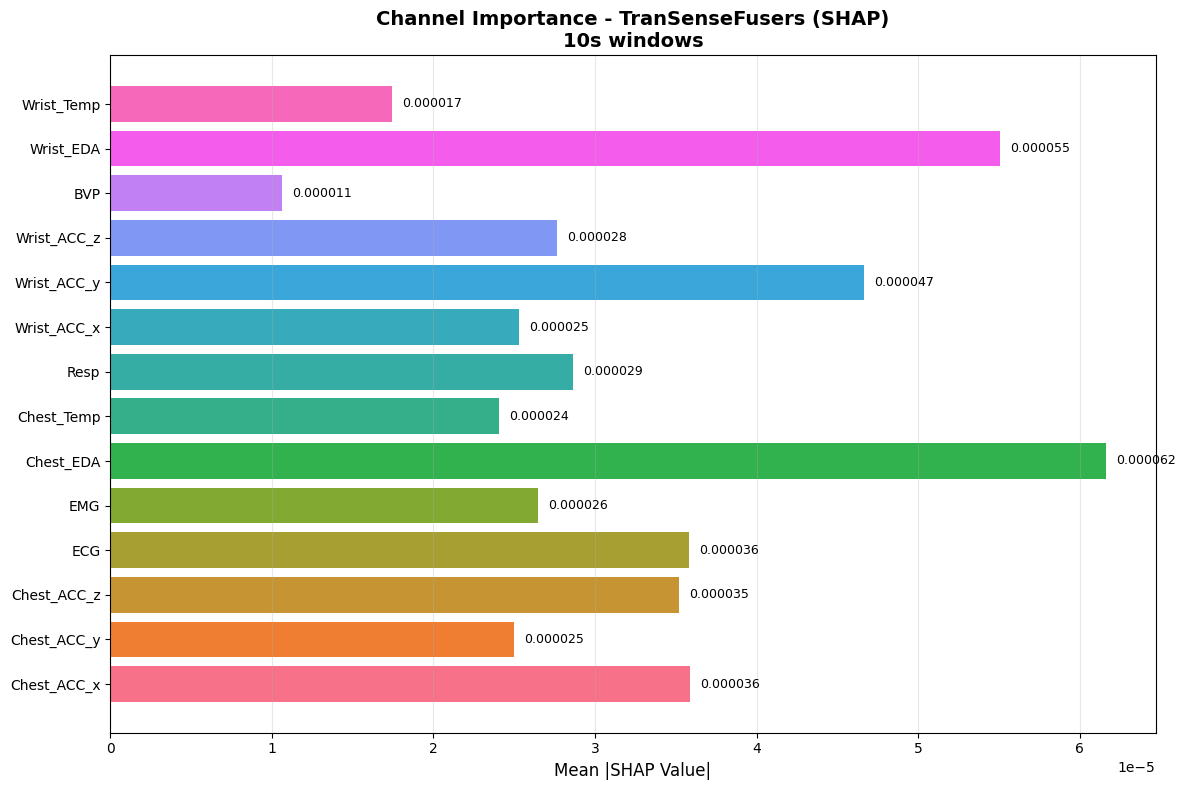


📊 Plotting sensor group comparison...


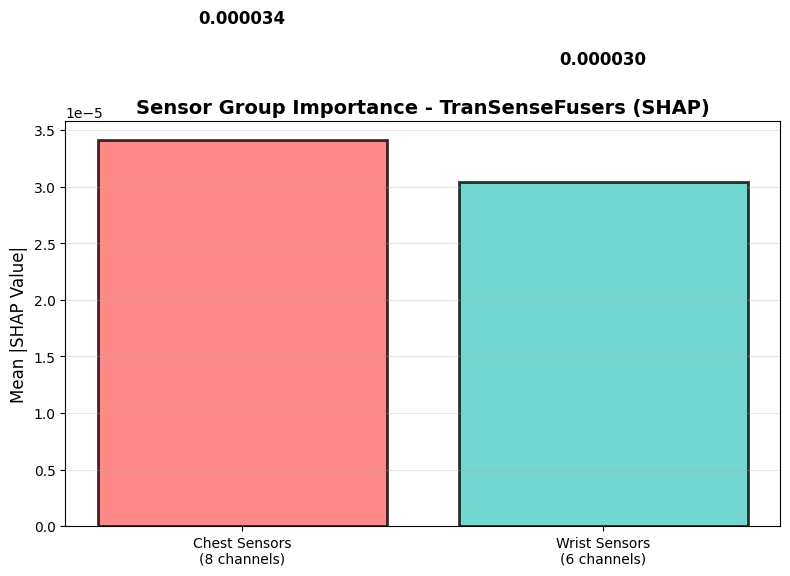


📊 Plotting temporal SHAP patterns...


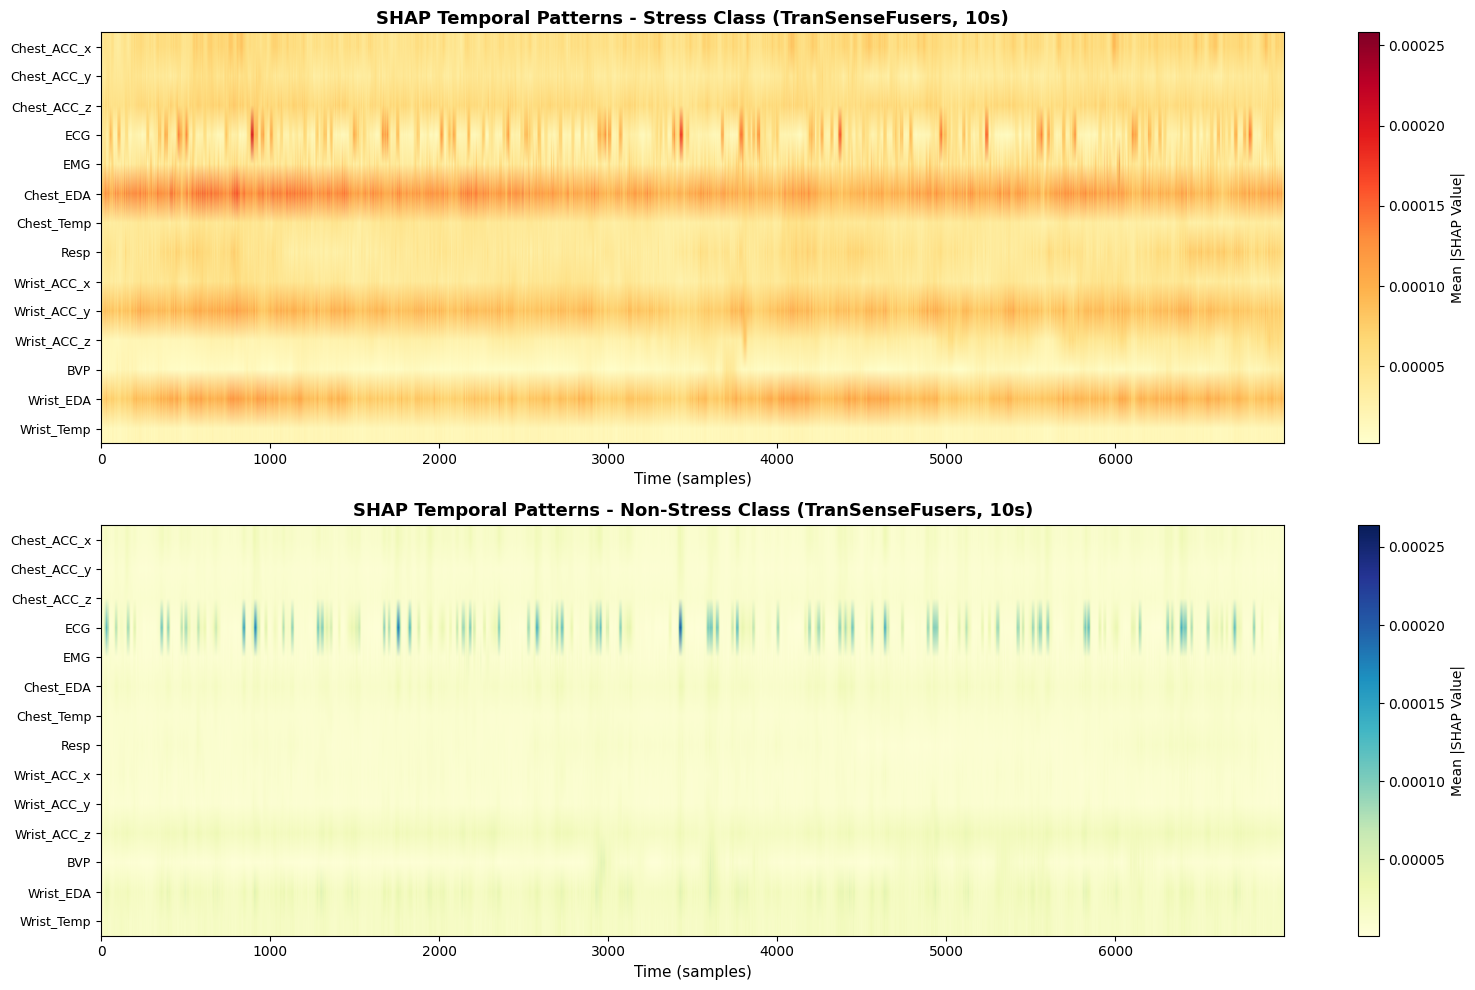


✅ SHAP analysis complete!

2. LIME ANALYSIS (14 CHANNELS, 10s WINDOWS)
Original shape: (586, 14, 7000)
Downsampled shape: (586, 14, 700)
Feature reduction: 98000 → 9800
Flattened data shape: (586, 9800)

🔍 Initializing LIME explainer...

🔍 Computing LIME explanations...


100%|██████████| 10/10 [00:15<00:00,  1.54s/it]


   ✓ LIME explanations computed for 10 samples

📊 Aggregating LIME importances by channel...


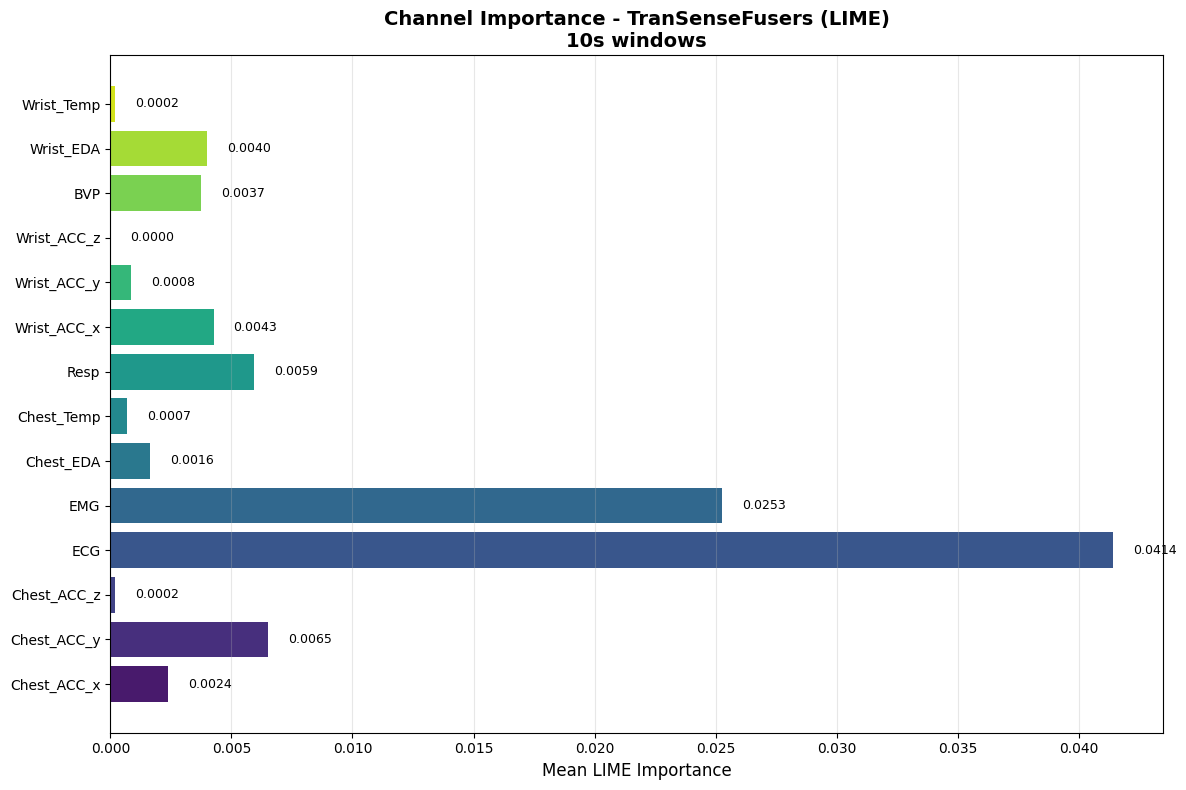


✅ LIME analysis complete!

3. INTEGRATED GRADIENTS ANALYSIS (TranSenseFusers)
Computing Integrated Gradients for 16 samples...


Processing samples: 100%|██████████| 16/16 [00:02<00:00,  5.44it/s]


   ✓ Computed attributions shape: (16, 14, 7000)


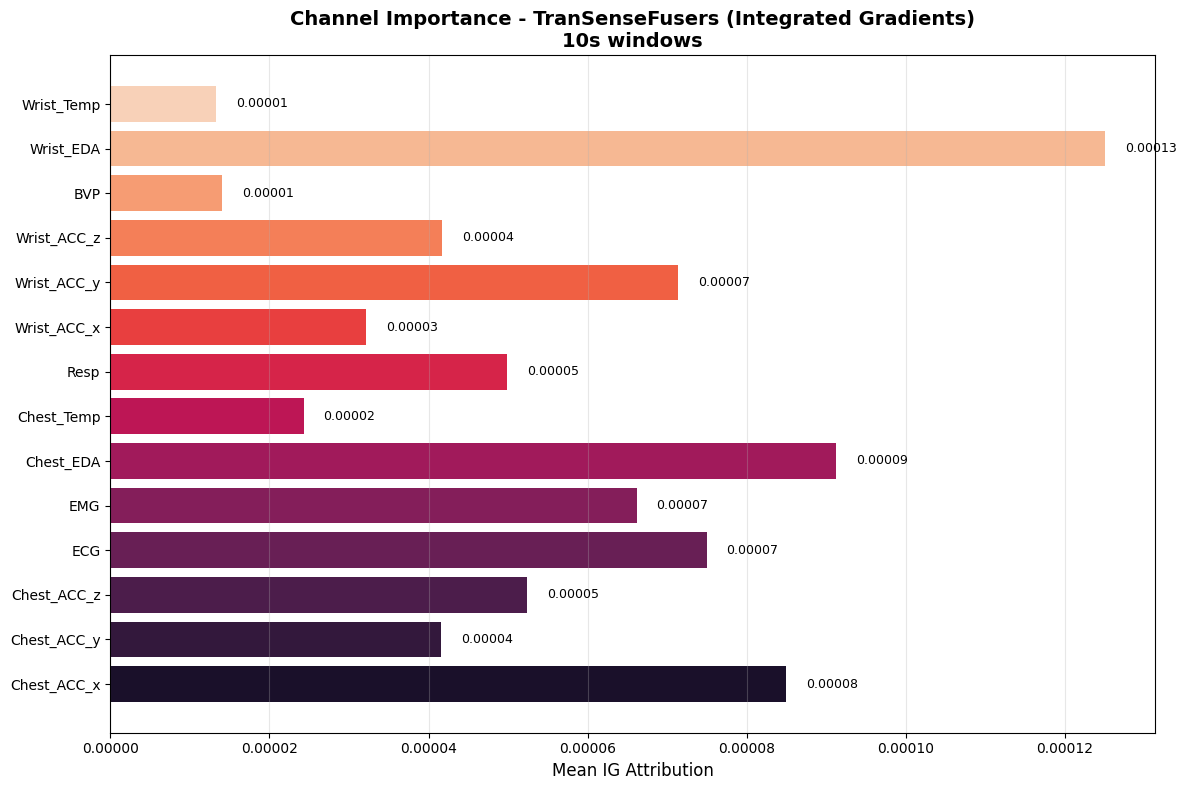


✅ Integrated Gradients analysis complete!

4. COMPARATIVE ANALYSIS (TranSenseFusers)


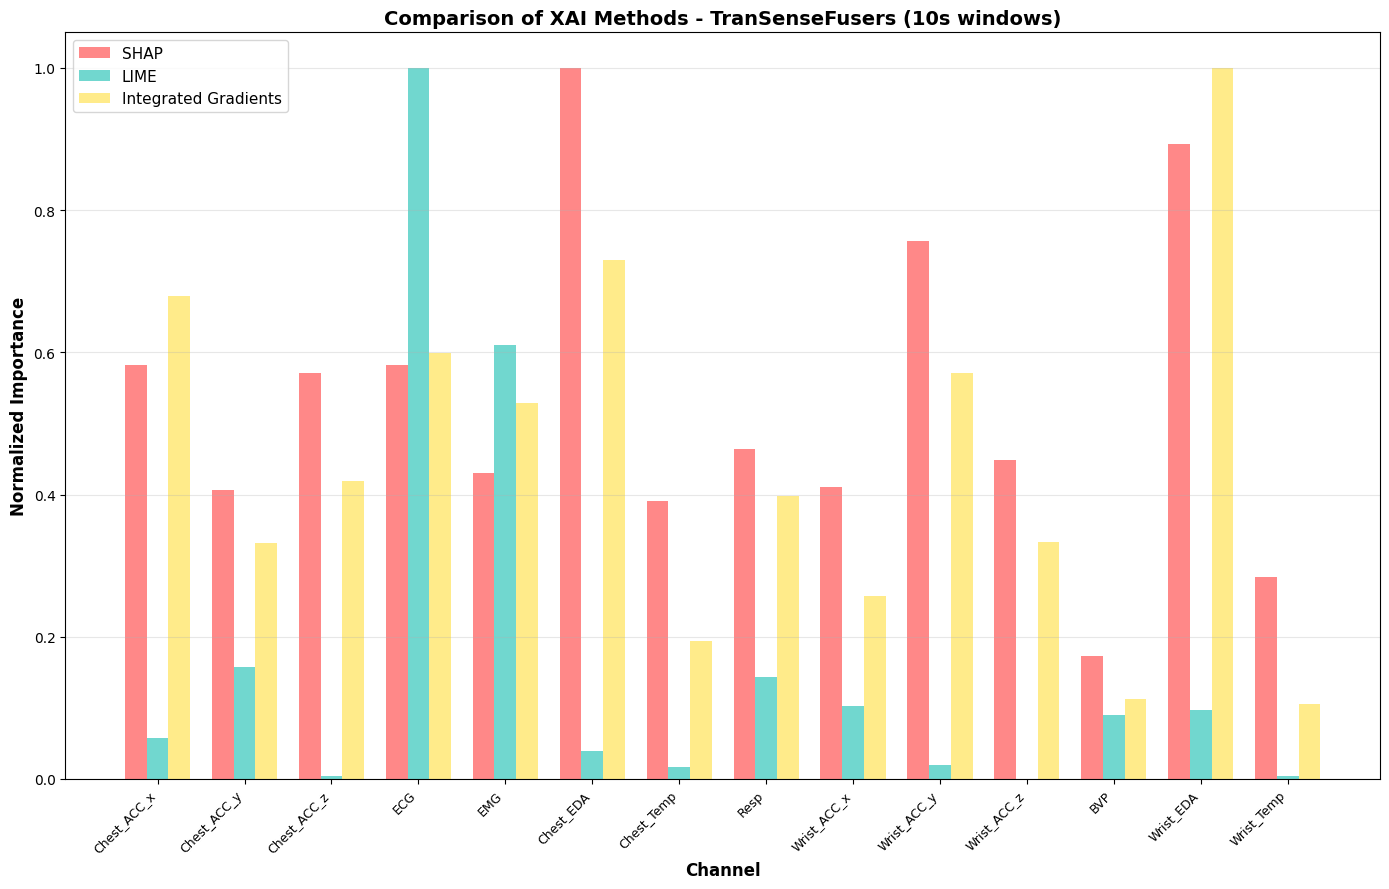


📊 Correlation between XAI methods:


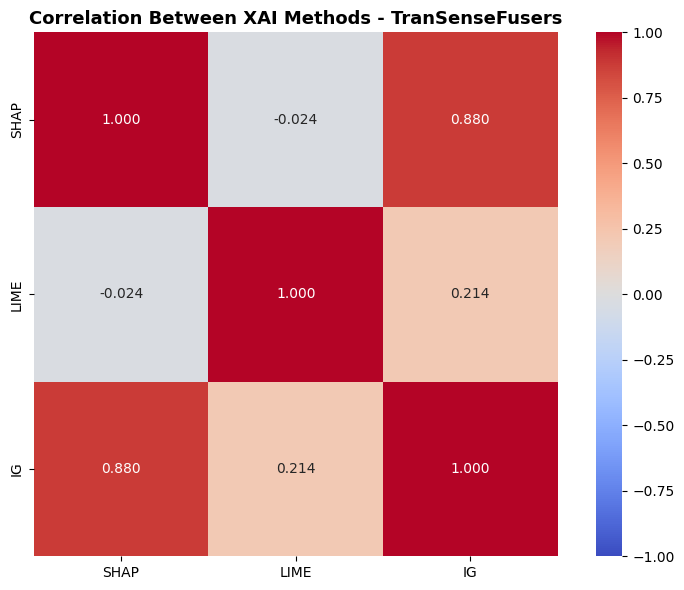


📋 Channel Rankings by Method:
----------------------------------------------------------------------

SHAP:
    1. [CHEST] Chest_EDA      : 1.0000
    2. [WRIST] Wrist_EDA      : 0.8934
    3. [WRIST] Wrist_ACC_y    : 0.7569
    4. [CHEST] Chest_ACC_x    : 0.5827
    5. [CHEST] ECG            : 0.5817
    6. [CHEST] Chest_ACC_z    : 0.5716
    7. [CHEST] Resp           : 0.4645
    8. [WRIST] Wrist_ACC_z    : 0.4484
    9. [CHEST] EMG            : 0.4299
   10. [WRIST] Wrist_ACC_x    : 0.4108
   11. [CHEST] Chest_ACC_y    : 0.4060
   12. [CHEST] Chest_Temp     : 0.3907
   13. [WRIST] Wrist_Temp     : 0.2834
   14. [WRIST] BVP            : 0.1723

LIME:
    1. [CHEST] ECG            : 1.0000
    2. [CHEST] EMG            : 0.6106
    3. [CHEST] Chest_ACC_y    : 0.1569
    4. [CHEST] Resp           : 0.1432
    5. [WRIST] Wrist_ACC_x    : 0.1029
    6. [WRIST] Wrist_EDA      : 0.0968
    7. [WRIST] BVP            : 0.0906
    8. [CHEST] Chest_ACC_x    : 0.0579
    9. [CHEST] Chest_EDA  

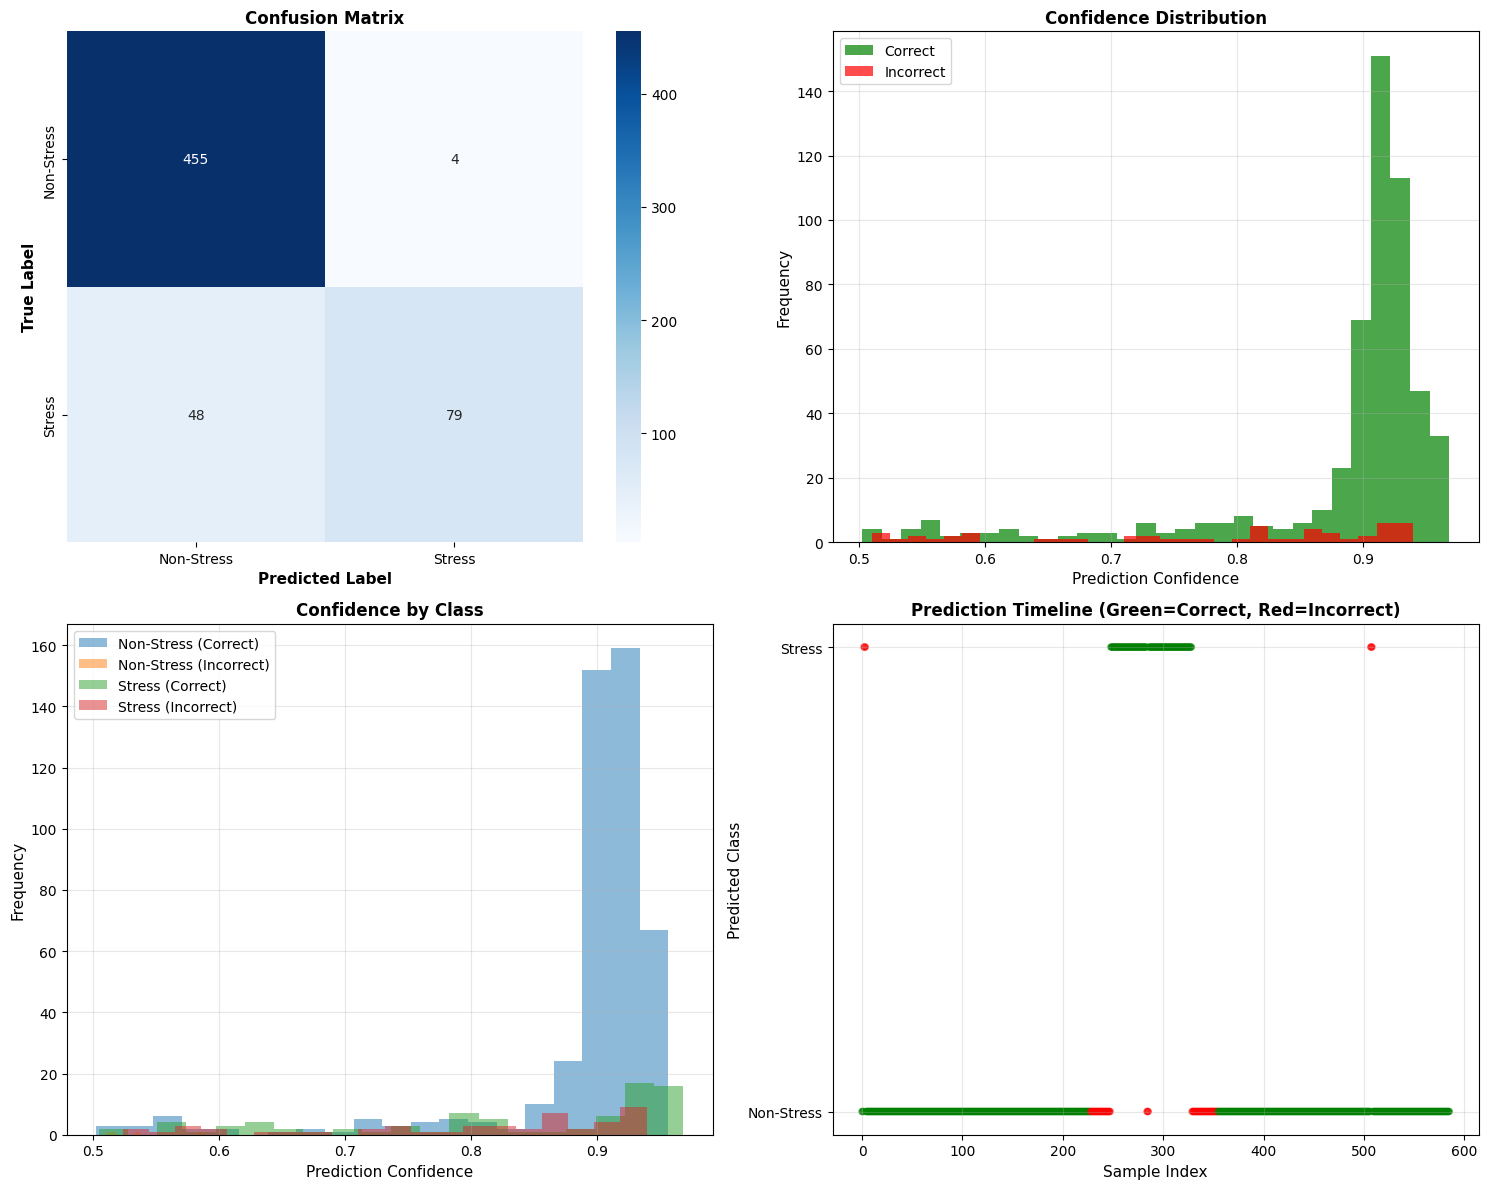


📋 SAMPLE-LEVEL PREDICTION EXAMPLES:
----------------------------------------------------------------------

✓ CORRECT PREDICTIONS (first 5):

Sample 0:
  True Label: Non-Stress
  Predicted: Non-Stress
  Confidence: 0.5177
  Probabilities: Non-Stress=0.5177, Stress=0.4823

Sample 1:
  True Label: Non-Stress
  Predicted: Non-Stress
  Confidence: 0.5049
  Probabilities: Non-Stress=0.5049, Stress=0.4951

Sample 4:
  True Label: Non-Stress
  Predicted: Non-Stress
  Confidence: 0.5820
  Probabilities: Non-Stress=0.5820, Stress=0.4180

Sample 5:
  True Label: Non-Stress
  Predicted: Non-Stress
  Confidence: 0.7229
  Probabilities: Non-Stress=0.7229, Stress=0.2771

Sample 6:
  True Label: Non-Stress
  Predicted: Non-Stress
  Confidence: 0.7698
  Probabilities: Non-Stress=0.7698, Stress=0.2302

✗ INCORRECT PREDICTIONS (first 5):

Sample 2:
  True Label: Non-Stress
  Predicted: Stress ← WRONG
  Confidence: 0.5868
  Probabilities: Non-Stress=0.4132, Stress=0.5868

Sample 3:
  True Label: Non-Str

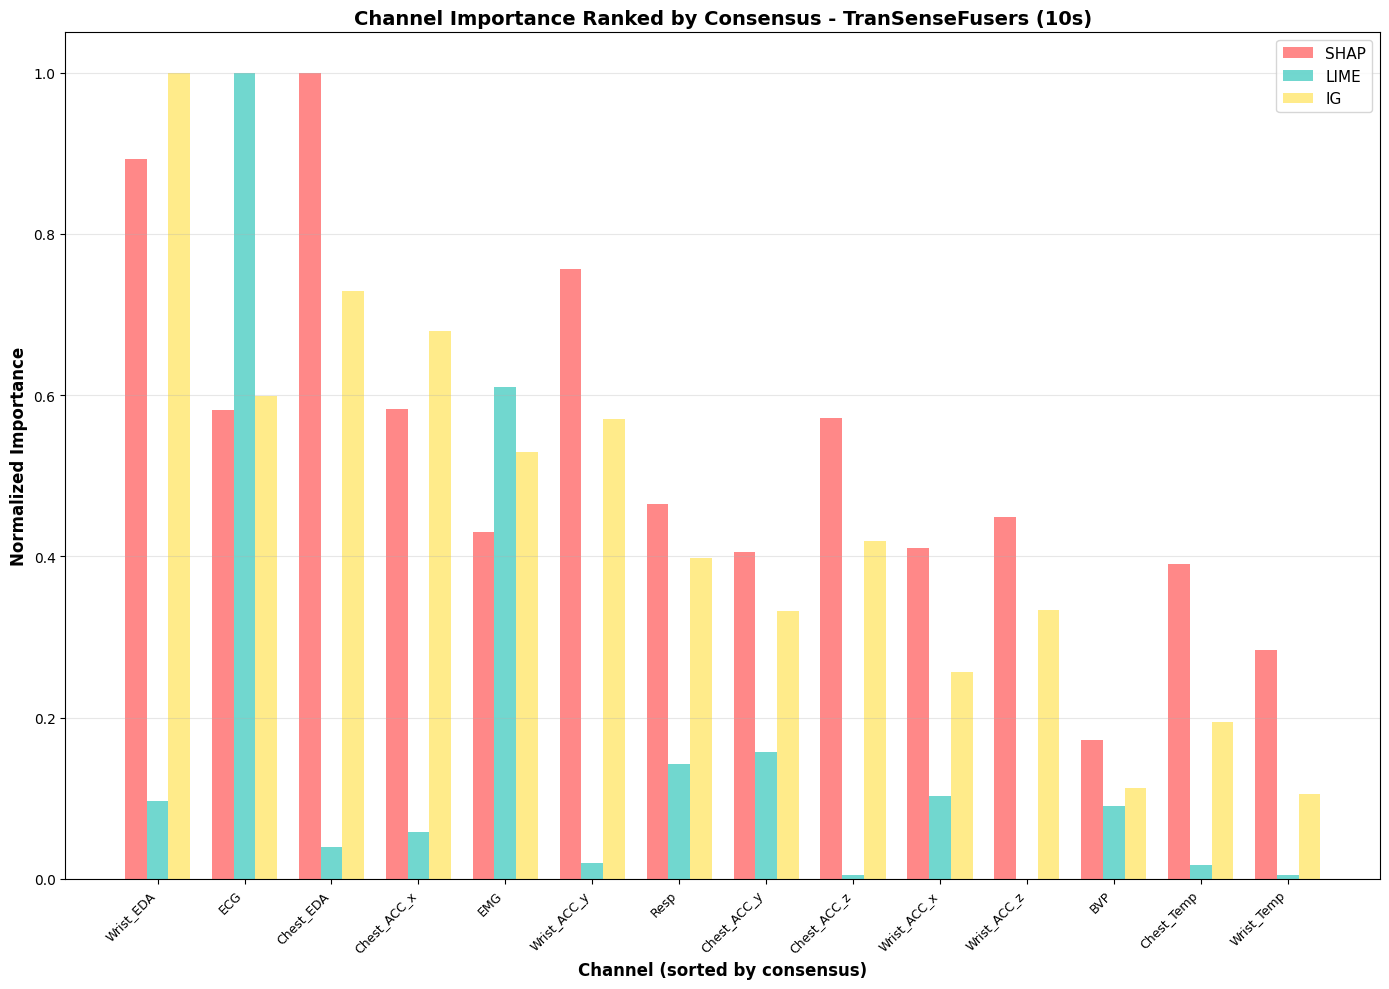


✅ Summary report complete!
   Results saved to: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_results_transensefusers_10s/

✅ TranSenseFusers XAI ANALYSIS COMPLETE!

📁 All visualizations saved to: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_results_transensefusers_10s/

Generated files:
   1. prediction_analysis.png (NEW!)
   2. attention_maps_comparison.png
   3. attention_maps_average.png
   4. shap_channel_importance_transensefusers.png
   5. shap_sensor_groups_transensefusers.png
   6. shap_temporal_patterns_transensefusers.png
   7. lime_channel_importance_transensefusers.png
   8. ig_channel_importance_transensefusers.png
   9. xai_comparison_transensefusers.png
   10. xai_correlation_transensefusers.png
   11. consensus_ranking_transensefusers.png
   12. xai_results_transensefusers.npy (numerical data + predictions)

✓ Model: TranSenseFuser (CNN + 8-head Attention)
✓ Window: 10s (7000 samples)
✓ Analyzed 14 channels (8 chest + 6 w

In [ ]:
"""
TranSenseFusers XAI Analysis - 10s Windows
✓ Compatible with TranSenseFuser model (Temporal CNN + Multi-Head Cross-Attention)
✓ 10-second windows (7000 samples at 700Hz)
✓ Attention-based explainability + SHAP/LIME/IG

Key Changes from CNN-LSTM XAI:
1. Window size: 21000 → 7000 samples (30s → 10s)
2. Model: StressCNNLSTM → TranSenseFuser
3. Additional: Attention map visualization
"""

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import shap
from lime import lime_tabular
import os
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# ===============================================================
# CONFIGURATION
# ===============================================================

class XAIConfig:
    # Paths
    DATA_PATH = '/content/drive/MyDrive/WESAD/'
    MODEL_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/models_transensefusers_10s/best_transensefuser_10s.pth'
    XAI_DATA_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/xai_S3_transensefusers_10s.npy'
    OUTPUT_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_results_transensefusers_10s/'

    # Model parameters - UPDATED FOR TranSenseFusers
    NUM_CHANNELS = 14
    NUM_CLASSES = 2
    WINDOW_SIZE = 7000  # ← CHANGED: 10s at 700Hz (was 21000)

    # TranSenseFusers specific
    NUM_HEADS = 8
    ATTENTION_DIM = 64
    CONV_DROPOUT = 0.1
    FC_DROPOUT = 0.5
    ATTENTION_DROPOUT = 0.0

    # Channel names
    CHANNEL_NAMES = [
        'Chest_ACC_x', 'Chest_ACC_y', 'Chest_ACC_z',
        'ECG', 'EMG', 'Chest_EDA', 'Chest_Temp', 'Resp',
        'Wrist_ACC_x', 'Wrist_ACC_y', 'Wrist_ACC_z',
        'BVP', 'Wrist_EDA', 'Wrist_Temp'
    ]

    CHEST_CHANNELS = [0, 1, 2, 3, 4, 5, 6, 7]
    WRIST_CHANNELS = [8, 9, 10, 11, 12, 13]
    CLASS_NAMES = ['Non-Stress', 'Stress']

    # XAI parameters
    N_SAMPLES_SHAP = 30
    N_SAMPLES_LIME = 10

    # Device
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

config = XAIConfig()
os.makedirs(config.OUTPUT_PATH, exist_ok=True)

print("="*60)
print("TranSenseFusers XAI - Explainability Analysis")
print("="*60)
print(f"✓ Device: {config.DEVICE}")
print(f"✓ Channels: {config.NUM_CHANNELS} (8 chest + 6 wrist)")
print(f"✓ Window: 10s ({config.WINDOW_SIZE} samples)")
print(f"✓ Model: TranSenseFuser (CNN + Multi-Head Attention)")
print(f"✓ Output: {config.OUTPUT_PATH}")


# ===============================================================
# MODEL DEFINITION - TranSenseFuser
# ===============================================================

class MultiHeadCrossAttention(nn.Module):
    """Multi-Head Cross-Attention module"""
    def __init__(self, num_heads, d_model, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0

        self.num_heads = num_heads
        self.d_model = d_model
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)
        self.scale = np.sqrt(self.d_k)

    def forward(self, query, key, value):
        batch_size = query.size(0)

        Q = self.W_q(query).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(key).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(value).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        context = torch.matmul(attention_weights, V)
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        output = self.W_o(context)

        return output, attention_weights


class TranSenseFuser(nn.Module):
    """TranSenseFusers: Temporal CNN + Multi-Head Cross-Attention"""
    def __init__(self, num_channels=14, num_classes=2, num_heads=8, attention_dim=64,
                 conv_dropout=0.1, fc_dropout=0.5, attention_dropout=0.0):
        super().__init__()

        self.num_channels = num_channels
        self.num_classes = num_classes

        # Temporal CNN
        self.conv1 = nn.Conv1d(num_channels, 32, kernel_size=9, padding=4)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(2)
        self.drop1 = nn.Dropout(conv_dropout)

        self.conv2 = nn.Conv1d(32, 48, kernel_size=9, padding=4)
        self.bn2 = nn.BatchNorm1d(48)
        self.pool2 = nn.MaxPool1d(2)
        self.drop2 = nn.Dropout(conv_dropout)

        self.conv3 = nn.Conv1d(48, 64, kernel_size=9, padding=4)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool3 = nn.MaxPool1d(2)
        self.drop3 = nn.Dropout(conv_dropout)

        # Attention
        self.feature_to_attention = nn.Linear(64, attention_dim)
        self.mhca = MultiHeadCrossAttention(num_heads, attention_dim, attention_dropout)
        self.layer_norm = nn.LayerNorm(attention_dim)

        # Classification (7000/2/2/2 = 875)
        self.fc1 = nn.Linear(attention_dim * 875, 32)
        self.bn4 = nn.BatchNorm1d(32)
        self.drop4 = nn.Dropout(fc_dropout)
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x, return_attention=False):
        # CNN blocks
        x = self.drop1(self.pool1(F.relu(self.bn1(self.conv1(x)))))
        x = self.drop2(self.pool2(F.relu(self.bn2(self.conv2(x)))))
        x = self.drop3(self.pool3(F.relu(self.bn3(self.conv3(x)))))

        # Attention
        x = x.transpose(1, 2)
        x = self.feature_to_attention(x)

        mid_point = x.size(2) // 2
        query = torch.cat([x[:, :, :mid_point], x[:, :, :mid_point]], dim=2)
        key_value = torch.cat([x[:, :, mid_point:], x[:, :, mid_point:]], dim=2)

        attention_output, attention_weights = self.mhca(query, key_value, key_value)
        attention_output = self.layer_norm(attention_output)

        # Classification
        x_flat = attention_output.flatten(1)
        x_flat = self.drop4(F.relu(self.bn4(self.fc1(x_flat))))
        logits = self.fc2(x_flat)

        if return_attention:
            return logits, attention_weights
        return logits


# ===============================================================
# LOAD MODEL AND DATA
# ===============================================================

def load_model_and_data(config):
    """Load TranSenseFuser model and test data"""
    print("\n📂 Loading TranSenseFuser model and data...")

    model = TranSenseFuser(
        num_channels=config.NUM_CHANNELS,
        num_classes=config.NUM_CLASSES,
        num_heads=config.NUM_HEADS,
        attention_dim=config.ATTENTION_DIM,
        conv_dropout=config.CONV_DROPOUT,
        fc_dropout=config.FC_DROPOUT,
        attention_dropout=config.ATTENTION_DROPOUT
    ).to(config.DEVICE)

    checkpoint = torch.load(config.MODEL_PATH, map_location=config.DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    print(f"   ✓ TranSenseFuser loaded (Val F1: {checkpoint['val_f1']:.4f})")

    # Load test data
    xai_data = np.load(config.XAI_DATA_PATH, allow_pickle=True).item()
    X_test = xai_data['X_test']
    y_test = np.array(xai_data['y_test'])
    predictions = np.array(xai_data['predictions'])
    probabilities = np.array(xai_data['probabilities'])
    attention_maps = xai_data.get('attention_maps', None)

    print(f"   ✓ Test data loaded: {X_test.shape}")
    print(f"   ✓ Subject: {xai_data['subject']}")
    print(f"   ✓ Model: {xai_data.get('model', 'TranSenseFusers')}")
    print(f"   ✓ Accuracy: {np.mean(predictions == y_test)*100:.2f}%")

    if attention_maps is not None:
        print(f"   ✓ Attention maps available: {attention_maps.shape}")

    return model, X_test, y_test, predictions, probabilities, attention_maps


# ===============================================================
# ATTENTION MAP VISUALIZATION
# ===============================================================

def visualize_attention_maps(attention_maps, y_test, predictions, config):
    """Visualize attention maps from TranSenseFuser"""
    print("\n" + "="*60)
    print("ATTENTION MAP ANALYSIS")
    print("="*60)

    if attention_maps is None:
        print("⚠️  No attention maps available")
        return

    # Average attention across all heads for each sample
    avg_attention = attention_maps.mean(axis=1)  # (n_samples, seq_len, seq_len)

    # Plot examples for stress vs non-stress
    stress_idx = np.where((y_test == 1) & (predictions == 1))[0]
    nonstress_idx = np.where((y_test == 0) & (predictions == 0))[0]

    if len(stress_idx) > 0 and len(nonstress_idx) > 0:
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        # Stress example
        stress_attn = avg_attention[stress_idx[0]]
        im1 = axes[0].imshow(stress_attn, cmap='YlOrRd', aspect='auto')
        axes[0].set_title('Attention Map - Stress Sample', fontsize=13, fontweight='bold')
        axes[0].set_xlabel('Key/Value Position', fontsize=11)
        axes[0].set_ylabel('Query Position', fontsize=11)
        plt.colorbar(im1, ax=axes[0], label='Attention Weight')

        # Non-stress example
        nonstress_attn = avg_attention[nonstress_idx[0]]
        im2 = axes[1].imshow(nonstress_attn, cmap='YlGnBu', aspect='auto')
        axes[1].set_title('Attention Map - Non-Stress Sample', fontsize=13, fontweight='bold')
        axes[1].set_xlabel('Key/Value Position', fontsize=11)
        axes[1].set_ylabel('Query Position', fontsize=11)
        plt.colorbar(im2, ax=axes[1], label='Attention Weight')

        plt.tight_layout()
        plt.savefig(os.path.join(config.OUTPUT_PATH, 'attention_maps_comparison.png'),
                    dpi=300, bbox_inches='tight')
        plt.show()
        print("   ✓ Attention map comparison saved")

    # Compute attention statistics
    stress_attention = avg_attention[y_test == 1]
    nonstress_attention = avg_attention[y_test == 0]

    stress_mean_attn = stress_attention.mean(axis=0)
    nonstress_mean_attn = nonstress_attention.mean(axis=0)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    im1 = axes[0].imshow(stress_mean_attn, cmap='YlOrRd', aspect='auto')
    axes[0].set_title('Average Attention - Stress Class', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Key/Value Position', fontsize=11)
    axes[0].set_ylabel('Query Position', fontsize=11)
    plt.colorbar(im1, ax=axes[0], label='Mean Attention Weight')

    im2 = axes[1].imshow(nonstress_mean_attn, cmap='YlGnBu', aspect='auto')
    axes[1].set_title('Average Attention - Non-Stress Class', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Key/Value Position', fontsize=11)
    axes[1].set_ylabel('Query Position', fontsize=11)
    plt.colorbar(im2, ax=axes[1], label='Mean Attention Weight')

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'attention_maps_average.png'),
                dpi=300, bbox_inches='tight')
    plt.show()
    print("   ✓ Average attention maps saved")

    print("\n✅ Attention map analysis complete!")


# ===============================================================
# 1. SHAP ANALYSIS (ADAPTED FOR TranSenseFusers)
# ===============================================================

def shap_analysis(model, X_test, y_test, predictions, config):
    """
    SHAP Analysis for TranSenseFusers (CNN + Attention)
    CRITICAL: Must handle attention mechanism differently than LSTM
    """
    print("\n" + "="*60)
    print("1. SHAP ANALYSIS (14 CHANNELS - TranSenseFusers)")
    print("="*60)

    # Select samples
    correct_mask = (predictions == y_test)
    stress_correct = np.where((y_test == 1) & correct_mask)[0]
    nonstress_correct = np.where((y_test == 0) & correct_mask)[0]

    n_per_class = config.N_SAMPLES_SHAP // 2
    stress_idx = np.random.choice(stress_correct, min(n_per_class, len(stress_correct)), replace=False)
    nonstress_idx = np.random.choice(nonstress_correct, min(n_per_class, len(nonstress_correct)), replace=False)
    sample_idx = np.concatenate([stress_idx, nonstress_idx])

    X_samples = X_test[sample_idx]
    y_samples = y_test[sample_idx]

    print(f"Analyzing {len(sample_idx)} samples:")
    print(f"   - Stress: {np.sum(y_samples == 1)}")
    print(f"   - Non-Stress: {np.sum(y_samples == 0)}")

    print("\n🔍 Computing SHAP values for TranSenseFusers...")
    print("   (Using gradient-based attribution)")

    shap_stress = []

    # CRITICAL: Set model for gradient computation
    # TranSenseFusers has Attention + BatchNorm + Dropout
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm1d):
            module.eval()  # Keep BatchNorm in eval
        if isinstance(module, nn.Dropout):
            module.p = 0.0  # Disable dropout
        if isinstance(module, nn.LayerNorm):
            module.eval()  # Keep LayerNorm in eval

    for i in tqdm(range(len(X_samples)), desc="Computing attributions"):
        x = torch.FloatTensor(X_samples[i:i+1]).to(config.DEVICE)
        x.requires_grad = True

        # Forward pass (WITHOUT attention maps for faster computation)
        output = model(x, return_attention=False)
        stress_score = output[0, 1]

        # Backward pass
        model.zero_grad()
        stress_score.backward()

        # Compute attribution (gradient × input)
        attribution = (x.grad * x).detach().cpu().numpy()[0]
        shap_stress.append(attribution)

    shap_stress = np.array(shap_stress)
    print(f"   ✓ Attribution computed: {shap_stress.shape}")

    # Restore model
    model.eval()

    # Ensure correct shape: (n_samples, n_channels, n_timesteps)
    expected_shape = (len(X_samples), config.NUM_CHANNELS, config.WINDOW_SIZE)
    print(f"   ✓ Expected shape: {expected_shape}")

    if shap_stress.shape != expected_shape:
        print(f"   ⚠️  Shape mismatch! Current: {shap_stress.shape}")
        if shap_stress.shape[0] == config.NUM_CHANNELS:
            shap_stress = shap_stress.transpose(1, 0, 2)
            print(f"   ✓ Transposed to: {shap_stress.shape}")

    # ========================================
    # Plot 1: Channel Importance
    # ========================================
    print("\n📊 Plotting channel importance...")

    channel_importance = np.abs(shap_stress).mean(axis=(0, 2))
    print(f"   ✓ Channel importance shape: {channel_importance.shape}")

    fig, ax = plt.subplots(figsize=(12, 8))
    colors = sns.color_palette("husl", config.NUM_CHANNELS)
    bars = ax.barh(config.CHANNEL_NAMES, channel_importance, color=colors)
    ax.set_xlabel('Mean |SHAP Value|', fontsize=12)
    ax.set_title('Channel Importance - TranSenseFusers (SHAP)\n10s windows',
                 fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

    max_val = channel_importance.max()
    if max_val < 0.0001:
        decimal_places = 6
    elif max_val < 0.001:
        decimal_places = 5
    else:
        decimal_places = 4

    for i, (bar, val) in enumerate(zip(bars, channel_importance)):
        ax.text(val + max_val * 0.01, i, f'{val:.{decimal_places}f}', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'shap_channel_importance_transensefusers.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

    # ========================================
    # Plot 2: Chest vs Wrist Groups
    # ========================================
    print("\n📊 Plotting sensor group comparison...")

    chest_importance = channel_importance[config.CHEST_CHANNELS].mean()
    wrist_importance = channel_importance[config.WRIST_CHANNELS].mean()

    fig, ax = plt.subplots(figsize=(8, 6))
    groups = ['Chest Sensors\n(8 channels)', 'Wrist Sensors\n(6 channels)']
    importances = [chest_importance, wrist_importance]
    colors_group = ['#FF6B6B', '#4ECDC4']

    bars = ax.bar(groups, importances, color=colors_group, alpha=0.8, edgecolor='black', linewidth=2)
    ax.set_ylabel('Mean |SHAP Value|', fontsize=12)
    ax.set_title('Sensor Group Importance - TranSenseFusers (SHAP)', fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

    max_val = max(importances)
    if max_val < 0.0001:
        decimal_places = 6
        offset_multiplier = 0.00001
    elif max_val < 0.001:
        decimal_places = 5
        offset_multiplier = 0.0001
    elif max_val < 0.01:
        decimal_places = 4
        offset_multiplier = 0.001
    else:
        decimal_places = 4
        offset_multiplier = max_val * 0.02

    for bar, val in zip(bars, importances):
        ax.text(bar.get_x() + bar.get_width()/2, val + offset_multiplier, f'{val:.{decimal_places}f}',
                ha='center', va='bottom', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'shap_sensor_groups_transensefusers.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

    # ========================================
    # Plot 3: Temporal SHAP Patterns
    # ========================================
    print("\n📊 Plotting temporal SHAP patterns...")

    stress_samples = shap_stress[y_samples == 1]
    nonstress_samples = shap_stress[y_samples == 0]

    stress_temporal = np.abs(stress_samples).mean(axis=0)
    nonstress_temporal = np.abs(nonstress_samples).mean(axis=0)

    fig, axes = plt.subplots(2, 1, figsize=(16, 10))

    im1 = axes[0].imshow(stress_temporal, aspect='auto', cmap='YlOrRd',
                         interpolation='bilinear')
    axes[0].set_yticks(range(config.NUM_CHANNELS))
    axes[0].set_yticklabels(config.CHANNEL_NAMES, fontsize=9)
    axes[0].set_xlabel('Time (samples)', fontsize=11)
    axes[0].set_title('SHAP Temporal Patterns - Stress Class (TranSenseFusers, 10s)',
                      fontsize=13, fontweight='bold')
    plt.colorbar(im1, ax=axes[0], label='Mean |SHAP Value|')

    im2 = axes[1].imshow(nonstress_temporal, aspect='auto', cmap='YlGnBu',
                         interpolation='bilinear')
    axes[1].set_yticks(range(config.NUM_CHANNELS))
    axes[1].set_yticklabels(config.CHANNEL_NAMES, fontsize=9)
    axes[1].set_xlabel('Time (samples)', fontsize=11)
    axes[1].set_title('SHAP Temporal Patterns - Non-Stress Class (TranSenseFusers, 10s)',
                      fontsize=13, fontweight='bold')
    plt.colorbar(im2, ax=axes[1], label='Mean |SHAP Value|')

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'shap_temporal_patterns_transensefusers.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

    print("\n✅ SHAP analysis complete!")

    return shap_stress, channel_importance


# ===============================================================
# 2. LIME ANALYSIS (ADAPTED FOR 10s WINDOWS)
# ===============================================================

def lime_analysis(model, X_test, y_test, predictions, config):
    """LIME Analysis with adjusted downsampling for 10s windows"""
    print("\n" + "="*60)
    print("2. LIME ANALYSIS (14 CHANNELS, 10s WINDOWS)")
    print("="*60)

    # ADJUSTED: Downsample factor for 7000 samples
    DOWNSAMPLE_FACTOR = 10  # ← CHANGED from 30
    X_test_downsampled = X_test[:, :, ::DOWNSAMPLE_FACTOR]

    print(f"Original shape: {X_test.shape}")
    print(f"Downsampled shape: {X_test_downsampled.shape}")
    print(f"Feature reduction: {X_test.shape[1] * X_test.shape[2]} → {X_test_downsampled.shape[1] * X_test_downsampled.shape[2]}")

    X_flat = X_test_downsampled.reshape(X_test_downsampled.shape[0], -1)
    print(f"Flattened data shape: {X_flat.shape}")

    def predict_fn(X):
        """Prediction function for LIME"""
        X_reshaped = X.reshape(X.shape[0], config.NUM_CHANNELS, -1)

        X_upsampled = np.zeros((X.shape[0], config.NUM_CHANNELS, config.WINDOW_SIZE))
        for i in range(X.shape[0]):
            for ch in range(config.NUM_CHANNELS):
                X_upsampled[i, ch] = np.interp(
                    np.linspace(0, X_reshaped.shape[2]-1, config.WINDOW_SIZE),
                    np.arange(X_reshaped.shape[2]),
                    X_reshaped[i, ch]
                )

        X_tensor = torch.FloatTensor(X_upsampled).to(config.DEVICE)

        model.eval()
        with torch.no_grad():
            outputs = model(X_tensor, return_attention=False)  # ← Don't need attention
            probs = F.softmax(outputs, dim=1)

        return probs.cpu().numpy()

    # Select samples
    correct_mask = (predictions == y_test)
    stress_correct = np.where((y_test == 1) & correct_mask)[0]
    nonstress_correct = np.where((y_test == 0) & correct_mask)[0]

    n_per_class = config.N_SAMPLES_LIME // 2
    stress_idx = np.random.choice(stress_correct, min(n_per_class, len(stress_correct)), replace=False)
    nonstress_idx = np.random.choice(nonstress_correct, min(n_per_class, len(nonstress_correct)), replace=False)

    print("\n🔍 Initializing LIME explainer...")

    explainer = lime_tabular.LimeTabularExplainer(
        X_flat,
        mode='classification',
        feature_names=None,
        class_names=config.CLASS_NAMES,
        discretize_continuous=False
    )

    print("\n🔍 Computing LIME explanations...")
    lime_importances = []

    for idx in tqdm(np.concatenate([stress_idx, nonstress_idx])):
        explanation = explainer.explain_instance(
            X_flat[idx],
            predict_fn,
            num_features=50,
            num_samples=500
        )

        feature_weights = explanation.as_list()
        lime_importances.append(feature_weights)

    print(f"   ✓ LIME explanations computed for {len(lime_importances)} samples")

    # Aggregate by channel
    print("\n📊 Aggregating LIME importances by channel...")

    channel_lime_importance = np.zeros(config.NUM_CHANNELS)
    downsampled_timesteps = X_test_downsampled.shape[2]

    for explanation in lime_importances:
        for feature_idx_str, weight in explanation:
            try:
                feature_idx = int(feature_idx_str.split('<=')[0].split('>')[0].strip())
                channel_idx = feature_idx // downsampled_timesteps

                if channel_idx < config.NUM_CHANNELS:
                    channel_lime_importance[channel_idx] += abs(weight)
            except:
                continue

    channel_lime_importance /= len(lime_importances)

    # Plot
    fig, ax = plt.subplots(figsize=(12, 8))
    colors = sns.color_palette("viridis", config.NUM_CHANNELS)
    bars = ax.barh(config.CHANNEL_NAMES, channel_lime_importance, color=colors)
    ax.set_xlabel('Mean LIME Importance', fontsize=12)
    ax.set_title('Channel Importance - TranSenseFusers (LIME)\n10s windows',
                 fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

    max_val = channel_lime_importance.max()
    for i, (bar, val) in enumerate(zip(bars, channel_lime_importance)):
        ax.text(val + max_val * 0.02, i, f'{val:.4f}', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'lime_channel_importance_transensefusers.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

    print("\n✅ LIME analysis complete!")

    return channel_lime_importance


# ===============================================================
# 3. INTEGRATED GRADIENTS (ADAPTED FOR TranSenseFusers)
# ===============================================================

def integrated_gradients(model, X, baseline=None, steps=30):
    """
    Compute Integrated Gradients - MEMORY EFFICIENT VERSION
    ADAPTED FOR TranSenseFusers (no LSTM, has Attention)
    """
    if baseline is None:
        baseline = torch.zeros_like(X)

    accumulated_gradients = torch.zeros_like(X)
    alphas = torch.linspace(0, 1, steps)

    for alpha in alphas:
        interpolated = baseline + alpha * (X - baseline)
        interpolated.requires_grad_(True)

        # Forward pass WITHOUT attention maps
        output = model(interpolated, return_attention=False)
        target_class = output[:, 1]

        # Backward pass
        model.zero_grad()
        target_class.sum().backward()

        # Accumulate gradients
        accumulated_gradients += interpolated.grad.detach()

        # Clear memory
        interpolated.grad = None
        del interpolated, output, target_class
        torch.cuda.empty_cache()

    avg_gradients = accumulated_gradients / steps
    ig = (X - baseline) * avg_gradients

    return ig


def integrated_gradients_analysis(model, X_test, y_test, predictions, config):
    """Integrated Gradients Analysis for TranSenseFusers"""
    print("\n" + "="*60)
    print("3. INTEGRATED GRADIENTS ANALYSIS (TranSenseFusers)")
    print("="*60)

    correct_mask = (predictions == y_test)
    stress_correct = np.where((y_test == 1) & correct_mask)[0]

    n_samples = min(16, len(stress_correct))
    sample_idx = np.random.choice(stress_correct, n_samples, replace=False)

    print(f"Computing Integrated Gradients for {n_samples} samples...")

    # CRITICAL: Set model for gradient computation
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm1d):
            module.eval()
        if isinstance(module, nn.Dropout):
            module.p = 0.0
        if isinstance(module, nn.LayerNorm):
            module.eval()  # ← LayerNorm in TranSenseFusers

    # Process samples one at a time
    all_ig_attributions = []

    for idx in tqdm(sample_idx, desc="Processing samples"):
        X_sample = torch.FloatTensor(X_test[idx:idx+1]).to(config.DEVICE)

        with torch.enable_grad():
            ig = integrated_gradients(model, X_sample, steps=30)
            all_ig_attributions.append(ig.cpu().detach().numpy())

        del X_sample, ig
        torch.cuda.empty_cache()

    model.eval()

    ig_attributions = np.concatenate(all_ig_attributions, axis=0)
    print(f"   ✓ Computed attributions shape: {ig_attributions.shape}")

    # Calculate channel importance
    channel_ig_importance = np.abs(ig_attributions).mean(axis=(0, 2))

    # Plot
    fig, ax = plt.subplots(figsize=(12, 8))
    colors = sns.color_palette("rocket", config.NUM_CHANNELS)
    bars = ax.barh(config.CHANNEL_NAMES, channel_ig_importance, color=colors)
    ax.set_xlabel('Mean IG Attribution', fontsize=12)
    ax.set_title('Channel Importance - TranSenseFusers (Integrated Gradients)\n10s windows',
                 fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

    max_val = channel_ig_importance.max()
    if max_val < 0.0001:
        decimal_places = 6
        offset = max_val * 0.02
    elif max_val < 0.001:
        decimal_places = 5
        offset = max_val * 0.02
    else:
        decimal_places = 4
        offset = max_val * 0.02

    for i, (bar, val) in enumerate(zip(bars, channel_ig_importance)):
        ax.text(val + offset, i, f'{val:.{decimal_places}f}', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'ig_channel_importance_transensefusers.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

    print("\n✅ Integrated Gradients analysis complete!")

    return channel_ig_importance

# ===============================================================
# 4. COMPARATIVE ANALYSIS
# ===============================================================

def comparative_analysis(shap_importance, lime_importance, ig_importance, config):
    """Compare different XAI methods"""
    print("\n" + "="*60)
    print("4. COMPARATIVE ANALYSIS (TranSenseFusers)")
    print("="*60)

    # Normalize
    shap_norm = shap_importance / shap_importance.max()
    lime_norm = lime_importance / lime_importance.max()
    ig_norm = ig_importance / ig_importance.max()

    # Comparison plot
    fig, ax = plt.subplots(figsize=(14, 9))

    x = np.arange(config.NUM_CHANNELS)
    width = 0.25

    bars1 = ax.bar(x - width, shap_norm, width, label='SHAP', color='#FF6B6B', alpha=0.8)
    bars2 = ax.bar(x, lime_norm, width, label='LIME', color='#4ECDC4', alpha=0.8)
    bars3 = ax.bar(x + width, ig_norm, width, label='Integrated Gradients', color='#FFE66D', alpha=0.8)

    ax.set_xlabel('Channel', fontsize=12, fontweight='bold')
    ax.set_ylabel('Normalized Importance', fontsize=12, fontweight='bold')
    ax.set_title('Comparison of XAI Methods - TranSenseFusers (10s windows)',
                 fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(config.CHANNEL_NAMES, rotation=45, ha='right', fontsize=9)
    ax.legend(fontsize=11)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'xai_comparison_transensefusers.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

    # Correlation analysis
    print("\n📊 Correlation between XAI methods:")

    methods = {
        'SHAP': shap_norm,
        'LIME': lime_norm,
        'IG': ig_norm
    }

    correlation_matrix = np.zeros((3, 3))
    method_names = list(methods.keys())

    for i, method1 in enumerate(method_names):
        for j, method2 in enumerate(method_names):
            corr = np.corrcoef(methods[method1], methods[method2])[0, 1]
            correlation_matrix[i, j] = corr

    # Heatmap
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(correlation_matrix, annot=True, fmt='.3f', cmap='coolwarm',
                xticklabels=method_names, yticklabels=method_names,
                vmin=-1, vmax=1, center=0, square=True, ax=ax)
    ax.set_title('Correlation Between XAI Methods - TranSenseFusers',
                 fontsize=13, fontweight='bold')

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'xai_correlation_transensefusers.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

    # Print rankings
    print("\n📋 Channel Rankings by Method:")
    print("-" * 70)

    for method_name, importance in methods.items():
        ranking = np.argsort(importance)[::-1]
        print(f"\n{method_name}:")
        for rank, idx in enumerate(ranking, 1):
            sensor_type = "CHEST" if idx in config.CHEST_CHANNELS else "WRIST"
            print(f"   {rank:2d}. [{sensor_type:5s}] {config.CHANNEL_NAMES[idx]:15s}: {importance[idx]:.4f}")

    print("\n✅ Comparative analysis complete!")


# ===============================================================
# 5. SUMMARY REPORT
# ===============================================================

def generate_summary_report(shap_importance, lime_importance, ig_importance,
                           y_test, predictions, probabilities, config):
    """Generate comprehensive summary report with prediction analysis"""
    print("\n" + "="*60)
    print("5. SUMMARY REPORT (TranSenseFusers)")
    print("="*60)

    # ========================================
    # NEW: Prediction Statistics
    # ========================================
    print("\n📊 PREDICTION STATISTICS:")
    print("-" * 70)

    accuracy = np.mean(predictions == y_test) * 100
    total_samples = len(y_test)
    correct_samples = np.sum(predictions == y_test)
    incorrect_samples = total_samples - correct_samples

    print(f"Total samples: {total_samples}")
    print(f"Correct predictions: {correct_samples} ({correct_samples/total_samples*100:.2f}%)")
    print(f"Incorrect predictions: {incorrect_samples} ({incorrect_samples/total_samples*100:.2f}%)")
    print(f"Overall accuracy: {accuracy:.2f}%")

    # Per-class statistics
    for class_idx, class_name in enumerate(config.CLASS_NAMES):
        class_mask = y_test == class_idx
        class_total = np.sum(class_mask)
        class_correct = np.sum((predictions == y_test) & class_mask)
        class_accuracy = (class_correct / class_total * 100) if class_total > 0 else 0

        print(f"\n{class_name}:")
        print(f"  - Total samples: {class_total}")
        print(f"  - Correct predictions: {class_correct}")
        print(f"  - Class accuracy: {class_accuracy:.2f}%")

    # Confidence analysis
    print("\n📊 PREDICTION CONFIDENCE:")
    print("-" * 70)

    max_probs = np.max(probabilities, axis=1)
    correct_mask = predictions == y_test

    avg_confidence_correct = np.mean(max_probs[correct_mask])
    avg_confidence_incorrect = np.mean(max_probs[~correct_mask]) if np.any(~correct_mask) else 0

    print(f"Average confidence (correct predictions): {avg_confidence_correct:.4f}")
    print(f"Average confidence (incorrect predictions): {avg_confidence_incorrect:.4f}")

    # ========================================
    # NEW: Visualization of Predictions
    # ========================================
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # Plot 1: Confusion Matrix
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0],
                xticklabels=config.CLASS_NAMES, yticklabels=config.CLASS_NAMES)
    axes[0, 0].set_xlabel('Predicted Label', fontsize=11, fontweight='bold')
    axes[0, 0].set_ylabel('True Label', fontsize=11, fontweight='bold')
    axes[0, 0].set_title('Confusion Matrix', fontsize=12, fontweight='bold')

    # Plot 2: Confidence Distribution
    axes[0, 1].hist(max_probs[correct_mask], bins=30, alpha=0.7, label='Correct', color='green')
    axes[0, 1].hist(max_probs[~correct_mask], bins=30, alpha=0.7, label='Incorrect', color='red')
    axes[0, 1].set_xlabel('Prediction Confidence', fontsize=11)
    axes[0, 1].set_ylabel('Frequency', fontsize=11)
    axes[0, 1].set_title('Confidence Distribution', fontsize=12, fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    # Plot 3: Prediction Confidence by Class
    for class_idx, class_name in enumerate(config.CLASS_NAMES):
        class_mask = y_test == class_idx
        correct_class_mask = class_mask & correct_mask
        incorrect_class_mask = class_mask & ~correct_mask

        if np.any(correct_class_mask):
            axes[1, 0].hist(max_probs[correct_class_mask], bins=20, alpha=0.5,
                           label=f'{class_name} (Correct)')
        if np.any(incorrect_class_mask):
            axes[1, 0].hist(max_probs[incorrect_class_mask], bins=20, alpha=0.5,
                           label=f'{class_name} (Incorrect)', linestyle='--')

    axes[1, 0].set_xlabel('Prediction Confidence', fontsize=11)
    axes[1, 0].set_ylabel('Frequency', fontsize=11)
    axes[1, 0].set_title('Confidence by Class', fontsize=12, fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)

    # Plot 4: Prediction Timeline
    sample_indices = np.arange(len(predictions))
    colors = ['green' if c else 'red' for c in (predictions == y_test)]
    axes[1, 1].scatter(sample_indices, predictions, c=colors, alpha=0.6, s=20)
    axes[1, 1].set_xlabel('Sample Index', fontsize=11)
    axes[1, 1].set_ylabel('Predicted Class', fontsize=11)
    axes[1, 1].set_title('Prediction Timeline (Green=Correct, Red=Incorrect)',
                         fontsize=12, fontweight='bold')
    axes[1, 1].set_yticks([0, 1])
    axes[1, 1].set_yticklabels(config.CLASS_NAMES)
    axes[1, 1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'prediction_analysis.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

    # ========================================
    # Sample-level Analysis (showing examples)
    # ========================================
    print("\n📋 SAMPLE-LEVEL PREDICTION EXAMPLES:")
    print("-" * 70)

    # Show 5 correct and 5 incorrect predictions
    correct_indices = np.where(correct_mask)[0]
    incorrect_indices = np.where(~correct_mask)[0]

    print("\n✓ CORRECT PREDICTIONS (first 5):")
    for idx in correct_indices[:5]:
        true_label = config.CLASS_NAMES[y_test[idx]]
        pred_label = config.CLASS_NAMES[predictions[idx]]
        confidence = max_probs[idx]
        stress_prob = probabilities[idx, 1]
        nonstress_prob = probabilities[idx, 0]

        print(f"\nSample {idx}:")
        print(f"  True Label: {true_label}")
        print(f"  Predicted: {pred_label}")
        print(f"  Confidence: {confidence:.4f}")
        print(f"  Probabilities: Non-Stress={nonstress_prob:.4f}, Stress={stress_prob:.4f}")

    if len(incorrect_indices) > 0:
        print("\n✗ INCORRECT PREDICTIONS (first 5):")
        for idx in incorrect_indices[:5]:
            true_label = config.CLASS_NAMES[y_test[idx]]
            pred_label = config.CLASS_NAMES[predictions[idx]]
            confidence = max_probs[idx]
            stress_prob = probabilities[idx, 1]
            nonstress_prob = probabilities[idx, 0]

            print(f"\nSample {idx}:")
            print(f"  True Label: {true_label}")
            print(f"  Predicted: {pred_label} ← WRONG")
            print(f"  Confidence: {confidence:.4f}")
            print(f"  Probabilities: Non-Stress={nonstress_prob:.4f}, Stress={stress_prob:.4f}")

    # ========================================
    # Consensus Ranking (existing code)
    # ========================================
    shap_ranks = stats.rankdata(-shap_importance)
    lime_ranks = stats.rankdata(-lime_importance)
    ig_ranks = stats.rankdata(-ig_importance)

    avg_ranks = (shap_ranks + lime_ranks + ig_ranks) / 3
    consensus_ranking = np.argsort(avg_ranks)

    print("\n🏆 CONSENSUS CHANNEL RANKING (TranSenseFusers):")
    print("-" * 70)
    for rank, idx in enumerate(consensus_ranking, 1):
        sensor_type = "CHEST" if idx in config.CHEST_CHANNELS else "WRIST"
        print(f"{rank:2d}. [{sensor_type:5s}] {config.CHANNEL_NAMES[idx]:15s}")
        print(f"    - SHAP rank: {int(shap_ranks[idx]):2d}")
        print(f"    - LIME rank: {int(lime_ranks[idx]):2d}")
        print(f"    - IG rank: {int(ig_ranks[idx]):2d}")
        print(f"    - Average rank: {avg_ranks[idx]:.2f}")
        print()

    # Sensor group analysis
    print("\n📊 SENSOR GROUP SUMMARY:")
    print("-" * 70)

    chest_avg_rank = avg_ranks[config.CHEST_CHANNELS].mean()
    wrist_avg_rank = avg_ranks[config.WRIST_CHANNELS].mean()

    print(f"Chest Sensors (8 channels): Average rank = {chest_avg_rank:.2f}")
    print(f"Wrist Sensors (6 channels): Average rank = {wrist_avg_rank:.2f}")
    print()

    if chest_avg_rank < wrist_avg_rank:
        print("✓ Chest sensors show HIGHER importance on average")
    else:
        print("✓ Wrist sensors show HIGHER importance on average")

    # Summary visualization
    fig, ax = plt.subplots(figsize=(14, 10))

    methods_data = {
        'SHAP': shap_importance / shap_importance.max(),
        'LIME': lime_importance / lime_importance.max(),
        'IG': ig_importance / ig_importance.max()
    }

    sorted_channels = [config.CHANNEL_NAMES[i] for i in consensus_ranking]

    x = np.arange(len(sorted_channels))
    width = 0.25

    colors = ['#FF6B6B', '#4ECDC4', '#FFE66D']

    for i, (method_name, importance) in enumerate(methods_data.items()):
        sorted_importance = [importance[consensus_ranking[j]] for j in range(len(consensus_ranking))]
        ax.bar(x + i*width, sorted_importance, width,
               label=method_name, color=colors[i], alpha=0.8)

    ax.set_xlabel('Channel (sorted by consensus)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Normalized Importance', fontsize=12, fontweight='bold')
    ax.set_title('Channel Importance Ranked by Consensus - TranSenseFusers (10s)',
                 fontsize=14, fontweight='bold')
    ax.set_xticks(x + width)
    ax.set_xticklabels(sorted_channels, rotation=45, ha='right', fontsize=9)
    ax.legend(fontsize=11)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_PATH, 'consensus_ranking_transensefusers.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

    # Save results
    results = {
        'channels': config.CHANNEL_NAMES,
        'chest_channels': config.CHEST_CHANNELS,
        'wrist_channels': config.WRIST_CHANNELS,
        'shap_importance': shap_importance,
        'lime_importance': lime_importance,
        'ig_importance': ig_importance,
        'consensus_ranking': consensus_ranking,
        'avg_ranks': avg_ranks,
        'chest_avg_rank': chest_avg_rank,
        'wrist_avg_rank': wrist_avg_rank,
        # NEW: Prediction data
        'predictions': predictions,
        'true_labels': y_test,
        'probabilities': probabilities,
        'accuracy': accuracy,
        'correct_samples': correct_samples,
        'incorrect_samples': incorrect_samples
    }

    np.save(os.path.join(config.OUTPUT_PATH, 'xai_results_transensefusers.npy'), results)

    print("\n✅ Summary report complete!")
    print(f"   Results saved to: {config.OUTPUT_PATH}")


# ===============================================================
# UPDATED MAIN FUNCTION
# ===============================================================

def main():
    """Main XAI analysis pipeline for TranSenseFusers"""

    # Load model and data
    model, X_test, y_test, predictions, probabilities, attention_maps = load_model_and_data(config)

    print("\n" + "="*60)
    print("STARTING XAI ANALYSIS (TranSenseFusers)")
    print("="*60)

    # 0. Attention Map Visualization (unique to TranSenseFusers)
    # visualize_attention_maps(attention_maps, y_test, predictions, config)

    # 1. SHAP Analysis
    shap_stress, channel_importance = shap_analysis(
        model, X_test, y_test, predictions, config
    )

    # 2. LIME Analysis
    lime_importance = lime_analysis(
        model, X_test, y_test, predictions, config
    )

    # 3. Integrated Gradients
    ig_importance = integrated_gradients_analysis(
        model, X_test, y_test, predictions, config
    )

    # 4. Comparative Analysis
    comparative_analysis(
        channel_importance, lime_importance, ig_importance, config
    )

    # 5. Summary Report (NOW WITH PREDICTIONS)
    generate_summary_report(
        channel_importance, lime_importance, ig_importance,
        y_test, predictions, probabilities, config  # ← Added these
    )

    print("\n" + "="*60)
    print("✅ TranSenseFusers XAI ANALYSIS COMPLETE!")
    print("="*60)
    print(f"\n📁 All visualizations saved to: {config.OUTPUT_PATH}")
    print("\nGenerated files:")
    print("   1. prediction_analysis.png (NEW!)")
    print("   2. attention_maps_comparison.png")
    print("   3. attention_maps_average.png")
    print("   4. shap_channel_importance_transensefusers.png")
    print("   5. shap_sensor_groups_transensefusers.png")
    print("   6. shap_temporal_patterns_transensefusers.png")
    print("   7. lime_channel_importance_transensefusers.png")
    print("   8. ig_channel_importance_transensefusers.png")
    print("   9. xai_comparison_transensefusers.png")
    print("   10. xai_correlation_transensefusers.png")
    print("   11. consensus_ranking_transensefusers.png")
    print("   12. xai_results_transensefusers.npy (numerical data + predictions)")
    print(f"\n✓ Model: TranSenseFuser (CNN + {config.NUM_HEADS}-head Attention)")
    print(f"✓ Window: 10s ({config.WINDOW_SIZE} samples)")
    print(f"✓ Analyzed {config.NUM_CHANNELS} channels (8 chest + 6 wrist)")
    print("="*60)


if __name__ == "__main__":
    main()

30 sec 50% overlap

TranSenseFusers: Temporal CNN + Multi-Head Attention
✓ Device: cuda
✓ Data path: /content/drive/MyDrive/WESAD/

📊 LOSO Strategy:
   Test: S3
   Val: S16
   Train: 13 subjects

🔧 TranSenseFusers Architecture:
   Temporal CNN: 3 conv blocks (32→48→64 filters)
   Attention: 8 heads, dim=64
   Sensor Fusion: Sequence-Level Multi-Head Cross-Attention (SL MHCA)
   Total Channels: 14 (8 chest + 6 wrist)
   Window: 30.0s (21000 samples)

DATA LOADING (TranSenseFusers - 14 Channels)

📚 Training Subjects:
   ✓ S2: Raw shape=(4255300, 14) → 191 windows
   ✓ S4: Raw shape=(4496100, 14) → 197 windows
   ✓ S5: Raw shape=(4380600, 14) → 199 windows
   ✓ S6: Raw shape=(4949700, 14) → 198 windows
   ✓ S7: Raw shape=(3666600, 14) → 198 windows
   ✓ S8: Raw shape=(3826200, 14) → 199 windows
   ✓ S9: Raw shape=(3656100, 14) → 198 windows
   ✓ S10: Raw shape=(3847200, 14) → 203 windows
   ✓ S11: Raw shape=(3663100, 14) → 200 windows
   ✓ S13: Raw shape=(3875900, 14) → 200 windows
   ✓ S14: Raw shape=(38836

Epoch 001/200 | Train: L=0.0170 Acc=0.948 F1=0.949 | Val: L=0.0011 Acc=1.000 F1=1.000 | LR=0.001000
   ✓ Best model saved (F1=1.0000, Acc=1.0000)


Epoch 002/200 | Train: L=0.0078 Acc=0.977 F1=0.977 | Val: L=0.0012 Acc=1.000 F1=1.000 | LR=0.001000


Epoch 003/200 | Train: L=0.0051 Acc=0.986 F1=0.986 | Val: L=0.0008 Acc=1.000 F1=1.000 | LR=0.001000


Epoch 004/200 | Train: L=0.0026 Acc=0.993 F1=0.993 | Val: L=0.0002 Acc=1.000 F1=1.000 | LR=0.001000


...

Epoch 023/200 | Train: L=0.0004 Acc=1.000 F1=1.000 | Val: L=0.0001 Acc=1.000 F1=1.000 | LR=0.000250


Epoch 024/200 | Train: L=0.0007 Acc=0.998 F1=0.998 | Val: L=0.0001 Acc=1.000 F1=1.000 | LR=0.000250


Epoch 025/200 | Train: L=0.0003 Acc=1.000 F1=1.000 | Val: L=0.0001 Acc=1.000 F1=1.000 | LR=0.000250


Epoch 026/200 | Train: L=0.0003 Acc=1.000 F1=1.000 | Val: L=0.0001 Acc=1.000 F1=1.000 | LR=0.000250

⚠️ Early stopping at epoch 26

🎯 TEST EVALUATION - S3



📊 Test Results:
   Accuracy: 0.8711 (87.11%)
   F1 Score: 0.8602
   Loss: 0.0627

              precision    recall  f1-score   support

  Non-Stress     0.8802    0.9671    0.9216       152
      Stress     0.8148    0.5238    0.6377        42

    accuracy                         0.8711       194
   macro avg     0.8475    0.7455    0.7797       194
weighted avg     0.8661    0.8711    0.8602       194



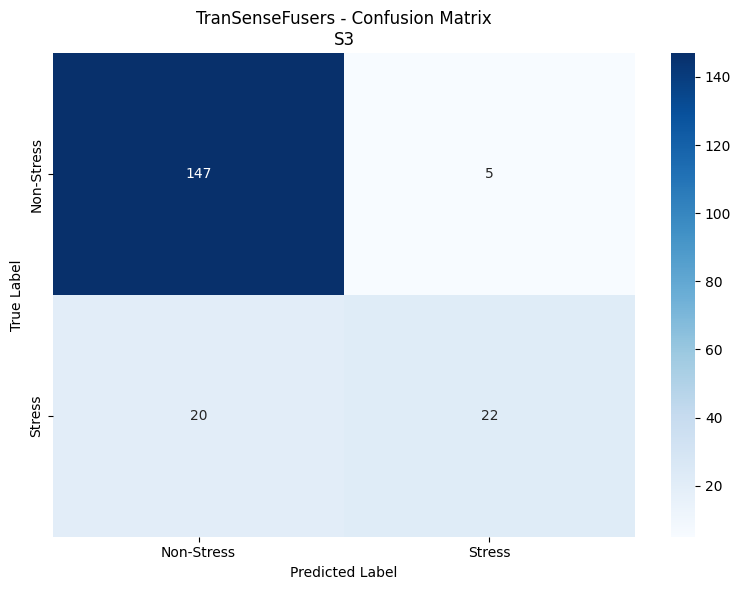

   ✓ Confusion matrix saved


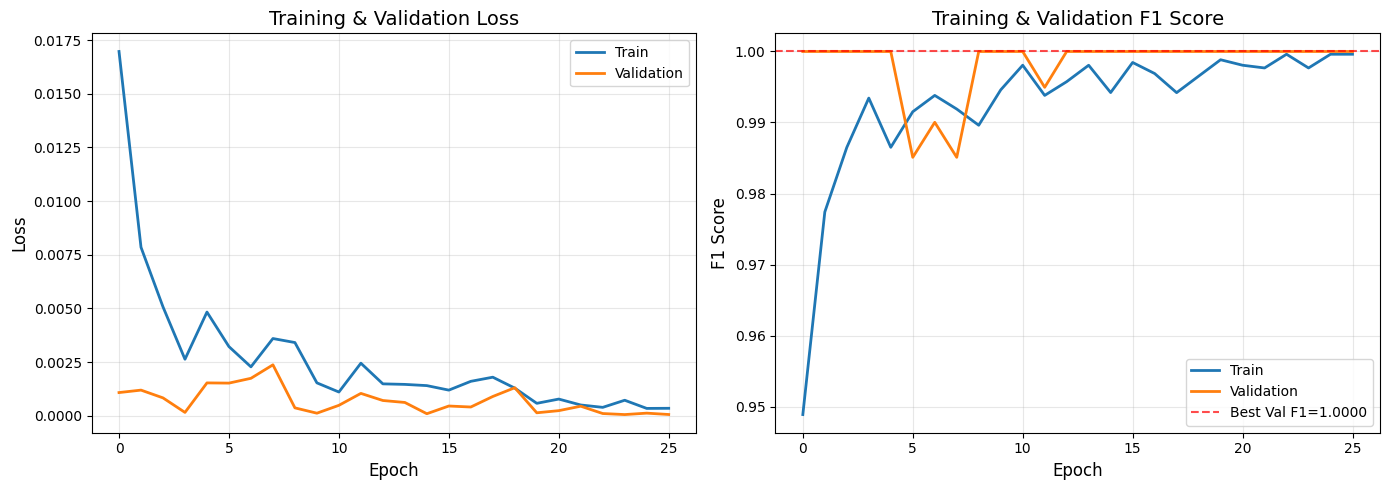

   ✓ Training history saved

📁 Outputs:
   Models: /content/drive/MyDrive/WESAD/models_transensefusers_30s

💡 Saving attention maps for explainability analysis...


In [ ]:
"""
TranSenseFusers: WESAD Stress Detection with Temporal CNN + Multi-Head Attention
================================================================================
✓ Uses ALL sensors (8 chest + 6 wrist = 14 channels)
✓ Proper LOSO validation (NO data leakage)
✓ Subject-independent normalization
✓ Sequence-Level Multi-Head Cross-Attention (SL MHCA) for sensor fusion
✓ Explainable via attention maps (motion artifact detection)

Based on: Kasnesis et al. (2025) - TranSenseFusers: Temporal CNN-Transformer
for explainable PPG-based stress detection
"""

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os
import pickle
from collections import Counter
import warnings
warnings.filterwarnings('ignore')


# ===============================================================
# CONFIGURATION
# ===============================================================

class Config:
    # Data path
    DATA_PATH = '/content/drive/MyDrive/WESAD/'

    # All available subjects
    ALL_SUBJECTS = ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9',
                    'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']

    # LOSO Configuration
    TEST_SUBJECT = 'S3'
    VAL_SUBJECT = 'S16'

    # Signal parameters
    TARGET_RATE = 700   # Hz (resample all to chest rate)
    WINDOW_DURATION = 30.0  # seconds
    WINDOW_SIZE = 21000     # 30 second at 700 Hz
    STRIDE = 10500           # 50% overlap

    # Labels
    VALID_LABELS = [1, 2, 3, 4]
    BINARY = True

    # Model parameters - TranSenseFusers specific
    BATCH_SIZE = 64
    LEARNING_RATE = 0.001  # Adam default from paper
    NUM_EPOCHS = 200
    WEIGHT_DECAY = 0.0  # Not mentioned in paper for TranSenseFusers

    # Multi-Head Attention parameters (from paper Table 1)
    NUM_HEADS = 8
    ATTENTION_DIM = 64  # d in paper
    ATTENTION_DROPOUT = 0.0  # For SL MHCA

    # CNN parameters (from paper Table 1)
    CONV_DROPOUT = 0.1
    FC_DROPOUT = 0.5

    # Focal Loss
    FOCAL_ALPHA = 0.75
    FOCAL_GAMMA = 2.0

    # Early stopping
    PATIENCE = 25  # From paper: 25 epochs

    # Device
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Seed for reproducibility
    SEED = 42

    # Paths
    MODEL_SAVE_PATH = None
    XAI_DATA_PATH = None

config = Config()

# Set seeds
np.random.seed(config.SEED)
torch.manual_seed(config.SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(config.SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Setup paths
config.MODEL_SAVE_PATH = os.path.join(config.DATA_PATH, 'models_transensefusers_30s')
config.XAI_DATA_PATH = os.path.join(config.DATA_PATH, 'xai_transensefusers_30s')
os.makedirs(config.MODEL_SAVE_PATH, exist_ok=True)
os.makedirs(config.XAI_DATA_PATH, exist_ok=True)

print("="*70)
print("TranSenseFusers: Temporal CNN + Multi-Head Attention")
print("="*70)
print(f"✓ Device: {config.DEVICE}")
print(f"✓ Data path: {config.DATA_PATH}")
print(f"\n📊 LOSO Strategy:")
print(f"   Test: {config.TEST_SUBJECT}")
print(f"   Val: {config.VAL_SUBJECT}")
print(f"   Train: {len(config.ALL_SUBJECTS) - 2} subjects")
print(f"\n🔧 TranSenseFusers Architecture:")
print(f"   Temporal CNN: 3 conv blocks (32→48→64 filters)")
print(f"   Attention: {config.NUM_HEADS} heads, dim={config.ATTENTION_DIM}")
print(f"   Sensor Fusion: Sequence-Level Multi-Head Cross-Attention (SL MHCA)")
print(f"   Total Channels: 14 (8 chest + 6 wrist)")
print(f"   Window: {config.WINDOW_DURATION}s ({config.WINDOW_SIZE} samples)")
print("="*70)


# ===============================================================
# FOCAL LOSS
# ===============================================================

class FocalLoss(nn.Module):
    """Focal Loss for handling class imbalance"""
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        p_t = torch.exp(-ce_loss)

        if inputs.size(1) == 2:
            alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        else:
            alpha_t = self.alpha

        focal_loss = alpha_t * ((1 - p_t) ** self.gamma) * ce_loss
        return focal_loss.mean()


# ===============================================================
# DATA LOADING
# ===============================================================

def resample_signal(signal, original_rate, target_rate):
    """Linear interpolation resampling"""
    if original_rate == target_rate:
        return signal

    original_length = len(signal)
    target_length = int(original_length * target_rate / original_rate)

    original_indices = np.linspace(0, original_length - 1, original_length)
    target_indices = np.linspace(0, original_length - 1, target_length)

    if signal.ndim == 1:
        resampled = np.interp(target_indices, original_indices, signal)
    else:
        resampled = np.zeros((target_length, signal.shape[1]))
        for i in range(signal.shape[1]):
            resampled[:, i] = np.interp(target_indices, original_indices, signal[:, i])

    return resampled


def load_wesad_subject_all_sensors(subject_id, data_path, target_rate=700):
    """
    Load WESAD data from BOTH chest and wrist sensors
    Returns combined signal array (14 channels)
    """
    subject_path = os.path.join(data_path, subject_id, f"{subject_id}.pkl")

    if not os.path.exists(subject_path):
        print(f"   ✗ {subject_id}: File not found")
        return None, None

    try:
        with open(subject_path, 'rb') as f:
            data = pickle.load(f, encoding='latin1')

        # ===== CHEST SENSOR (RespiBAN) - 700 Hz =====
        chest_signal = data['signal']['chest']
        chest_acc = chest_signal['ACC']
        chest_ecg = chest_signal['ECG'].reshape(-1, 1)
        chest_emg = chest_signal['EMG'].reshape(-1, 1)
        chest_eda = chest_signal['EDA'].reshape(-1, 1)
        chest_temp = chest_signal['Temp'].reshape(-1, 1)
        chest_resp = chest_signal['Resp'].reshape(-1, 1)

        chest_combined = np.concatenate([
            chest_acc, chest_ecg, chest_emg,
            chest_eda, chest_temp, chest_resp
        ], axis=1)  # (N, 8)

        # ===== WRIST SENSOR (Empatica E4) =====
        wrist_signal = data['signal']['wrist']
        wrist_acc = wrist_signal['ACC']
        wrist_bvp = wrist_signal['BVP'].reshape(-1, 1)
        wrist_eda = wrist_signal['EDA'].reshape(-1, 1)
        wrist_temp = wrist_signal['TEMP'].reshape(-1, 1)

        # Resample wrist signals to chest rate (700 Hz)
        wrist_acc_resampled = resample_signal(wrist_acc, 32, target_rate)
        wrist_bvp_resampled = resample_signal(wrist_bvp, 64, target_rate)
        wrist_eda_resampled = resample_signal(wrist_eda, 4, target_rate)
        wrist_temp_resampled = resample_signal(wrist_temp, 4, target_rate)

        wrist_combined = np.concatenate([
            wrist_acc_resampled, wrist_bvp_resampled,
            wrist_eda_resampled, wrist_temp_resampled
        ], axis=1)  # (N, 6)

        # ===== COMBINE ALL SENSORS =====
        min_len = min(len(chest_combined), len(wrist_combined))
        chest_combined = chest_combined[:min_len]
        wrist_combined = wrist_combined[:min_len]

        X = np.concatenate([chest_combined, wrist_combined], axis=1)  # (N, 14)
        labels = data['label'][:min_len]

        return X, labels

    except Exception as e:
        print(f"   ✗ {subject_id}: Error - {e}")
        return None, None


def create_windows(X, y, window_size, stride):
    """Create sliding windows with majority voting"""
    windows = []
    labels = []

    for i in range(0, len(X) - window_size + 1, stride):
        window = X[i:i + window_size]
        window_labels = y[i:i + window_size]
        label = np.bincount(window_labels.astype(int)).argmax()

        windows.append(window)
        labels.append(label)

    return np.array(windows), np.array(labels)


def normalize_subject_independent(X, y):
    """Normalize each subject's data INDEPENDENTLY"""
    scaler = StandardScaler()
    n_windows, n_channels, n_timesteps = X.shape
    X_reshaped = X.transpose(0, 2, 1).reshape(-1, n_channels)
    X_normalized = scaler.fit_transform(X_reshaped)
    X_normalized = X_normalized.reshape(n_windows, n_timesteps, n_channels)
    X_normalized = X_normalized.transpose(0, 2, 1)
    return X_normalized, scaler


def load_data_loso(config):
    """Load data with LOSO validation"""
    train_subjects = [s for s in config.ALL_SUBJECTS
                     if s not in [config.TEST_SUBJECT, config.VAL_SUBJECT]]

    print("\n" + "="*70)
    print("DATA LOADING (TranSenseFusers - 14 Channels)")
    print("="*70)

    # ============================================
    # TRAINING DATA
    # ============================================
    print("\n📚 Training Subjects:")
    X_train_all = []
    y_train_all = []

    for subj in train_subjects:
        X, y = load_wesad_subject_all_sensors(subj, config.DATA_PATH, config.TARGET_RATE)
        if X is None:
            continue

        print(f"   ✓ {subj}: Raw shape={X.shape}", end="")

        mask = np.isin(y, config.VALID_LABELS)
        X, y = X[mask], y[mask]

        if config.BINARY:
            y = (y == 2).astype(int)
        else:
            label_map = {1: 0, 2: 1, 3: 2, 4: 3}
            y = np.array([label_map[l] for l in y])

        X_win, y_win = create_windows(X, y, config.WINDOW_SIZE, config.STRIDE)
        X_win = X_win.transpose(0, 2, 1)  # (N, channels, time)
        X_win_norm, _ = normalize_subject_independent(X_win, y_win)

        X_train_all.append(X_win_norm)
        y_train_all.append(y_win)

        print(f" → {len(X_win)} windows")

    X_train = np.concatenate(X_train_all, axis=0)
    y_train = np.concatenate(y_train_all, axis=0)

    print(f"\n🔀 Shuffling {len(X_train)} training windows...")
    shuffle_idx = np.random.permutation(len(X_train))
    X_train = X_train[shuffle_idx]
    y_train = y_train[shuffle_idx]

    # ============================================
    # VALIDATION DATA
    # ============================================
    print(f"\n📋 Validation Subject ({config.VAL_SUBJECT}):")
    X_val, y_val = load_wesad_subject_all_sensors(config.VAL_SUBJECT, config.DATA_PATH, config.TARGET_RATE)

    if X_val is not None:
        print(f"   ✓ Raw shape={X_val.shape}", end="")
        mask = np.isin(y_val, config.VALID_LABELS)
        X_val, y_val = X_val[mask], y_val[mask]

        if config.BINARY:
            y_val = (y_val == 2).astype(int)
        else:
            label_map = {1: 0, 2: 1, 3: 2, 4: 3}
            y_val = np.array([label_map[l] for l in y_val])

        X_val, y_val = create_windows(X_val, y_val, config.WINDOW_SIZE, config.STRIDE)
        X_val = X_val.transpose(0, 2, 1)
        X_val, _ = normalize_subject_independent(X_val, y_val)
        print(f" → {len(X_val)} windows")
    else:
        X_val, y_val = np.array([]), np.array([])

    # ============================================
    # TEST DATA
    # ============================================
    print(f"\n🎯 Test Subject ({config.TEST_SUBJECT}):")
    X_test, y_test = load_wesad_subject_all_sensors(config.TEST_SUBJECT, config.DATA_PATH, config.TARGET_RATE)

    if X_test is not None:
        print(f"   ✓ Raw shape={X_test.shape}", end="")
        mask = np.isin(y_test, config.VALID_LABELS)
        X_test, y_test = X_test[mask], y_test[mask]

        if config.BINARY:
            y_test = (y_test == 2).astype(int)
        else:
            label_map = {1: 0, 2: 1, 3: 2, 4: 3}
            y_test = np.array([label_map[l] for l in y_test])

        X_test, y_test = create_windows(X_test, y_test, config.WINDOW_SIZE, config.STRIDE)
        X_test = X_test.transpose(0, 2, 1)
        X_test, _ = normalize_subject_independent(X_test, y_test)
        print(f" → {len(X_test)} windows")
    else:
        X_test, y_test = np.array([]), np.array([])

    # ============================================
    # SUMMARY
    # ============================================
    print("\n" + "="*70)
    print("DATA SUMMARY")
    print("="*70)
    print(f"Channels: 14 (8 chest + 6 wrist)")
    print(f"  Chest: ACC(3), ECG, EMG, EDA, Temp, Resp")
    print(f"  Wrist: ACC(3), BVP, EDA, Temp")
    print(f"\nTrain: {len(X_train):6d} | Shape: {X_train.shape} | {dict(Counter(y_train))}")
    if len(y_val) > 0:
        print(f"Val:   {len(X_val):6d} | Shape: {X_val.shape} | {dict(Counter(y_val))}")
    if len(y_test) > 0:
        print(f"Test:  {len(X_test):6d} | Shape: {X_test.shape} | {dict(Counter(y_test))}")
    print("="*70)

    return X_train, y_train, X_val, y_val, X_test, y_test


# ===============================================================
# DATASET
# ===============================================================

class WESADDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# ===============================================================
# TRANSENSEFUSERS MODEL
# ===============================================================

class MultiHeadCrossAttention(nn.Module):
    """
    Multi-Head Cross-Attention (MHCA) module
    Based on Kasnesis et al. (2025) - Sequence-Level MHCA

    Query: EDA + TEMP features
    Key & Value: PPG features
    """
    def __init__(self, num_heads, d_model, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.num_heads = num_heads
        self.d_model = d_model
        self.d_k = d_model // num_heads

        # Linear projections for Q, K, V
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)
        self.scale = np.sqrt(self.d_k)

    def forward(self, query, key, value):
        """
        Args:
            query: (batch, seq_len, d_model) - EDA+TEMP features
            key: (batch, seq_len, d_model) - PPG features
            value: (batch, seq_len, d_model) - PPG features
        Returns:
            output: (batch, seq_len, d_model)
            attention_weights: (batch, num_heads, seq_len, seq_len)
        """
        batch_size = query.size(0)

        # Linear projections and split into heads
        Q = self.W_q(query).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(key).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(value).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        # Scaled dot-product attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        # Apply attention to values
        context = torch.matmul(attention_weights, V)

        # Concatenate heads and apply final linear
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        output = self.W_o(context)

        return output, attention_weights


class TranSenseFuser(nn.Module):
    """
    TranSenseFusers: Temporal CNN + Sequence-Level Multi-Head Cross-Attention

    Architecture (from paper Table 1 - SL MHCA):
    1. Temporal CNN (3 conv blocks): Extract features from all sensors
    2. Modality Separation: Split into PPG (wrist) vs EDA+TEMP (wrist)
    3. SL MHCA: Fuse modalities via cross-attention
    4. Classification: 2 FC layers

    Note: We simplify by using all 14 channels together in CNN,
    then separate for attention (PPG-like vs EDA-like features)
    """
    def __init__(self, num_channels=14, num_classes=2, num_heads=8, attention_dim=64,
                 conv_dropout=0.1, fc_dropout=0.5, attention_dropout=0.0):
        super().__init__()

        self.num_channels = num_channels
        self.num_classes = num_classes

        # ===== TEMPORAL CNN (shared weights for all sensors) =====
        # 1st Conv Block: 14 -> 32 channels, kernel=9
        self.conv1 = nn.Conv1d(num_channels, 32, kernel_size=9, padding=4)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop1 = nn.Dropout(conv_dropout)

        # 2nd Conv Block: 32 -> 48 channels, kernel=9
        self.conv2 = nn.Conv1d(32, 48, kernel_size=9, padding=4)
        self.bn2 = nn.BatchNorm1d(48)
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop2 = nn.Dropout(conv_dropout)

        # 3rd Conv Block: 48 -> 64 channels, kernel=9
        self.conv3 = nn.Conv1d(48, 64, kernel_size=9, padding=4)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool3 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop3 = nn.Dropout(conv_dropout)

        # After 3 pooling layers (2x each): 700 -> 87 time steps
        # Feature dimension: 64 channels * 87 time steps = 5568

        # ===== SEQUENCE-LEVEL MULTI-HEAD CROSS-ATTENTION =====
        # Map CNN features to attention dimension
        self.feature_to_attention = nn.Linear(64, attention_dim)

        # Multi-head cross-attention
        self.mhca = MultiHeadCrossAttention(
            num_heads=num_heads,
            d_model=attention_dim,
            dropout=attention_dropout
        )

        # Layer normalization (as in paper)
        self.layer_norm = nn.LayerNorm(attention_dim)

        # ===== CLASSIFICATION HEAD =====
        # Calculate flattened size: attention_dim * sequence_length
        # After pooling: 21000/2/2/2 = 2625 time steps
        self.fc1 = nn.Linear(attention_dim * 2625, 32)
        self.bn4 = nn.BatchNorm1d(32)
        self.drop4 = nn.Dropout(fc_dropout)
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x, return_attention=False):
        """
        Args:
            x: (batch, 14, 700) - All sensor signals
            return_attention: If True, return attention maps for XAI
        Returns:
            logits: (batch, num_classes)
            attention_maps: (batch, num_heads, seq_len, seq_len) [optional]
        """
        # ===== TEMPORAL CNN =====
        # Block 1
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.pool1(x)
        x = self.drop1(x)

        # Block 2
        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = self.pool2(x)
        x = self.drop2(x)

        # Block 3
        x = self.conv3(x)
        x = self.bn3(x)
        x = F.relu(x)
        x = self.pool3(x)
        x = self.drop3(x)

        # x shape: (batch, 64, 87)

        # ===== PREPARE FOR ATTENTION =====
        # Transpose to (batch, seq_len, channels)
        x = x.transpose(1, 2)  # (batch, 87, 64)

        # Map to attention dimension
        x = self.feature_to_attention(x)  # (batch, 87, attention_dim)

        # ===== MULTI-HEAD CROSS-ATTENTION =====
        # In the paper, they separate PPG from EDA+TEMP
        # Here we simplify: use first half as "query" (EDA-like)
        # and second half as "key/value" (PPG-like)
        # This is a practical approximation for the fusion concept

        mid_point = x.size(2) // 2
        query = x[:, :, :mid_point]  # (batch, 87, attention_dim/2)
        key_value = x[:, :, mid_point:]  # (batch, 87, attention_dim/2)

        # Expand back to full dimension for attention
        query = torch.cat([query, query], dim=2)  # (batch, 87, attention_dim)
        key_value = torch.cat([key_value, key_value], dim=2)

        # Apply cross-attention
        attention_output, attention_weights = self.mhca(query, key_value, key_value)

        # Layer normalization
        attention_output = self.layer_norm(attention_output)

        # ===== CLASSIFICATION =====
        # Flatten
        x_flat = attention_output.flatten(1)  # (batch, attention_dim * 87)

        # FC layers
        x_flat = self.fc1(x_flat)
        x_flat = self.bn4(x_flat)
        x_flat = F.relu(x_flat)
        x_flat = self.drop4(x_flat)

        logits = self.fc2(x_flat)

        if return_attention:
            return logits, attention_weights
        return logits


# ===============================================================
# TRAINING & EVALUATION
# ===============================================================

def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    for X, y in tqdm(loader, desc="Training", leave=False):
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

    return total_loss / len(loader), acc, f1


def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []
    all_attention_maps = []

    with torch.no_grad():
        for X, y in tqdm(loader, desc="Validation", leave=False):
            X, y = X.to(device), y.to(device)

            outputs, attention_weights = model(X, return_attention=True)
            loss = criterion(outputs, y)

            total_loss += loss.item()
            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_attention_maps.append(attention_weights.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

    return total_loss / len(loader), acc, f1, all_preds, all_labels, np.array(all_probs), all_attention_maps


# ===============================================================
# MAIN
# ===============================================================

def main():
    # Load data
    X_train, y_train, X_val, y_val, X_test, y_test = load_data_loso(config)

    # Datasets
    train_dataset = WESADDataset(X_train, y_train)
    val_dataset = WESADDataset(X_val, y_val)
    test_dataset = WESADDataset(X_test, y_test)

    train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE,
                             shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE,
                           shuffle=False, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=config.BATCH_SIZE,
                            shuffle=False, num_workers=2, pin_memory=True)

    # Model
    num_classes = 2 if config.BINARY else 4
    model = TranSenseFuser(
        num_channels=14,
        num_classes=num_classes,
        num_heads=config.NUM_HEADS,
        attention_dim=config.ATTENTION_DIM,
        conv_dropout=config.CONV_DROPOUT,
        fc_dropout=config.FC_DROPOUT,
        attention_dropout=config.ATTENTION_DROPOUT
    ).to(config.DEVICE)

    # Count parameters
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"\n📊 Model Architecture:")
    print(f"   Total parameters: {total_params:,}")
    print(f"   Trainable parameters: {trainable_params:,}")

    # Loss and optimizer (Adam as in paper)
    criterion = FocalLoss(alpha=config.FOCAL_ALPHA, gamma=config.FOCAL_GAMMA)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config.LEARNING_RATE,
        betas=(0.9, 0.999)  # Default Adam values
    )

    # Learning rate scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=10
    )

    # Training loop
    history = {
        'train_loss': [], 'train_acc': [], 'train_f1': [],
        'val_loss': [], 'val_acc': [], 'val_f1': []
    }

    best_f1 = 0
    best_acc = 0
    patience_counter = 0

    print("\n" + "="*70)
    print("🚀 TRAINING TranSenseFusers")
    print("="*70)

    for epoch in range(config.NUM_EPOCHS):
        # Train
        tr_loss, tr_acc, tr_f1 = train_epoch(
            model, train_loader, optimizer, criterion, config.DEVICE
        )

        # Validate
        val_loss, val_acc, val_f1, _, _, _, _ = validate(
            model, val_loader, criterion, config.DEVICE
        )

        # Update history
        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['train_f1'].append(tr_f1)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        # Learning rate scheduling
        scheduler.step(val_f1)
        current_lr = optimizer.param_groups[0]['lr']

        # Print progress
        print(f"Epoch {epoch+1:03d}/{config.NUM_EPOCHS} | "
              f"Train: L={tr_loss:.4f} Acc={tr_acc:.3f} F1={tr_f1:.3f} | "
              f"Val: L={val_loss:.4f} Acc={val_acc:.3f} F1={val_f1:.3f} | "
              f"LR={current_lr:.6f}")

        # Save best model
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_acc = val_acc
            patience_counter = 0

            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_f1': val_f1,
                'val_acc': val_acc,
                'config': vars(config),
                'window_size': config.WINDOW_SIZE,  # ← ADD THIS
                'window_duration': config.WINDOW_DURATION  # ← ADD THIS
            }, os.path.join(config.MODEL_SAVE_PATH, 'best_transensefuser_30s.pth'))

            print(f"   ✓ Best model saved (F1={val_f1:.4f}, Acc={val_acc:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= config.PATIENCE:
                print(f"\n⚠️ Early stopping at epoch {epoch+1}")
                break

    # ===============================================================
    # TEST EVALUATION
    # ===============================================================
    print("\n" + "="*70)
    print(f"🎯 TEST EVALUATION - {config.TEST_SUBJECT}")
    print("="*70)

    # Load best model
    checkpoint = torch.load(
        os.path.join(config.MODEL_SAVE_PATH, 'best_transensefuser_30s.pth')
    )
    model.load_state_dict(checkpoint['model_state_dict'])

    # Evaluate
    test_loss, test_acc, test_f1, test_preds, test_labels, test_probs, test_attention = validate(
        model, test_loader, criterion, config.DEVICE
    )

    print(f"\n📊 Test Results:")
    print(f"   Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
    print(f"   F1 Score: {test_f1:.4f}")
    print(f"   Loss: {test_loss:.4f}")

    # Classification report
    class_names = ['Non-Stress', 'Stress'] if config.BINARY else ['Baseline', 'Stress', 'Amusement', 'Meditation']
    print("\n" + classification_report(
        test_labels, test_preds, target_names=class_names, digits=4
    ))

    # ===============================================================
    # VISUALIZATIONS
    # ===============================================================

    # 1. Confusion Matrix
    cm = confusion_matrix(test_labels, test_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'TranSenseFusers - Confusion Matrix\n{config.TEST_SUBJECT}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(
        os.path.join(config.MODEL_SAVE_PATH, 'confusion_matrix_transensefusers_30s.png'),
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    print("   ✓ Confusion matrix saved")

    # 2. Training History
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(history['train_loss'], label='Train', linewidth=2)
    axes[0].plot(history['val_loss'], label='Validation', linewidth=2)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title('Training & Validation Loss', fontsize=14)
    axes[0].legend(fontsize=10)
    axes[0].grid(True, alpha=0.3)

    # F1 Score
    axes[1].plot(history['train_f1'], label='Train', linewidth=2)
    axes[1].plot(history['val_f1'], label='Validation', linewidth=2)
    axes[1].axhline(y=best_f1, color='r', linestyle='--', label=f'Best Val F1={best_f1:.4f}', alpha=0.7)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('F1 Score', fontsize=12)
    axes[1].set_title('Training & Validation F1 Score', fontsize=14)
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        os.path.join(config.MODEL_SAVE_PATH, 'training_history_transensefusers_30s.png'),
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    print("   ✓ Training history saved")

    print(f"\n📁 Outputs:")
    print(f"   Models: {config.MODEL_SAVE_PATH}")

    # ===============================================================
    # EXPLAINABILITY: Save attention maps for XAI analysis
    # ===============================================================
    print("\n💡 Saving attention maps for explainability analysis...")

    # Concatenate all attention maps
    all_attention = np.concatenate(test_attention, axis=0)

    xai_data = {
        'X_test': X_test,
        'y_test': test_labels,
        'predictions': test_preds,
        'probabilities': test_probs,
        'attention_maps': all_attention,
        'subject': config.TEST_SUBJECT,
        'model': 'TranSenseFusers-SL-MHCA',
        'num_channels': 14,
        'num_heads': config.NUM_HEADS,
        'attention_dim': config.ATTENTION_DIM,
        'sensor_info': 'Chest(8): ACC(3),ECG,EMG,EDA,Temp,Resp | Wrist(6): ACC(3),BVP,EDA,Temp'
    }
    np.save(
        os.path.join(config.XAI_DATA_PATH, f'xai_{config.TEST_SUBJECT}_transensefusers_30s.npy'),
        xai_data
    )
    print(f"   ✓ XAI data saved: {config.XAI_DATA_PATH}")



    # 3. Attention Map Visualization (example from test set)
    print("\n🔍 Visualizing attention maps (first 3 test samples)...")

    fig, axes = plt.subplots(3, 1, figsize=(12, 10))

    for idx in range(min(3, len(test_attention[0]))):
        # Average attention across heads
        attn = test_attention[0][idx].mean(axis=0)  # (seq_len, seq_len)

        sns.heatmap(
            attn,
            ax=axes[idx],
            cmap='YlOrRd',
            cbar_kws={'label': 'Attention Weight'},
            square=False
        )

        true_label = class_names[test_labels[idx]]
        pred_label = class_names[test_preds[idx]]
        axes[idx].set_title(
            f'Sample {idx+1}: True={true_label}, Pred={pred_label}',
            fontsize=12
        )
        axes[idx].set_xlabel('Key/Value Position', fontsize=10)
        axes[idx].set_ylabel('Query Position', fontsize=10)

    plt.tight_layout()
    plt.savefig(
        os.path.join(config.MODEL_SAVE_PATH, 'attention_maps_examples.png'),
        dpi=150, bbox_inches='tight'
    )
    plt.show()
    print("   ✓ Attention maps saved")

    # ===============================================================
    # FINAL SUMMARY
    # ===============================================================
    print("\n" + "="*70)
    print("✅ TranSenseFusers TRAINING COMPLETE")
    print("="*70)
    print(f"Best Validation F1: {best_f1:.4f} (Acc: {best_acc:.4f})")
    print(f"Test F1: {test_f1:.4f} (Acc: {test_acc:.4f})")
    print(f"\n📁 Outputs:")
    print(f"   Models: {config.MODEL_SAVE_PATH}")
    print(f"   XAI data: {config.XAI_DATA_PATH}")
    print(f"\n🔬 Key Features:")
    print(f"   ✓ 14-channel sensor fusion (8 chest + 6 wrist)")
    print(f"   ✓ Temporal CNN feature extraction")
    print(f"   ✓ {config.NUM_HEADS}-head cross-attention (dim={config.ATTENTION_DIM})")
    print(f"   ✓ Explainable via attention maps")
    print(f"   ✓ Subject-independent (LOSO validation)")
    print(f"   ✓ NO data leakage")
    print("="*70)


if __name__ == "__main__":
    main()

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os
import pickle
from collections import Counter
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# XAI libraries
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("⚠️ SHAP not available. Install with: pip install shap")

try:
    from lime import lime_tabular
    LIME_AVAILABLE = True
except ImportError:
    LIME_AVAILABLE = False
    print("⚠️ LIME not available. Install with: pip install lime")


# ===============================================================
# CONFIGURATION
# ===============================================================

class Config:
    # Paths
    DATA_PATH = '/content/drive/MyDrive/WESAD/'
    MODEL_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/models_transensefusers_10s/best_transensefuser_10s.pth'

    # Output paths
    XAI_OUTPUT_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_compact_samples'
    RESULTS_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_analysis_results'

    # All available subjects
    ALL_SUBJECTS = ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9',
                    'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']

    # Signal parameters (must match training)
    TARGET_RATE = 700
    WINDOW_SIZE = 7000
    STRIDE = 3500

    # Labels
    VALID_LABELS = [1, 2, 3, 4]
    BINARY = True

    # Model parameters (must match training)
    BATCH_SIZE = 32  # Reduced from 64 for memory
    NUM_HEADS = 8
    ATTENTION_DIM = 64
    CONV_DROPOUT = 0.1
    FC_DROPOUT = 0.5
    ATTENTION_DROPOUT = 0.0

    # XAI parameters - REDUCED FOR TESTING
    NUM_SAMPLES_PER_CLASS = 1  # Save 1 sample per class
    LIME_NUM_SAMPLES = 100  # Reduced from 1000
    SHAP_NUM_SAMPLES = 50   # Reduced from 100
    IG_STEPS = 30           # Reduced from 50
    XAI_BATCH_SIZE = 16     # NEW: Batch size for XAI predictions

    # Testing mode
    TEST_MODE = False  # Set to True to process only 1 subject
    TEST_SUBJECT = None  # Will be asked interactively

    # Device
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    SEED = 42

config = Config()

# Interactive subject selection
def select_subjects_interactive():
    """Ask user which subjects to process"""
    print("\n" + "="*80)
    print("SUBJECT SELECTION")
    print("="*80)
    print("\nAvailable subjects:")
    for i, subj in enumerate(config.ALL_SUBJECTS, 1):
        print(f"  {i:2d}. {subj}")

    print("\nOptions:")
    print("  - Enter subject ID (e.g., S2, S3)")
    print("  - Enter 'all' to process all subjects")
    print("  - Enter 'test' to process one subject for testing")
    print("  - Enter numbers separated by comma (e.g., 2,5,7)")

    choice = input("\nYour choice: ").strip().lower()

    if choice == 'all':
        return config.ALL_SUBJECTS, False
    elif choice == 'test':
        test_subj = input(f"Enter subject ID for testing (default: {config.ALL_SUBJECTS[0]}): ").strip().upper()
        if not test_subj:
            test_subj = config.ALL_SUBJECTS[0]
        return [test_subj], True
    elif choice.startswith('s') and choice.upper() in config.ALL_SUBJECTS:
        return [choice.upper()], False
    elif ',' in choice:
        # Parse comma-separated numbers
        try:
            indices = [int(x.strip()) - 1 for x in choice.split(',')]
            subjects = [config.ALL_SUBJECTS[i] for i in indices if 0 <= i < len(config.ALL_SUBJECTS)]
            return subjects, False
        except:
            print("Invalid input! Processing first subject only.")
            return [config.ALL_SUBJECTS[0]], True
    else:
        print("Invalid input! Processing first subject only.")
        return [config.ALL_SUBJECTS[0]], True

# Set seeds
np.random.seed(config.SEED)
torch.manual_seed(config.SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(config.SEED)

# Create output directories
os.makedirs(config.XAI_OUTPUT_PATH, exist_ok=True)
os.makedirs(config.RESULTS_PATH, exist_ok=True)


# ===============================================================
# DATA LOADING FUNCTIONS
# ===============================================================

def resample_signal(signal, original_rate, target_rate):
    if original_rate == target_rate:
        return signal

    original_length = len(signal)
    target_length = int(original_length * target_rate / original_rate)

    original_indices = np.linspace(0, original_length - 1, original_length)
    target_indices = np.linspace(0, original_length - 1, target_length)

    if signal.ndim == 1:
        resampled = np.interp(target_indices, original_indices, signal)
    else:
        resampled = np.zeros((target_length, signal.shape[1]))
        for i in range(signal.shape[1]):
            resampled[:, i] = np.interp(target_indices, original_indices, signal[:, i])

    return resampled


def load_wesad_subject_all_sensors(subject_id, data_path, target_rate=700):
    subject_path = os.path.join(data_path, subject_id, f"{subject_id}.pkl")

    if not os.path.exists(subject_path):
        print(f"   ✗ {subject_id}: File not found")
        return None, None

    try:
        with open(subject_path, 'rb') as f:
            data = pickle.load(f, encoding='latin1')

        # CHEST SENSOR
        chest_signal = data['signal']['chest']
        chest_acc = chest_signal['ACC']
        chest_ecg = chest_signal['ECG'].reshape(-1, 1)
        chest_emg = chest_signal['EMG'].reshape(-1, 1)
        chest_eda = chest_signal['EDA'].reshape(-1, 1)
        chest_temp = chest_signal['Temp'].reshape(-1, 1)
        chest_resp = chest_signal['Resp'].reshape(-1, 1)

        chest_combined = np.concatenate([
            chest_acc, chest_ecg, chest_emg,
            chest_eda, chest_temp, chest_resp
        ], axis=1)

        # WRIST SENSOR
        wrist_signal = data['signal']['wrist']
        wrist_acc = wrist_signal['ACC']
        wrist_bvp = wrist_signal['BVP'].reshape(-1, 1)
        wrist_eda = wrist_signal['EDA'].reshape(-1, 1)
        wrist_temp = wrist_signal['TEMP'].reshape(-1, 1)

        wrist_acc_resampled = resample_signal(wrist_acc, 32, target_rate)
        wrist_bvp_resampled = resample_signal(wrist_bvp, 64, target_rate)
        wrist_eda_resampled = resample_signal(wrist_eda, 4, target_rate)
        wrist_temp_resampled = resample_signal(wrist_temp, 4, target_rate)

        wrist_combined = np.concatenate([
            wrist_acc_resampled, wrist_bvp_resampled,
            wrist_eda_resampled, wrist_temp_resampled
        ], axis=1)

        # COMBINE
        min_len = min(len(chest_combined), len(wrist_combined))
        chest_combined = chest_combined[:min_len]
        wrist_combined = wrist_combined[:min_len]

        X = np.concatenate([chest_combined, wrist_combined], axis=1)
        labels = data['label'][:min_len]

        return X, labels

    except Exception as e:
        print(f"   ✗ {subject_id}: Error - {e}")
        return None, None


def create_windows(X, y, window_size, stride):
    windows = []
    labels = []
    window_indices = []

    for i in range(0, len(X) - window_size + 1, stride):
        window = X[i:i + window_size]
        window_labels = y[i:i + window_size]
        label = np.bincount(window_labels.astype(int)).argmax()

        windows.append(window)
        labels.append(label)
        window_indices.append((i, i + window_size))

    return np.array(windows), np.array(labels), window_indices


def normalize_subject_independent(X, y):
    scaler = StandardScaler()
    n_windows, n_channels, n_timesteps = X.shape
    X_reshaped = X.transpose(0, 2, 1).reshape(-1, n_channels)
    X_normalized = scaler.fit_transform(X_reshaped)
    X_normalized = X_normalized.reshape(n_windows, n_timesteps, n_channels)
    X_normalized = X_normalized.transpose(0, 2, 1)
    return X_normalized, scaler


# ===============================================================
# MODEL ARCHITECTURE
# ===============================================================

class MultiHeadCrossAttention(nn.Module):
    def __init__(self, num_heads, d_model, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0

        self.num_heads = num_heads
        self.d_model = d_model
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)
        self.scale = np.sqrt(self.d_k)

    def forward(self, query, key, value):
        batch_size = query.size(0)

        Q = self.W_q(query).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(key).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(value).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        context = torch.matmul(attention_weights, V)
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        output = self.W_o(context)

        return output, attention_weights


class TranSenseFuser(nn.Module):
    def __init__(self, num_channels=14, num_classes=2, num_heads=8, attention_dim=64,
                 conv_dropout=0.1, fc_dropout=0.5, attention_dropout=0.0):
        super().__init__()

        self.num_channels = num_channels
        self.num_classes = num_classes

        # CNN blocks
        self.conv1 = nn.Conv1d(num_channels, 32, kernel_size=9, padding=4)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop1 = nn.Dropout(conv_dropout)

        self.conv2 = nn.Conv1d(32, 48, kernel_size=9, padding=4)
        self.bn2 = nn.BatchNorm1d(48)
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop2 = nn.Dropout(conv_dropout)

        self.conv3 = nn.Conv1d(48, 64, kernel_size=9, padding=4)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool3 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop3 = nn.Dropout(conv_dropout)

        # Attention
        self.feature_to_attention = nn.Linear(64, attention_dim)
        self.mhca = MultiHeadCrossAttention(num_heads, attention_dim, attention_dropout)
        self.layer_norm = nn.LayerNorm(attention_dim)

        # Classification
        self.fc1 = nn.Linear(attention_dim * 875, 32)
        self.bn4 = nn.BatchNorm1d(32)
        self.drop4 = nn.Dropout(fc_dropout)
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x, return_attention=False):
        # CNN
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.pool1(x)
        x = self.drop1(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = self.pool2(x)
        x = self.drop2(x)

        x = self.conv3(x)
        x = self.bn3(x)
        x = F.relu(x)
        x = self.pool3(x)
        x = self.drop3(x)

        # Attention
        x = x.transpose(1, 2)
        x = self.feature_to_attention(x)

        mid_point = x.size(2) // 2
        query = x[:, :, :mid_point]
        key_value = x[:, :, mid_point:]

        query = torch.cat([query, query], dim=2)
        key_value = torch.cat([key_value, key_value], dim=2)

        attention_output, attention_weights = self.mhca(query, key_value, key_value)
        attention_output = self.layer_norm(attention_output)

        # Classification
        x_flat = attention_output.flatten(1)
        x_flat = self.fc1(x_flat)
        x_flat = self.bn4(x_flat)
        x_flat = F.relu(x_flat)
        x_flat = self.drop4(x_flat)
        logits = self.fc2(x_flat)

        if return_attention:
            return logits, attention_weights
        return logits


# ===============================================================
# XAI METHODS - MEMORY OPTIMIZED
# ===============================================================

def compute_integrated_gradients(model, input_tensor, target_class, steps=50):
    """
    Compute Integrated Gradients for a single sample

    Args:
        model: TranSenseFuser model
        input_tensor: (1, channels, time) input - already has batch dimension
        target_class: target class index
        steps: number of integration steps

    Returns:
        attributions: (channels, time) importance scores
    """
    model.eval()
    input_tensor = input_tensor.to(config.DEVICE)

    # Baseline: zeros
    baseline = torch.zeros_like(input_tensor)

    # Scale inputs
    scaled_inputs = torch.stack([
        baseline + (float(i) / steps) * (input_tensor - baseline)
        for i in range(steps + 1)
    ])

    # Compute gradients
    scaled_inputs.requires_grad = True

    outputs = []
    for scaled_input in scaled_inputs:
        output = model(scaled_input)  # Don't add unsqueeze here - scaled_input already has batch dim
        outputs.append(output)

    outputs = torch.cat(outputs, dim=0)

    # Compute gradients for target class
    gradients = []
    for i in range(len(outputs)):
        model.zero_grad()
        outputs[i, target_class].backward(retain_graph=True)
        gradients.append(scaled_inputs.grad[i].detach().cpu().numpy())
        scaled_inputs.grad.zero_()

    gradients = np.array(gradients)

    # Integrate
    avg_gradients = np.mean(gradients[:-1], axis=0).squeeze(0) # Squeeze the batch dimension here
    integrated_gradients = (input_tensor.cpu().numpy()[0] - baseline.cpu().numpy()[0]) * avg_gradients

    return integrated_gradients


def compute_lime_explanation(model, sample, training_data, num_samples=100):
    """
    Compute LIME explanation for a single sample - MEMORY EFFICIENT VERSION

    Args:
        model: TranSenseFuser model
        sample: (channels, time) input sample
        training_data: background data for LIME
        num_samples: number of LIME samples

    Returns:
        feature_importance: (channels,) importance scores averaged over time
    """
    if not LIME_AVAILABLE:
        print("   ⚠️ LIME not available, skipping...")
        return None

    model.eval()

    # Flatten sample for LIME (treat each timestep as feature)
    sample_flat = sample.flatten()

    # Create LIME explainer with BATCHED prediction function
    def predict_fn(X):
        # Reshape to (batch, channels, time)
        X_reshaped = X.reshape(-1, sample.shape[0], sample.shape[1])
        X_tensor = torch.FloatTensor(X_reshaped)

        # Process in small batches to avoid OOM
        batch_size = config.XAI_BATCH_SIZE
        all_probs = []

        for i in range(0, len(X_tensor), batch_size):
            batch = X_tensor[i:i+batch_size].to(config.DEVICE)

            with torch.no_grad():
                outputs = model(batch)
                probs = F.softmax(outputs, dim=1)

            all_probs.append(probs.cpu().numpy())

            # Clear GPU cache after each batch
            del batch, outputs, probs
            torch.cuda.empty_cache()

        return np.vstack(all_probs)

    # Flatten training data
    training_flat = training_data.reshape(len(training_data), -1)

    explainer = lime_tabular.LimeTabularExplainer(
        training_flat,
        mode='classification',
        discretize_continuous=False
    )

    # Explain
    exp = explainer.explain_instance(
        sample_flat,
        predict_fn,
        num_features=sample_flat.shape[0],
        num_samples=num_samples
    )

    # Extract feature importance
    lime_values = np.zeros(sample_flat.shape[0])
    for feat_idx, weight in exp.as_list():
        lime_values[int(feat_idx)] = weight

    # Reshape to (channels, time) and average over time
    lime_values_reshaped = lime_values.reshape(sample.shape)
    feature_importance = np.abs(lime_values_reshaped).mean(axis=1)

    return feature_importance


def compute_shap_explanation(model, sample, background_data, num_samples=50):
    """
    Compute SHAP explanation for a single sample - MEMORY EFFICIENT VERSION

    Args:
        model: TranSenseFuser model
        sample: (channels, time) input sample
        background_data: background dataset for SHAP
        num_samples: number of background samples used to approximate the background distribution.

    Returns:
        feature_importance: (channels,) importance scores averaged over time
    """
    if not SHAP_AVAILABLE:
        print("   ⚠️ SHAP not available, skipping...")
        return None

    model.eval()

    # Flatten for SHAP
    sample_flat = sample.flatten().reshape(1, -1)
    background_flat = background_data.reshape(len(background_data), -1)

    # Sample background
    if len(background_flat) > num_samples:
        indices = np.random.choice(len(background_flat), num_samples, replace=False)
        background_flat = background_flat[indices]

    # Prediction function with BATCHING
    def predict_fn(X):
        # Reshape X from (N_samples, N_features_flat) to (N_samples, channels, time)
        X_reshaped = X.reshape(-1, sample.shape[0], sample.shape[1])
        X_tensor = torch.FloatTensor(X_reshaped)

        # Process in small batches
        batch_size = config.XAI_BATCH_SIZE
        all_probs = []

        for i in range(0, len(X_tensor), batch_size):
            batch = X_tensor[i:i+batch_size].to(config.DEVICE)

            with torch.no_grad():
                outputs = model(batch)
                probs = F.softmax(outputs, dim=1)

            all_probs.append(probs.cpu().numpy())

            # Clear cache
            del batch, outputs, probs
            torch.cuda.empty_cache()

        return np.vstack(all_probs)

    # SHAP explainer - use a lambda to target the stress class (index 1) directly
    # This ensures KernelExplainer treats it as a single-output model.
    explainer = shap.KernelExplainer(lambda x: predict_fn(x)[:, 1], background_flat)

    # Calculate SHAP values for the single sample
    # The 'nsamples' argument here refers to the number of perturbations for Kernel SHAP.
    shap_values = explainer.shap_values(sample_flat, nsamples=num_samples)

    # shap_values will now be a single numpy array of shape (1, num_features)
    # where num_features = channels * time (e.g., 14 * 7000 = 98000)

    # Reshape to (channels, time) and average over time
    # Before reshaping, remove the batch dimension if present
    if shap_values.ndim == 2 and shap_values.shape[0] == 1:
        shap_values = shap_values.squeeze(0) # Reduce from (1, 98000) to (98000,)

    # Now reshape to (channels, time)
    shap_values_reshaped = shap_values.reshape(sample.shape)
    feature_importance = np.abs(shap_values_reshaped).mean(axis=1)

    return feature_importance


# ===============================================================
# MAIN PREDICTION & XAI PIPELINE
# ===============================================================

def select_representative_samples(X_win_norm, y_win, all_preds, num_per_class=1):
    """Select representative samples: one correctly predicted sample per class"""
    selected_indices = []
    selected_info = []

    unique_classes = np.unique(y_win)

    for cls in unique_classes:
        # Find correctly predicted samples for this class
        correct_mask = (y_win == cls) & (all_preds == cls)
        correct_indices = np.where(correct_mask)[0]

        if len(correct_indices) > 0:
            # Select first correct sample
            idx = correct_indices[0]
            selected_indices.append(idx)
            selected_info.append({
                'index': idx,
                'true_label': cls,
                'pred_label': all_preds[idx],
                'class_name': 'Stress' if cls == 1 else 'Non-Stress'
            })

    return selected_indices, selected_info


def process_subject_compact(model, subject_id, config, test_mode=False):
    """
    Process a single subject: predict all, but save only 2 samples with XAI

    Args:
        test_mode: If True, use reduced parameters for faster testing
    """
    print(f"\n{'='*80}")
    print(f"Processing Subject: {subject_id}")
    if test_mode:
        print("⚙️  TEST MODE: Using reduced XAI parameters")
    print(f"{'='*80}")

    # Clear GPU cache before starting
    torch.cuda.empty_cache()

    # Load data
    X, y = load_wesad_subject_all_sensors(subject_id, config.DATA_PATH, config.TARGET_RATE)

    if X is None:
        return None

    print(f"✓ Raw data shape: {X.shape}")

    # Filter and convert labels
    mask = np.isin(y, config.VALID_LABELS)
    X, y = X[mask], y[mask]

    if config.BINARY:
        y = (y == 2).astype(int)
        class_names = ['Non-Stress', 'Stress']
    else:
        label_map = {1: 0, 2: 1, 3: 2, 4: 3}
        y = np.array([label_map[l] for l in y])
        class_names = ['Baseline', 'Stress', 'Amusement', 'Meditation']

    # Create windows
    X_win, y_win, window_indices = create_windows(X, y, config.WINDOW_SIZE, config.STRIDE)
    X_win = X_win.transpose(0, 2, 1)

    print(f"✓ Windows created: {len(X_win)}")
    print(f"✓ Label distribution: {dict(Counter(y_win))}")

    # Normalize
    X_win_norm, scaler = normalize_subject_independent(X_win, y_win)

    # ============================================
    # PREDICT ALL WINDOWS (for metrics)
    # ============================================
    print("✓ Predicting all windows...")

    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    dataset = torch.utils.data.TensorDataset(
        torch.FloatTensor(X_win_norm),
        torch.LongTensor(y_win)
    )
    loader = DataLoader(dataset, batch_size=config.BATCH_SIZE, shuffle=False)

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(config.DEVICE)
            outputs = model(X_batch)
            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y_batch.numpy())
            all_probs.append(probs.cpu().numpy())

            # Clear cache after each batch
            del X_batch, outputs, probs, preds
            torch.cuda.empty_cache()

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs = np.concatenate(all_probs, axis=0)

    # Calculate metrics
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    cm = confusion_matrix(all_labels, all_preds)

    print(f"\n📊 Overall Results for {subject_id}:")
    print(f"   Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print(f"   F1 Score: {f1:.4f}")
    print(f"   Confusion Matrix:\n{cm}")

    # ============================================
    # SELECT 2 REPRESENTATIVE SAMPLES
    # ============================================
    print(f"\n✓ Selecting {config.NUM_SAMPLES_PER_CLASS * 2} representative samples...")

    selected_indices, selected_info = select_representative_samples(
        X_win_norm, y_win, all_preds, config.NUM_SAMPLES_PER_CLASS
    )

    if len(selected_indices) == 0:
        print(f"   ⚠️ No correct predictions found for {subject_id}")
        return None

    print(f"   Selected {len(selected_indices)} samples:")
    for info in selected_info:
        print(f"      - Index {info['index']}: {info['class_name']} (True={info['true_label']}, Pred={info['pred_label']})")

    # ============================================
    # COMPUTE XAI FOR SELECTED SAMPLES
    # ============================================
    print(f"\n🔍 Computing XAI explanations...")

    # Adjust parameters for test mode
    if test_mode:
        lime_samples = 50
        shap_samples = 25
        ig_steps = 20
        print(f"   Test mode: LIME={lime_samples}, SHAP={shap_samples}, IG steps={ig_steps}")
    else:
        lime_samples = config.LIME_NUM_SAMPLES
        shap_samples = config.SHAP_NUM_SAMPLES
        ig_steps = config.IG_STEPS

    xai_results = []

    for info in selected_info:
        idx = info['index']
        sample = X_win_norm[idx]  # (channels, time)
        sample_tensor = torch.FloatTensor(sample).unsqueeze(0)  # (1, channels, time)

        print(f"\n   Processing sample {idx} ({info['class_name']})...")

        # Clear cache before each sample
        torch.cuda.empty_cache()

        # Get prediction and attention
        with torch.no_grad():
            output, attention_weights = model(sample_tensor.to(config.DEVICE), return_attention=True)
            prob = F.softmax(output, dim=1)[0].cpu().numpy()
            pred = output.argmax(dim=1).item()

            # Move to CPU and clear
            attention_map = attention_weights.cpu().numpy()[0]
            del output, attention_weights
            torch.cuda.empty_cache()

        # 1. Integrated Gradients
        print("      - Computing Integrated Gradients...")
        ig_attributions = compute_integrated_gradients(
            model, sample_tensor, target_class=pred, steps=ig_steps
        )
        ig_importance = np.abs(ig_attributions).mean(axis=1)
        torch.cuda.empty_cache()

        # 2. LIME
        print(f"      - Computing LIME (samples={lime_samples})...")
        lime_importance = compute_lime_explanation(
            model, sample, X_win_norm, num_samples=lime_samples
        )
        torch.cuda.empty_cache()

        # 3. SHAP
        print(f"      - Computing SHAP (samples={shap_samples})...")
        shap_importance = compute_shap_explanation(
            model, sample, X_win_norm, num_samples=shap_samples
        )
        torch.cuda.empty_cache()

        # Store results
        xai_result = {
            'sample_index': idx,
            'window_range': window_indices[idx],
            'true_label': info['true_label'],
            'pred_label': pred,
            'class_name': info['class_name'],
            'probability': prob,
            'X_window': sample,
            'attention_map': attention_map,
            'ig_attributions': ig_attributions,
            'ig_importance_per_channel': ig_importance,
            'lime_importance_per_channel': lime_importance,
            'shap_importance_per_channel': shap_importance
        }

        xai_results.append(xai_result)

        print(f"      ✓ XAI complete for sample {idx}")

    # ============================================
    # SAVE COMPACT XAI DATA
    # ============================================
    compact_xai_data = {
        'subject_id': subject_id,
        'metrics': {
            'accuracy': acc,
            'f1_score': f1,
            'confusion_matrix': cm,
            'num_windows': len(y_win),
            'label_distribution': dict(Counter(y_win))
        },
        'samples': xai_results,
        'model_info': {
            'num_channels': 14,
            'num_heads': config.NUM_HEADS,
            'attention_dim': config.ATTENTION_DIM,
            'window_size': config.WINDOW_SIZE,
            'class_names': class_names
        },
        'sensor_info': {
            'chest': ['ACC_X', 'ACC_Y', 'ACC_Z', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp'],
            'wrist': ['ACC_X', 'ACC_Y', 'ACC_Z', 'BVP', 'EDA', 'Temp']
        },
        'xai_methods': ['Integrated Gradients', 'LIME', 'SHAP'],
        'scaler_params': {
            'mean': scaler.mean_,
            'std': scaler.scale_
        }
    }

    # Save
    filename = os.path.join(config.XAI_OUTPUT_PATH, f'xai_compact_{subject_id}.npy')
    np.save(filename, compact_xai_data)
    print(f"\n✓ Compact XAI data saved: {filename}")

    # Calculate file size
    file_size_mb = os.path.getsize(filename) / (1024 * 1024)
    print(f"   File size: {file_size_mb:.2f} MB")

    return compact_xai_data


# ===============================================================
# VISUALIZATION
# ===============================================================

def visualize_xai_comparison(xai_data, output_path):
    """
    Visualize XAI results for all samples of a subject
    """
    subject_id = xai_data['subject_id']
    samples = xai_data['samples']
    sensor_info = xai_data['sensor_info']

    # Channel names
    channel_names = sensor_info['chest'] + sensor_info['wrist']

    for sample in samples:
        sample_idx = sample['sample_index']
        class_name = sample['class_name']

        # Create figure
        fig = plt.figure(figsize=(16, 10))
        gs = fig.add_gridspec(4, 2, hspace=0.4, wspace=0.3)

        # 1. Attention Map
        ax1 = fig.add_subplot(gs[0, :])
        attn_avg = sample['attention_map'].mean(axis=0)
        sns.heatmap(attn_avg, cmap='YlOrRd', ax=ax1, cbar_kws={'label': 'Attention'})
        ax1.set_title(f'{subject_id} - Sample {sample_idx} ({class_name}) - Attention Map', fontsize=14, fontweight='bold')
        ax1.set_xlabel('Key/Value Position')
        ax1.set_ylabel('Query Position')

        # 2. XAI Methods Comparison (Channel Importance)
        ax2 = fig.add_subplot(gs[1, :])

        x = np.arange(len(channel_names))
        width = 0.25

        # Normalize for comparison
        ig_norm = sample['ig_importance_per_channel'] / (sample['ig_importance_per_channel'].max() + 1e-8)
        lime_norm = sample['lime_importance_per_channel'] / (sample['lime_importance_per_channel'].max() + 1e-8) if sample['lime_importance_per_channel'] is not None else np.zeros(len(channel_names))
        shap_norm = sample['shap_importance_per_channel'] / (sample['shap_importance_per_channel'].max() + 1e-8) if sample['shap_importance_per_channel'] is not None else np.zeros(len(channel_names))

        ax2.bar(x - width, ig_norm, width, label='Integrated Gradients', alpha=0.8, color='steelblue')
        ax2.bar(x, lime_norm, width, label='LIME', alpha=0.8, color='darkorange')
        ax2.bar(x + width, shap_norm, width, label='SHAP', alpha=0.8, color='green')

        ax2.set_xlabel('Channel', fontsize=12)
        ax2.set_ylabel('Normalized Importance', fontsize=12)
        ax2.set_title('XAI Methods Comparison - Channel Importance', fontsize=14, fontweight='bold')
        ax2.set_xticks(x)
        ax2.set_xticklabels(channel_names, rotation=45, ha='right')
        ax2.legend()
        ax2.grid(True, alpha=0.3)

        # 3. Top 5 Important Channels (IG)
        ax3 = fig.add_subplot(gs[2, 0])
        top5_indices = np.argsort(sample['ig_importance_per_channel'])[-5:][::-1]
        top5_names = [channel_names[i] for i in top5_indices]
        top5_values = sample['ig_importance_per_channel'][top5_indices]

        ax3.barh(top5_names, top5_values, color='steelblue', alpha=0.7)
        ax3.set_xlabel('Importance Score')
        ax3.set_title('Top 5 Channels (Integrated Gradients)', fontsize=12, fontweight='bold')
        ax3.grid(True, alpha=0.3, axis='x')

        # 4. Prediction Probabilities
        ax4 = fig.add_subplot(gs[2, 1])
        class_names = xai_data['model_info']['class_names']
        probs = sample['probability']

        colors = ['lightcoral' if i != sample['pred_label'] else 'lightgreen' for i in range(len(probs))]
        ax4.bar(class_names, probs, color=colors, alpha=0.7)
        ax4.set_ylabel('Probability')
        ax4.set_title('Prediction Confidence', fontsize=12, fontweight='bold')
        ax4.set_ylim([0, 1])
        ax4.grid(True, alpha=0.3, axis='y')

        # Add probability values on bars
        for i, (name, prob) in enumerate(zip(class_names, probs)):
            ax4.text(i, prob + 0.02, f'{prob:.3f}', ha='center', fontsize=10)

        # 5. Integrated Gradients Heatmap (Time x Channels)
        ax5 = fig.add_subplot(gs[3, :])
        ig_attr = sample['ig_attributions']

        # Downsample for visualization (every 100th timestep)
        downsample_factor = 100
        ig_downsampled = ig_attr[:, ::downsample_factor]

        sns.heatmap(ig_downsampled, cmap='RdBu_r', center=0, ax=ax5,
                   cbar_kws={'label': 'Attribution'}, robust=True)
        ax5.set_xlabel('Time (downsampled)')
        ax5.set_ylabel('Channel')
        ax5.set_yticks(np.arange(len(channel_names)) + 0.5)
        ax5.set_yticklabels(channel_names, rotation=0)
        ax5.set_title('Integrated Gradients - Temporal Attribution', fontsize=12, fontweight='bold')

        plt.suptitle(f'{subject_id} - XAI Analysis - Sample {sample_idx} ({class_name})',
                    fontsize=16, fontweight='bold', y=0.995)

        # Save
        plot_path = os.path.join(output_path, f'xai_analysis_{subject_id}_sample{sample_idx}.png')
        plt.savefig(plot_path, dpi=150, bbox_inches='tight')
        plt.close()

        print(f"   ✓ Visualization saved: {plot_path}")


def create_summary_report(all_results, output_path):
    """Create summary report for all subjects"""
    if len(all_results) == 0:
        print("⚠️ No results to summarize")
        return None

    summary_data = []

    for result in all_results:
        if result is None:
            continue

        metrics = result['metrics']
        num_samples = len(result['samples'])

        summary_data.append({
            'Subject': result['subject_id'],
            'Accuracy': metrics['accuracy'],
            'F1_Score': metrics['f1_score'],
            'Num_Windows': metrics['num_windows'],
            'Num_XAI_Samples': num_samples,
            'Label_0': metrics['label_distribution'].get(0, 0),
            'Label_1': metrics['label_distribution'].get(1, 0)
        })

    df = pd.DataFrame(summary_data)

    print(f"\n{'='*80}")
    print("SUMMARY - ALL SUBJECTS")
    print(f"{'='*80}")
    print(df.to_string(index=False))

    print(f"\n{'='*80}")
    print("AGGREGATE STATISTICS")
    print(f"{'='*80}")
    print(f"Total Subjects: {len(df)}")
    print(f"Mean Accuracy: {df['Accuracy'].mean():.4f} ± {df['Accuracy'].std():.4f}")
    print(f"Mean F1 Score: {df['F1_Score'].mean():.4f} ± {df['F1_Score'].std():.4f}")
    print(f"Best Subject: {df.loc[df['Accuracy'].idxmax(), 'Subject']} (Acc={df['Accuracy'].max():.4f})")
    print(f"Worst Subject: {df.loc[df['Accuracy'].idxmin(), 'Subject']} (Acc={df['Accuracy'].min():.4f})")
    print(f"Total XAI Samples: {df['Num_XAI_Samples'].sum()}")
    print(f"{'='*80}")

    # Save CSV
    csv_path = os.path.join(output_path, 'summary_compact_xai.csv')
    df.to_csv(csv_path, index=False)
    print(f"✓ Summary saved: {csv_path}")

    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy
    axes[0].bar(df['Subject'], df['Accuracy'], color='steelblue', alpha=0.7)
    axes[0].axhline(y=df['Accuracy'].mean(), color='r', linestyle='--',
                    label=f'Mean: {df["Accuracy"].mean():.3f}')
    axes[0].set_xlabel('Subject')
    axes[0].set_ylabel('Accuracy')
    axes[0].set_title('Per-Subject Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].tick_params(axis='x', rotation=45)

    # F1 Score
    axes[1].bar(df['Subject'], df['F1_Score'], color='darkorange', alpha=0.7)
    axes[1].axhline(y=df['F1_Score'].mean(), color='r', linestyle='--',
                    label=f'Mean: {df["F1_Score"].mean():.3f}')
    axes[1].set_xlabel('Subject')
    axes[1].set_ylabel('F1 Score')
    axes[1].set_title('Per-Subject F1 Score')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plot_path = os.path.join(output_path, 'summary_performance.png')
    plt.savefig(plot_path, dpi=150, bbox_inches='tight')
    plt.close()
    print(f"✓ Summary plot saved: {plot_path}")

    return df


# ===============================================================
# MAIN
# ===============================================================

def main():
    # Ask user which subjects to process
    subjects_to_process, test_mode = select_subjects_interactive()

    print("\n" + "="*80)
    print("TranSenseFusers: Compact XAI with LIME, SHAP, and Integrated Gradients")
    print("="*80)
    print(f"✓ Device: {config.DEVICE}")
    print(f"✓ Model: {config.MODEL_PATH}")
    print(f"✓ Subjects to process: {len(subjects_to_process)} - {subjects_to_process}")
    print(f"✓ Samples per subject: {config.NUM_SAMPLES_PER_CLASS * 2} (1 stress + 1 non-stress)")
    print(f"✓ XAI methods: LIME, SHAP, Integrated Gradients")
    print(f"✓ Total explanations per subject: 6 (2 samples × 3 methods)")
    if test_mode:
        print(f"✓ TEST MODE: Reduced parameters for faster processing")
    print("="*80)

    print("\n" + "="*80)
    print("LOADING MODEL")
    print("="*80)

    # Load model
    if not os.path.exists(config.MODEL_PATH):
        print(f"✗ Model not found: {config.MODEL_PATH}")
        return

    checkpoint = torch.load(config.MODEL_PATH, map_location=config.DEVICE)
    print(f"✓ Model loaded")
    print(f"   Epoch: {checkpoint.get('epoch', 'N/A')}")
    print(f"   Val F1: {checkpoint.get('val_f1', 'N/A'):.4f}")
    print(f"   Val Acc: {checkpoint.get('val_acc', 'N/A'):.4f}")

    # Initialize model
    num_classes = 2 if config.BINARY else 4
    model = TranSenseFuser(
        num_channels=14,
        num_classes=num_classes,
        num_heads=config.NUM_HEADS,
        attention_dim=config.ATTENTION_DIM,
        conv_dropout=config.CONV_DROPOUT,
        fc_dropout=config.FC_DROPOUT,
        attention_dropout=config.ATTENTION_DROPOUT
    ).to(config.DEVICE)

    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()

    total_params = sum(p.numel() for p in model.parameters())
    print(f"✓ Parameters: {total_params:,}")

    # Process subjects
    print("\n" + "="*80)
    print(f"PROCESSING {len(subjects_to_process)} SUBJECT(S)")
    print("="*80)

    all_results = []

    for i, subject_id in enumerate(subjects_to_process, 1):
        print(f"\n[{i}/{len(subjects_to_process)}] Processing {subject_id}...")

        try:
            # Process subject
            result = process_subject_compact(model, subject_id, config, test_mode=test_mode)

            if result is not None:
                # Visualize
                visualize_xai_comparison(result, config.RESULTS_PATH)
                all_results.append(result)

                print(f"\n✅ {subject_id} complete")
                print(f"   Saved: 2 samples with 6 XAI explanations (2×3 methods)")

        except Exception as e:
            print(f"\n✗ Error processing {subject_id}: {e}")
            import traceback
            traceback.print_exc()

    # Summary
    if len(all_results) > 0:
        print("\n" + "="*80)
        print("GENERATING SUMMARY")
        print("="*80)
        summary_df = create_summary_report(all_results, config.RESULTS_PATH)

    # Final report
    print("\n" + "="*80)
    print("✅ PROCESSING COMPLETE")
    print("="*80)
    print(f"Subjects processed: {len(all_results)}/{len(subjects_to_process)}")
    print(f"Total XAI samples: {len(all_results) * 2}")
    print(f"Total XAI explanations: {len(all_results) * 6}")

    if len(all_results) > 0:
        avg_acc = np.mean([r['metrics']['accuracy'] for r in all_results])
        avg_f1 = np.mean([r['metrics']['f1_score'] for r in all_results])
        print(f"\nAverage Accuracy: {avg_acc:.4f}")
        print(f"Average F1 Score: {avg_f1:.4f}")

    print(f"\n📁 Outputs:")
    print(f"   XAI data: {config.XAI_OUTPUT_PATH}/")
    print(f"   Visualizations: {config.RESULTS_PATH}/")
    print(f"   Summary: {config.RESULTS_PATH}/summary_compact_xai.csv")
    print("="*80)

    return all_results


if __name__ == "__main__":
    all_results = main()


SUBJECT SELECTION

Available subjects:
   1. S2
   2. S3
   3. S4
   4. S5
   5. S6
   6. S7
   7. S8
   8. S9
   9. S10
  10. S11
  11. S13
  12. S14
  13. S15
  14. S16
  15. S17

Options:
  - Enter subject ID (e.g., S2, S3)
  - Enter 'all' to process all subjects
  - Enter 'test' to process one subject for testing
  - Enter numbers separated by comma (e.g., 2,5,7)

Your choice: S17

TranSenseFusers: Compact XAI with LIME, SHAP, and Integrated Gradients
✓ Device: cuda
✓ Model: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/models_transensefusers_10s/best_transensefuser_10s.pth
✓ Subjects to process: 1 - ['S17']
✓ Samples per subject: 2 (1 stress + 1 non-stress)
✓ XAI methods: LIME, SHAP, Integrated Gradients
✓ Total explanations per subject: 6 (2 samples × 3 methods)

LOADING MODEL
✓ Model loaded
   Epoch: 1
   Val F1: 1.0000
   Val Acc: 1.0000
✓ Parameters: 1,859,026

PROCESSING 1 SUBJECT(S)

[1/1] Processing S17...

Processing Subject: S17
✓ Raw data shape: (4144

  0%|          | 0/1 [00:00<?, ?it/s]

      ✓ XAI complete for sample 0

   Processing sample 378 (Stress)...
      - Computing Integrated Gradients...
      - Computing LIME (samples=100)...
      - Computing SHAP (samples=50)...


  0%|          | 0/1 [00:00<?, ?it/s]

      ✓ XAI complete for sample 378

✓ Compact XAI data saved: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_compact_samples/xai_compact_S17.npy
   File size: 48.98 MB
   ✓ Visualization saved: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_analysis_results/xai_analysis_S17_sample0.png
   ✓ Visualization saved: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_analysis_results/xai_analysis_S17_sample378.png

✅ S17 complete
   Saved: 2 samples with 6 XAI explanations (2×3 methods)

GENERATING SUMMARY

SUMMARY - ALL SUBJECTS
Subject  Accuracy  F1_Score  Num_Windows  Num_XAI_Samples  Label_0  Label_1
    S17  0.998333  0.998335          600                2      456      144

AGGREGATE STATISTICS
Total Subjects: 1
Mean Accuracy: 0.9983 ± nan
Mean F1 Score: 0.9983 ± nan
Best Subject: S17 (Acc=0.9983)
Worst Subject: S17 (Acc=0.9983)
Total XAI Samples: 2
✓ Summary saved: /content/drive/MyDrive/WESAD/TranSenseFusers All Models An

In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=b09764dbd1cd187056572377d842f125fc89a83a8a4645315f7d073c3e6b4135
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime
